# 第5章实验｜模型评估：排序、概率与决策

沿用第4章的UCI信用卡数据与模型配置，依次研究分类结果、分数排序、概率质量，以及容量和错误代价下的复核名单。

**课堂主线**：四样本热身 → 单模型指标与图 → 同一数据的模型比较 → 类别权重与四种容量 → 错误代价和分组结果。每个概念之后直接展示对应表或图。

**选读**：mAP、三次选择后评价、默认阈值的额度组错误分析和证据导出。选读代码默认执行并保留输出，课堂可跳过讲解。

第4章已查看过历史测试集。本章只用24,000条开发记录，当前验证结果用于教学探索；三次划分复核也不构成新的外部测试。

In [1]:
# 显示辅助：放大Notebook正文、表格和print输出；运行本格即可应用，不影响计算。
from IPython.display import HTML, display
display(HTML("""<style id="course-notebook-readability">
.jp-RenderedMarkdown, .text_cell_render {font-size:20px!important;line-height:1.7!important;}
.jp-RenderedMarkdown p, .jp-RenderedMarkdown li, .jp-RenderedMarkdown blockquote,
.text_cell_render p, .text_cell_render li, .text_cell_render blockquote {font-size:20px!important;line-height:1.7!important;}
.jp-RenderedHTMLCommon table, .rendered_html table {font-size:20px!important;line-height:1.6;}
.jp-RenderedHTMLCommon table th, .jp-RenderedHTMLCommon table td,
.rendered_html table th, .rendered_html table td {font-size:20px!important;padding:12px 14px!important;line-height:1.6!important;}
.jp-RenderedHTMLCommon table th, .rendered_html table th {font-weight:600;}
@media(max-width:700px){.jp-RenderedHTMLCommon table th,.jp-RenderedHTMLCommon table td{padding:8px!important;}}
@media print{.jp-RenderedHTMLCommon table th,.jp-RenderedHTMLCommon table td,
.rendered_html table th,.rendered_html table td{font-size:13pt!important;padding:6px 8px!important;}}
.jp-RenderedText pre, .output_text pre, .output_stream pre {font-size:20px!important;line-height:1.6!important;font-family:var(--jp-code-font-family,monospace)!important;}
@media print{.jp-RenderedText pre,.output_text pre,.output_stream pre{font-size:13pt!important;}}
</style>"""))

## 01｜环境与复现口径

固定种子42，沿用18,000条训练、6,000条验证及6,000条历史测试的成员划分。预处理只在训练集拟合；历史测试行不参与本章训练、选参或评价。优先复用本章或第4章CSV，也可转换已有XLS/ZIP；没有缓存时自动从UCI获取，之后离线复用。

**运行方式**：在Jupyter中从头运行，或在课程项目根目录执行 `.venv/bin/python scripts/execute_notebook.py lessons/05-metrics-cost/notebook/05-metrics-cost.ipynb`。

In [2]:
from pathlib import Path
import json, hashlib, time, sys
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
started = time.perf_counter()
SEED = 42
pd.set_option("display.precision", 4)
print("Python:", sys.version.split()[0], "scikit-learn:", sklearn.__version__)
# 核对当前依赖版本与课程验证环境一致。
assert sklearn.__version__ == "1.9.0"

Python: 3.14.6 scikit-learn: 1.9.0


<a id="lab05-four-samples"></a>
## 02｜先看四名客户

风险分数从高到低为0.9、0.7、0.4、0.2，真实标签依次为1、0、1、0。正类1表示需要找出的目标。先不调用指标接口。

🎯 阈值取0.5，哪两名客户会进入预测正类？

In [3]:
# [ref:l5-four-samples]
demo_p = np.array([.9, .7, .4, .2])
demo_y = np.array([1, 0, 1, 0])
display(pd.DataFrame({"客户": ["A", "B", "C", "D"], "分数": demo_p,
                      "真实标签": demo_y, "预测正类@0.5": demo_p >= .5}))

,客户,分数,真实标签,预测正类@0.5
0,A,0.9,1,True
1,B,0.7,0,True
2,C,0.4,1,False
3,D,0.2,0,False


A、B进入预测正类。A命中，B误报；C漏报，D正确排除。混淆矩阵（confusion matrix）的四格分别记为TP、FP、FN、TN。

## 03｜扫阈值数四格

约定分数大于等于阈值时预测为1。阈值从1.0降到0.2，每次增加一名客户。真正率（true positive rate，TPR）等于召回率；假正率（false positive rate，FPR）的分母是真实负类人数。

$$TPR=TP/(TP+FN),\qquad FPR=FP/(FP+TN).$$

In [4]:
# [ref:l5-four-thresholds]
demo_rows = []
for threshold in [1.0, .9, .7, .4, .2]:
    pred = demo_p >= threshold
    tp = int(((demo_y == 1) & pred).sum())
    fp = int(((demo_y == 0) & pred).sum())
    fn, tn = 2 - tp, 2 - fp
    demo_rows.append([threshold, tn, fp, fn, tp, fp / 2, tp / 2])
demo_table = pd.DataFrame(demo_rows, columns=["threshold", "TN", "FP", "FN", "TP", "FPR", "TPR"])
display(demo_table)

,threshold,TN,FP,FN,TP,FPR,TPR
0,1.0,2,0,2,0,0.0,0.0
1,0.9,2,0,1,1,0.0,0.5
2,0.7,1,1,1,1,0.5,0.5
3,0.4,1,1,0,2,0.5,1.0
4,0.2,0,2,0,2,1.0,1.0


🧮 从0.9降到0.7，ROC点为什么只向右移动？新进入的B是真实负类，所以FP加1、TP不变。

## 04｜ROC与面积

受试者工作特征曲线（receiver operating characteristic，ROC）把每个阈值的FPR放在横轴、TPR放在纵轴。四样本点列为(0,0)、(0,0.5)、(0.5,0.5)、(0.5,1)、(1,1)。曲线下面积（area under the curve，AUC）为0.5×0.5+0.5×1=0.75。

In [5]:
# [ref:l5-four-roc]
from sklearn.metrics import roc_curve, roc_auc_score
demo_fpr, demo_tpr, demo_thresholds = roc_curve(demo_y, demo_p, drop_intermediate=False)
demo_auc = roc_auc_score(demo_y, demo_p)
print("ROC点:", list(zip(demo_fpr, demo_tpr)))
print("ROC-AUC:", demo_auc)
# 核对四样本ROC面积与手算一致。
assert demo_auc == .75

ROC点: [(np.float64(0.0), np.float64(0.0)), (np.float64(0.0), np.float64(0.5)), (np.float64(0.5), np.float64(0.5)), (np.float64(0.5), np.float64(1.0)), (np.float64(1.0), np.float64(1.0))]
ROC-AUC: 0.75


## 05｜AUC也是成对比较

抽一名正类和一名负类，比较它们的分数。正类更高记1分，相同记半分，更低记0分；四对的平均分就是AUC。原例没有并列，仍说明并列规则，供kNN和Dummy使用。

In [6]:
# [ref:l5-auc-pairs]
positive_scores = demo_p[demo_y == 1]
negative_scores = demo_p[demo_y == 0]
pair_credit = (positive_scores[:, None] > negative_scores).astype(float)
pair_credit += .5 * (positive_scores[:, None] == negative_scores)
display(pd.DataFrame(pair_credit, index=["正类A=.9", "正类C=.4"],
                     columns=["负类B=.7", "负类D=.2"]))
print("成对平均:", pair_credit.mean(), "并列例 [.5,.5]:", roc_auc_score([1, 0], [.5, .5]))

,负类B=.7,负类D=.2
正类A=.9,1.0,1.0
正类C=.4,0.0,1.0


成对平均: 0.75 并列例 [.5,.5]: 0.5


三对记1分，一对记0分，得到3/4。💭 所有人分数相同会得到AUC=0.5，这能说明概率已校准吗？不能，排序与概率数值是不同问题。

## 06｜复用历史划分的行号

本文件metadata保存了第4章既有划分的训练、验证行号，不含标签。一次迁移复现原分层划分；本章运行不再用完整标签重分层。仅按这24,000个行号读取原数据，其余6,000行跳过。

数据源：Yeh, I. (2009). *Default of Credit Card Clients*, UCI 350，DOI `10.24432/C55S3H`，CC BY 4.0。记录来自2005年，仅作教学。许可说明保留在本章 `data/README.md`。

In [7]:
# [ref:l5-partition]
cwd = Path.cwd()
notebook_dir = next(p for p in [cwd, cwd / "lessons/05-metrics-cost/notebook"]
                    if (p / "05-metrics-cost.ipynb").exists())
notebook_path = notebook_dir / "05-metrics-cost.ipynb"
asset_dir = notebook_dir.parent / "assets"
partition = json.loads(notebook_path.read_text())["metadata"]["course_partition"]
fit_positions = np.array(partition["fit_positions"])
valid_positions = np.array(partition["valid_positions"])
print("训练/验证/历史保留:", len(fit_positions), len(valid_positions), 30000 - len(fit_positions) - len(valid_positions))

训练/验证/历史保留: 18000 6000 6000


In [8]:
# 数据准备辅助：不参与模型训练，也不重新划分样本。
sys.path.insert(0, str(notebook_dir))
from helpers.credit_data import prepare_credit_csv
data_path = prepare_credit_csv(notebook_dir / "data", [
    notebook_dir / "data",
    notebook_dir.parent.parent / "04-classification-probability/notebook/data",
])
asset_dir.mkdir(parents=True, exist_ok=True)

复用已有 CSV： /Users/momo/Documents/workspace/教学/2026机器学习与概率统计-本科/lessons/05-metrics-cost/notebook/data/default of credit card clients.csv


In [9]:
feature_names = ["LIMIT_BAL", "PAY_0", "PAY_2", "PAY_3", "BILL_AMT1", "BILL_AMT2", "PAY_AMT1", "PAY_AMT2"]
target = "default payment next month"
allowed_rows = set(np.r_[fit_positions, valid_positions] + 2)
credit = pd.read_csv(data_path, header=1, usecols=["ID", *feature_names, target],
                     skiprows=lambda row: row >= 2 and row not in allowed_rows)
credit.index = np.sort(np.r_[fit_positions, valid_positions])
# 核对只读取24,000行且所用列没有缺失值。
assert credit.shape == (24000, 10) and credit.notna().all().all()
# 核对训练行与验证行互不重叠。
assert len(set(fit_positions) & set(valid_positions)) == 0
print("只读取开发行:", credit.shape)
display(credit.head(3))

只读取开发行: (24000, 10)


,ID,LIMIT_BAL,PAY_0,PAY_2,PAY_3,BILL_AMT1,BILL_AMT2,PAY_AMT1,PAY_AMT2,default payment next month
0,1,20000,2,2,-1,3913,3102,0,689,1
2,3,90000,0,0,0,29239,14027,1518,1500,0
3,4,50000,0,0,0,46990,48233,2000,2019,0


## 07｜保持验证行顺序

按第4章行号列表恢复训练与验证的原顺序。后面top-K遇到并列时，按这个验证行顺序固定选择；这是教学约定，不代表对同分客户有额外风险判断。

In [10]:
# [ref:l5-data]
X_fit = credit.loc[fit_positions, feature_names]
X_valid = credit.loc[valid_positions, feature_names]
y_fit = credit.loc[fit_positions, target].astype(int)
y_valid = credit.loc[valid_positions, target].astype(int)
actual = y_valid.to_numpy()
positive_rate = actual.mean()
print("训练形状:", X_fit.shape, "验证形状:", X_valid.shape)
print("验证正类人数:", actual.sum(), "正类率:", positive_rate)
display(X_valid.head(3))

训练形状: (18000, 8) 验证形状: (6000, 8)
验证正类人数: 1327 正类率: 0.22116666666666668


,LIMIT_BAL,PAY_0,PAY_2,PAY_3,BILL_AMT1,BILL_AMT2,PAY_AMT1,PAY_AMT2
18316,20000,0,0,0,5586,6599,1268,1284
1482,340000,0,0,0,167474,155293,7106,4435
10396,200000,-2,-2,-2,0,0,0,0


In [11]:
# 绘图辅助：函数只展示下面已经算出的结果，训练代码仍在主线。
from helpers.evaluation_plots import (
    setup, plot_confusion_counts, plot_roc, plot_pr, plot_ap_area,
    plot_threshold_rates, plot_f1_threshold, plot_monotonic,
    plot_calibration, plot_base_rate, plot_capacity, plot_cost,
    plot_slide_views,
)
setup()

<a id="lab05-lr"></a>
## 08｜先独立训练Logistic

标准化与 Logistic 回归沿用第4章配置。这里先单独拟合，后面的循环复用它；每个指标先在这个模型上解释。

In [12]:
# [ref:l5-lr]
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))
lr.fit(X_fit, y_fit)
print("系数形状:", lr[-1].coef_.shape)
print("标准化使用的训练样本数:", lr[0].n_samples_seen_)

系数形状: (1, 8)
标准化使用的训练样本数: 18000.0


## 09｜看概率再看分类

`predict_proba`两列对应类别0、1。取类别1列为违约概率；默认阈值0.5给出类别判断。查准率（precision）是预测正类中真实正类的比例，召回率（recall）是真实正类中找到的比例。

In [13]:
# [ref:l5-probabilities]
p_lr = lr.predict_proba(X_valid)[:, list(lr.classes_).index(1)]
pred_lr = (p_lr >= .5).astype(int)
display(pd.DataFrame({"validation_row": np.arange(5), "客户ID": credit.loc[valid_positions[:5], "ID"].to_numpy(),
                      "p": p_lr[:5], "预测@.5": pred_lr[:5], "真实": actual[:5]}))

,validation_row,客户ID,p,预测@.5,真实
0,0,18317,0.2473,0,1
1,1,1483,0.1390,0,0
2,2,10397,0.0536,0,1
3,3,9361,0.1003,0,0
4,4,18145,0.0922,0,0


In [14]:
# [ref:l5-confusion]
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score
tn, fp, fn, tp = confusion_matrix(actual, pred_lr, labels=[0, 1]).ravel()
print("TN FP FN TP:", tn, fp, fn, tp)
print("Accuracy:", accuracy_score(actual, pred_lr))
print("Precision:", precision_score(actual, pred_lr, zero_division=0))
print("Recall:", recall_score(actual, pred_lr))

TN FP FN TP: 4546 127 1001 326
Accuracy: 0.812
Precision: 0.7196467991169978
Recall: 0.24566691785983422


findfont: Failed to find font weight bold, now using 600.


findfont: Failed to find font weight bold, now using 600.


findfont: Failed to find font weight bold, now using 600.


findfont: Failed to find font weight bold, now using 600.


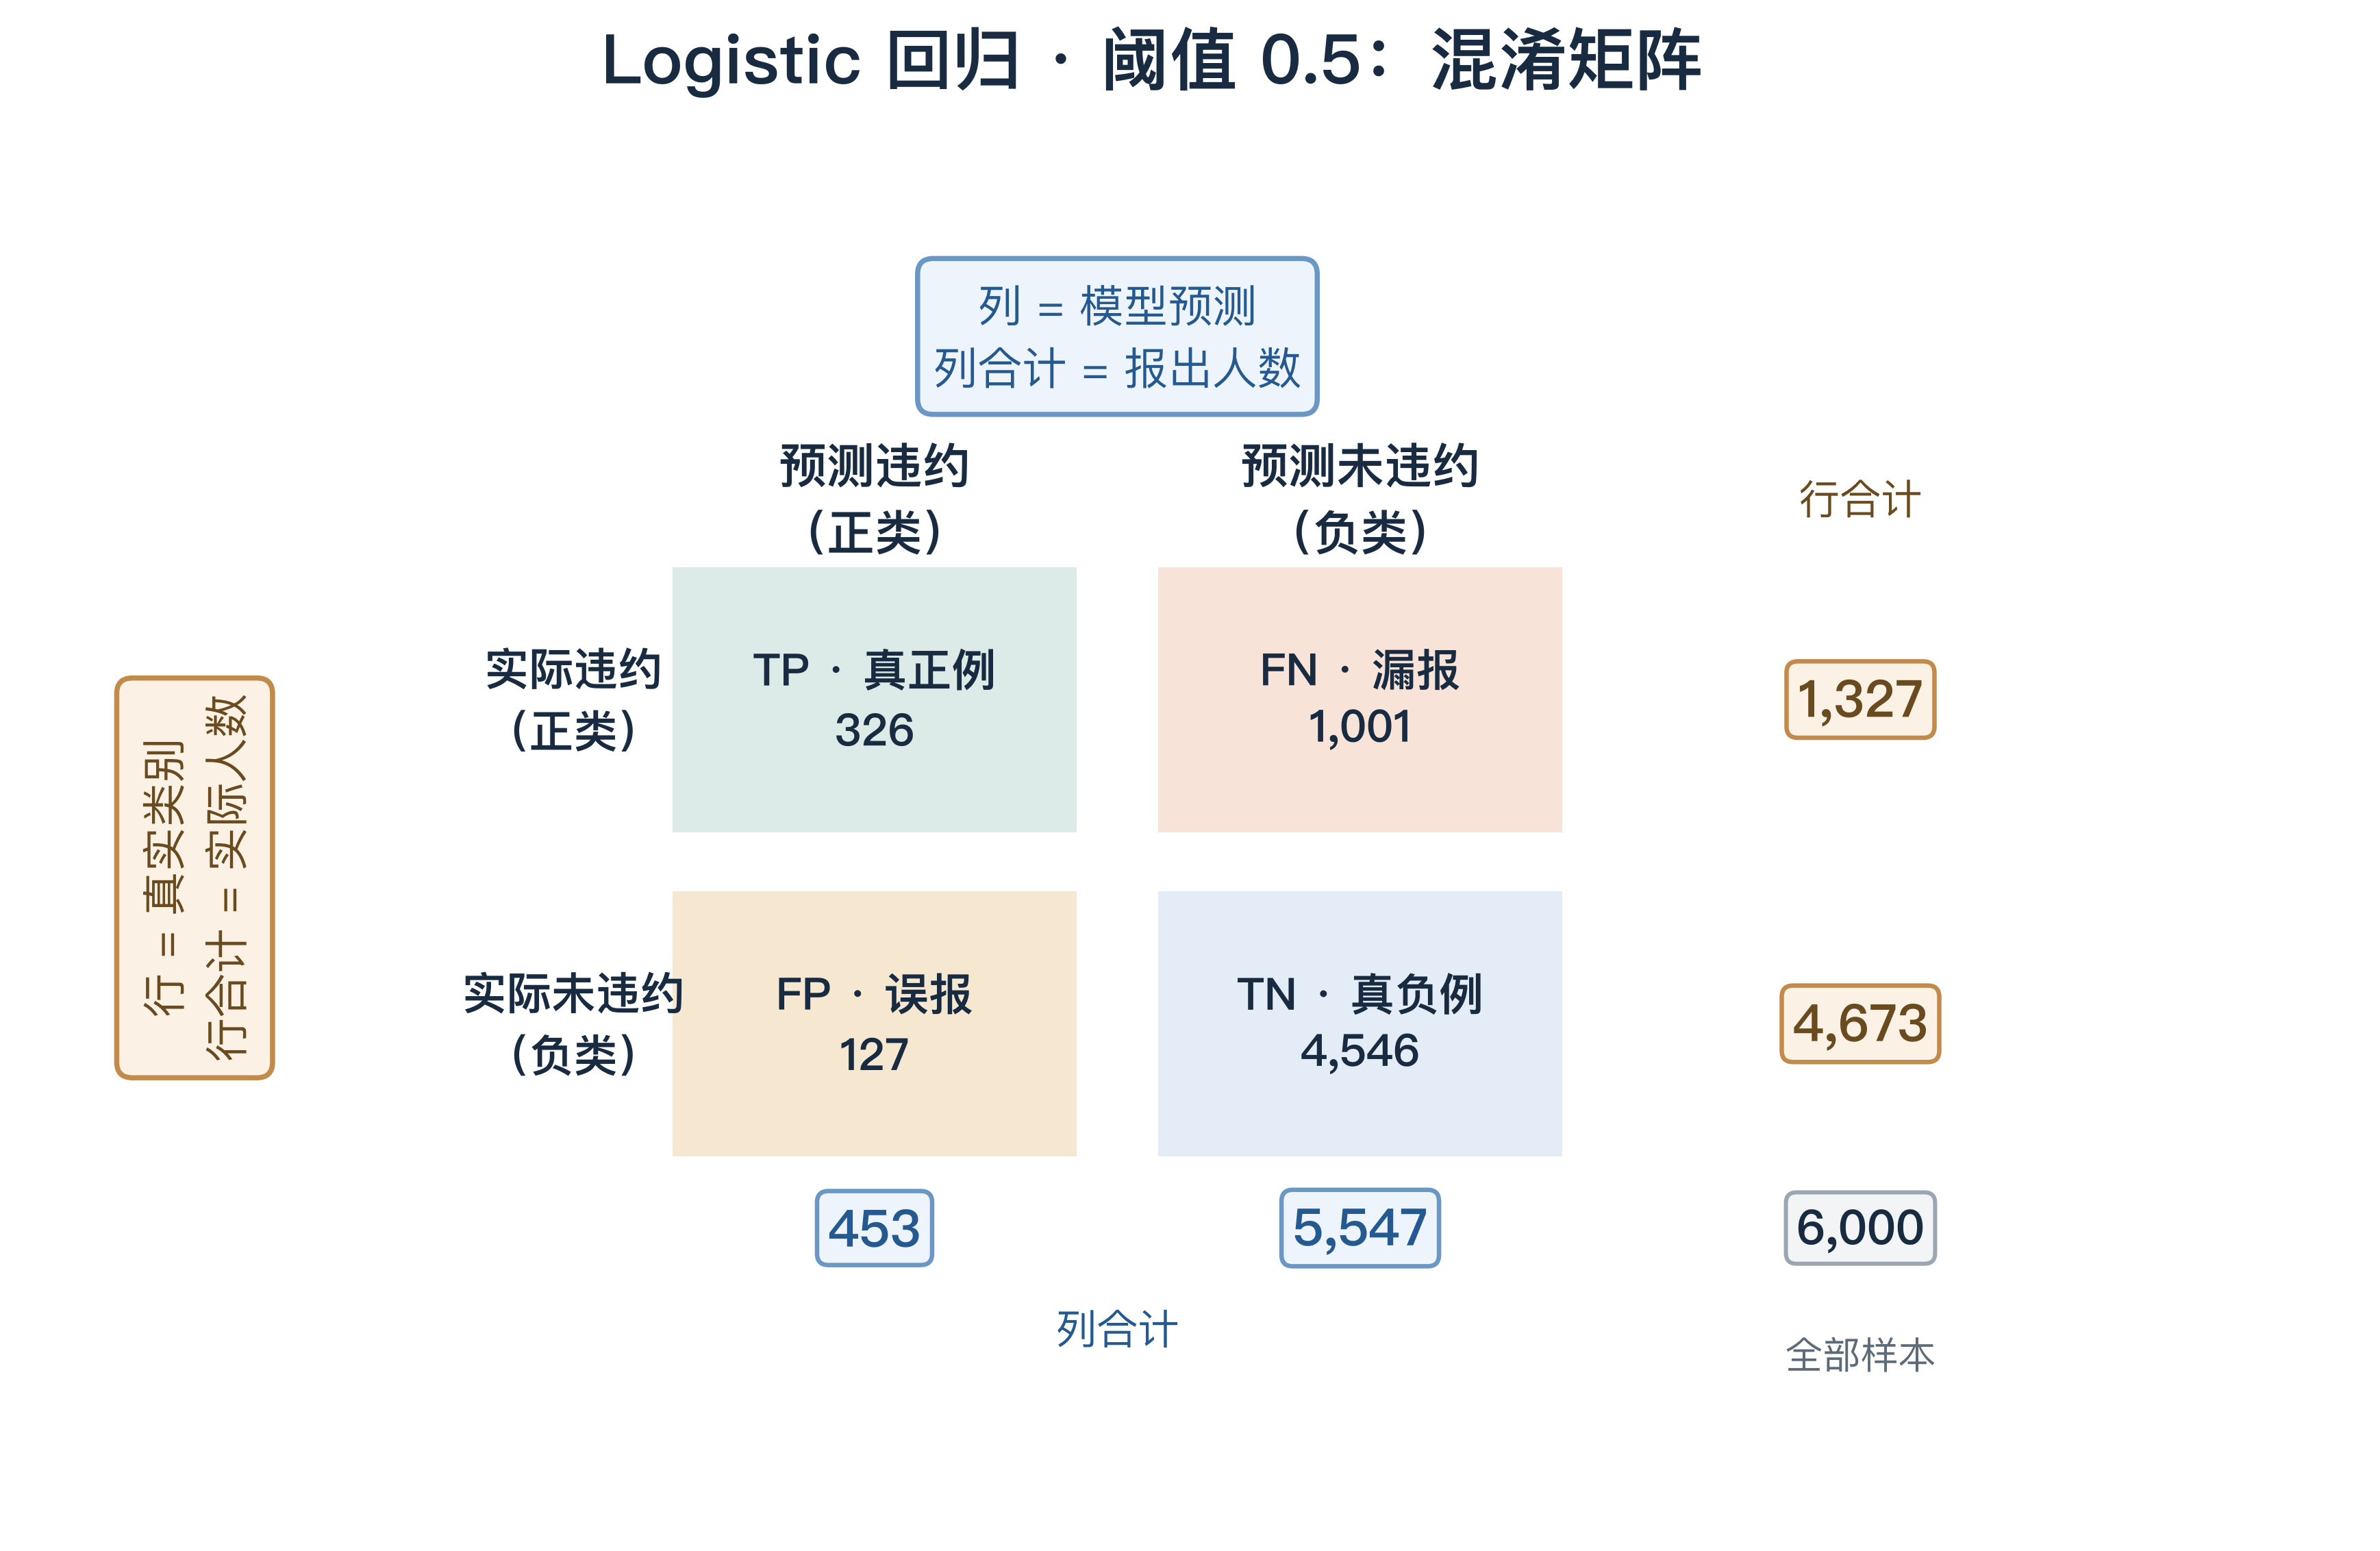

In [15]:
plot_confusion_counts(tp, fn, fp, tn, asset_dir / "lab05-confusion-matrix.png")

### 阈值如何影响分类结果

保持模型与预测概率不变，只改变“概率≥阈值”的判断规则。Precision看报出名单，Recall看全部真实正类；Accuracy汇总两类的正确比例。这里用与课件相同的真实验证分数画图。

,阈值,Precision,Recall,Accuracy
10,0.1,0.2463,0.9043,0.3667
30,0.3,0.5712,0.4446,0.8033
50,0.5,0.7196,0.2457,0.8120
70,0.7,0.6667,0.0377,0.7830


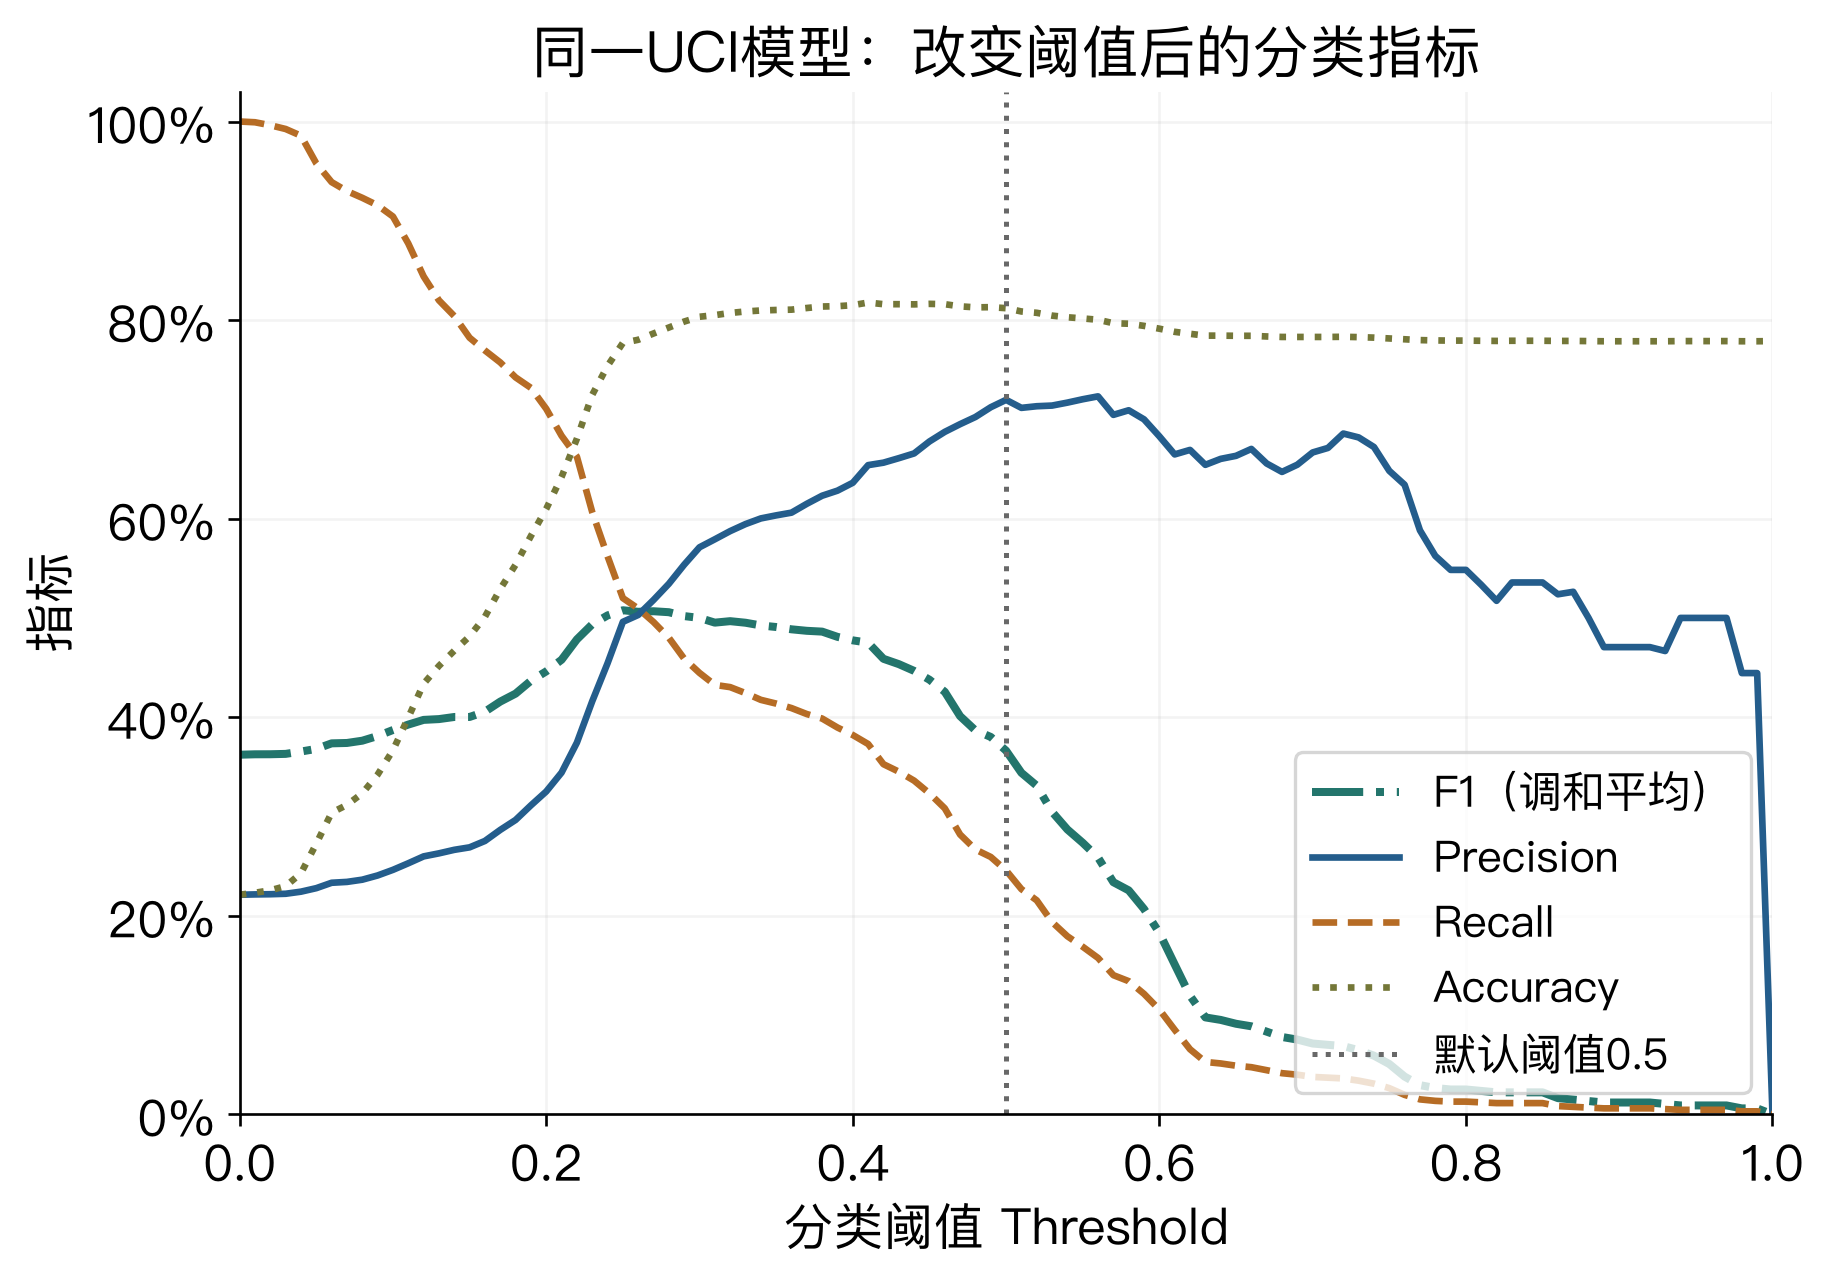

In [16]:
# [ref:l5-threshold-rates]
threshold_rows = []
for t in np.round(np.linspace(0, 1, 101), 2):
    labels = p_lr >= t
    threshold_rows.append({"阈值": t,
        "Precision": precision_score(actual, labels, zero_division=0),
        "Recall": recall_score(actual, labels), "Accuracy": accuracy_score(actual, labels)})
threshold_rates = pd.DataFrame(threshold_rows)
display(threshold_rates.loc[threshold_rates["阈值"].isin([.1, .3, .5, .7])])
plot_threshold_rates(threshold_rates, path=asset_dir / "lab05-threshold-rates.png")

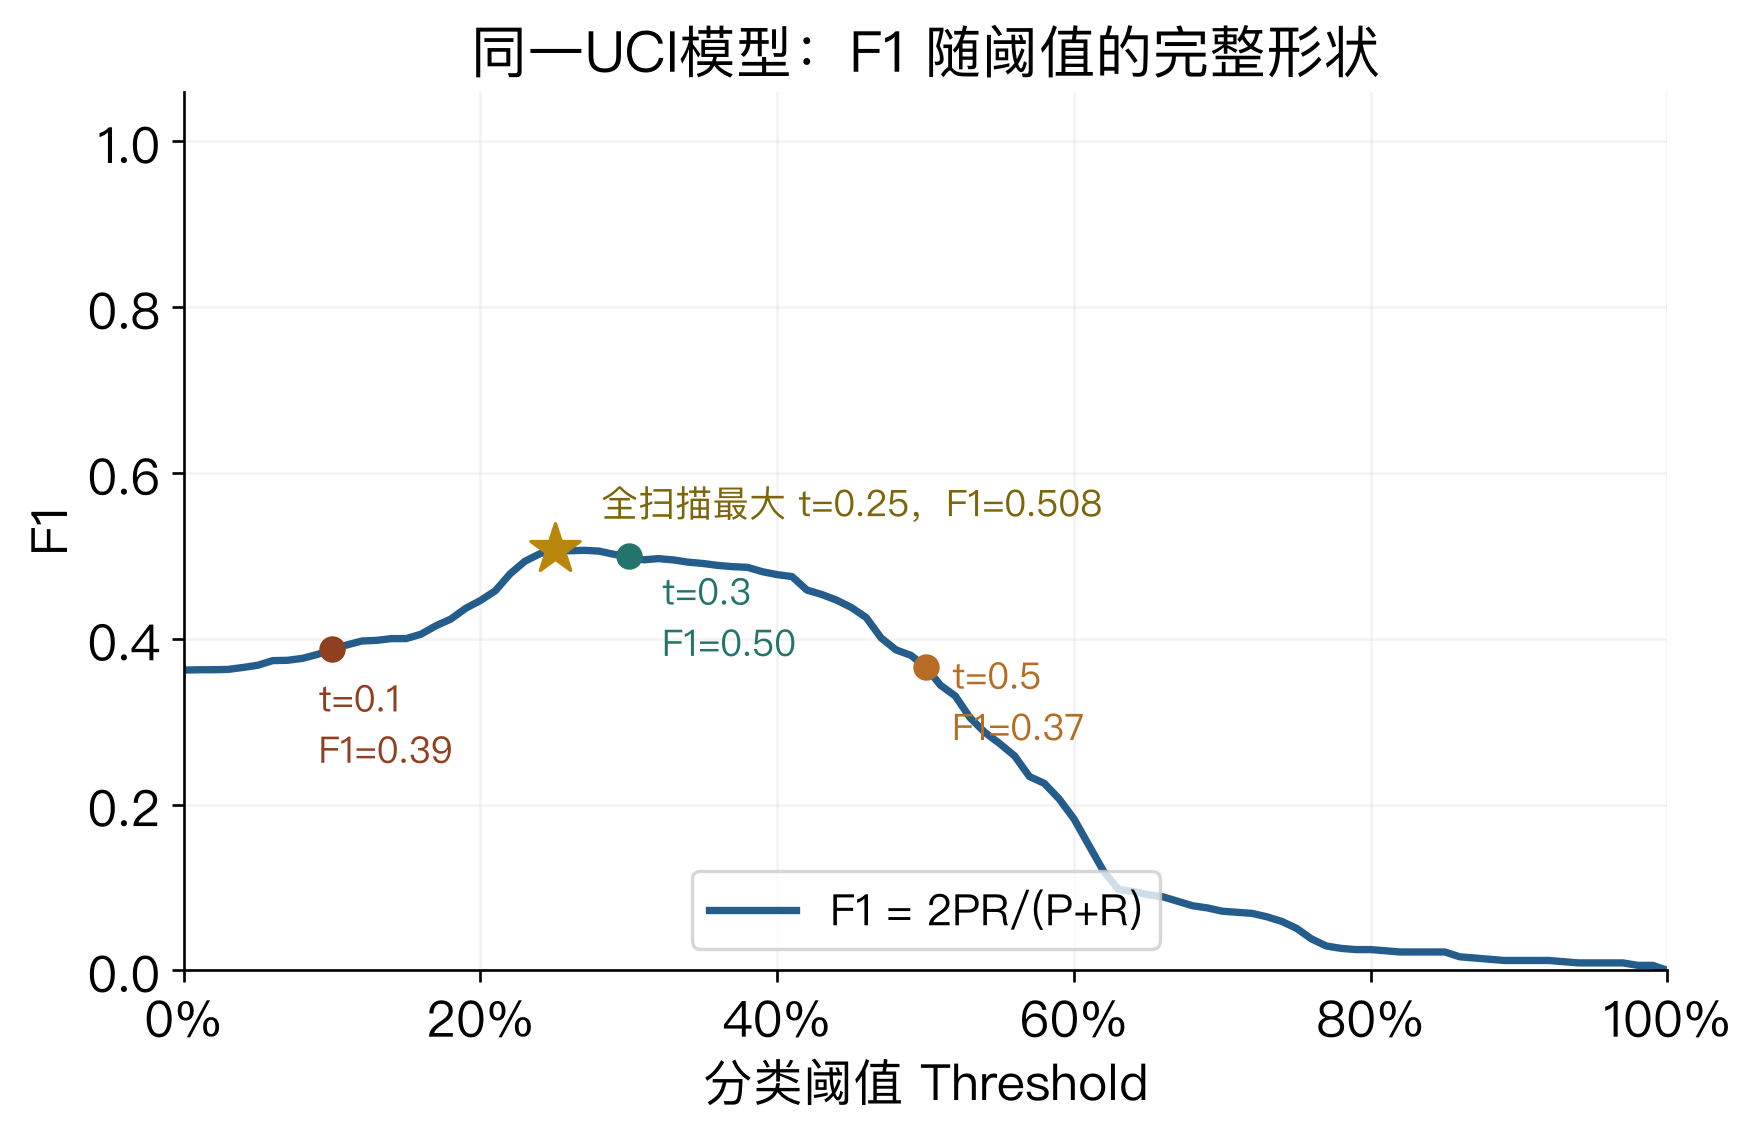

In [17]:
# [ref:l5-f1-threshold-curve]
plot_f1_threshold(threshold_rates, path=asset_dir / "lab05-f1-threshold.png")

⚖️ 用阈值0.5的准确率能判断前600名的核查效果吗？不能；分类、排序与固定名额分别对应不同问题。

<a id="lab05-roc"></a>
## 10｜真实数据上的ROC

同一个模型扫所有不同分数阈值，观察FPR与TPR。AUC不指定某个工作阈值，也没有把误报与漏报代价纳入目标。

TPR的分母是全部真实违约客户（1,327人）；FPR的分母是全部真实未违约客户（4,673人）。降低阈值，新增真实正类使点上移，新增真实负类使点右移。

In [18]:
# [ref:l5-roc]
lr_fpr, lr_tpr, lr_thresholds = roc_curve(actual, p_lr)
lr_auc = roc_auc_score(actual, p_lr)
print("验证ROC-AUC:", lr_auc)
display(pd.DataFrame({"threshold": lr_thresholds[:6], "FPR": lr_fpr[:6], "TPR": lr_tpr[:6]}))

验证ROC-AUC: 0.7199528920084933


,threshold,FPR,TPR
0,inf,0.0000,0.0000
1,0.9939,0.0000,0.0008
2,0.9938,0.0000,0.0015
3,0.9937,0.0004,0.0015
4,0.9937,0.0004,0.0023
5,0.9923,0.0011,0.0023


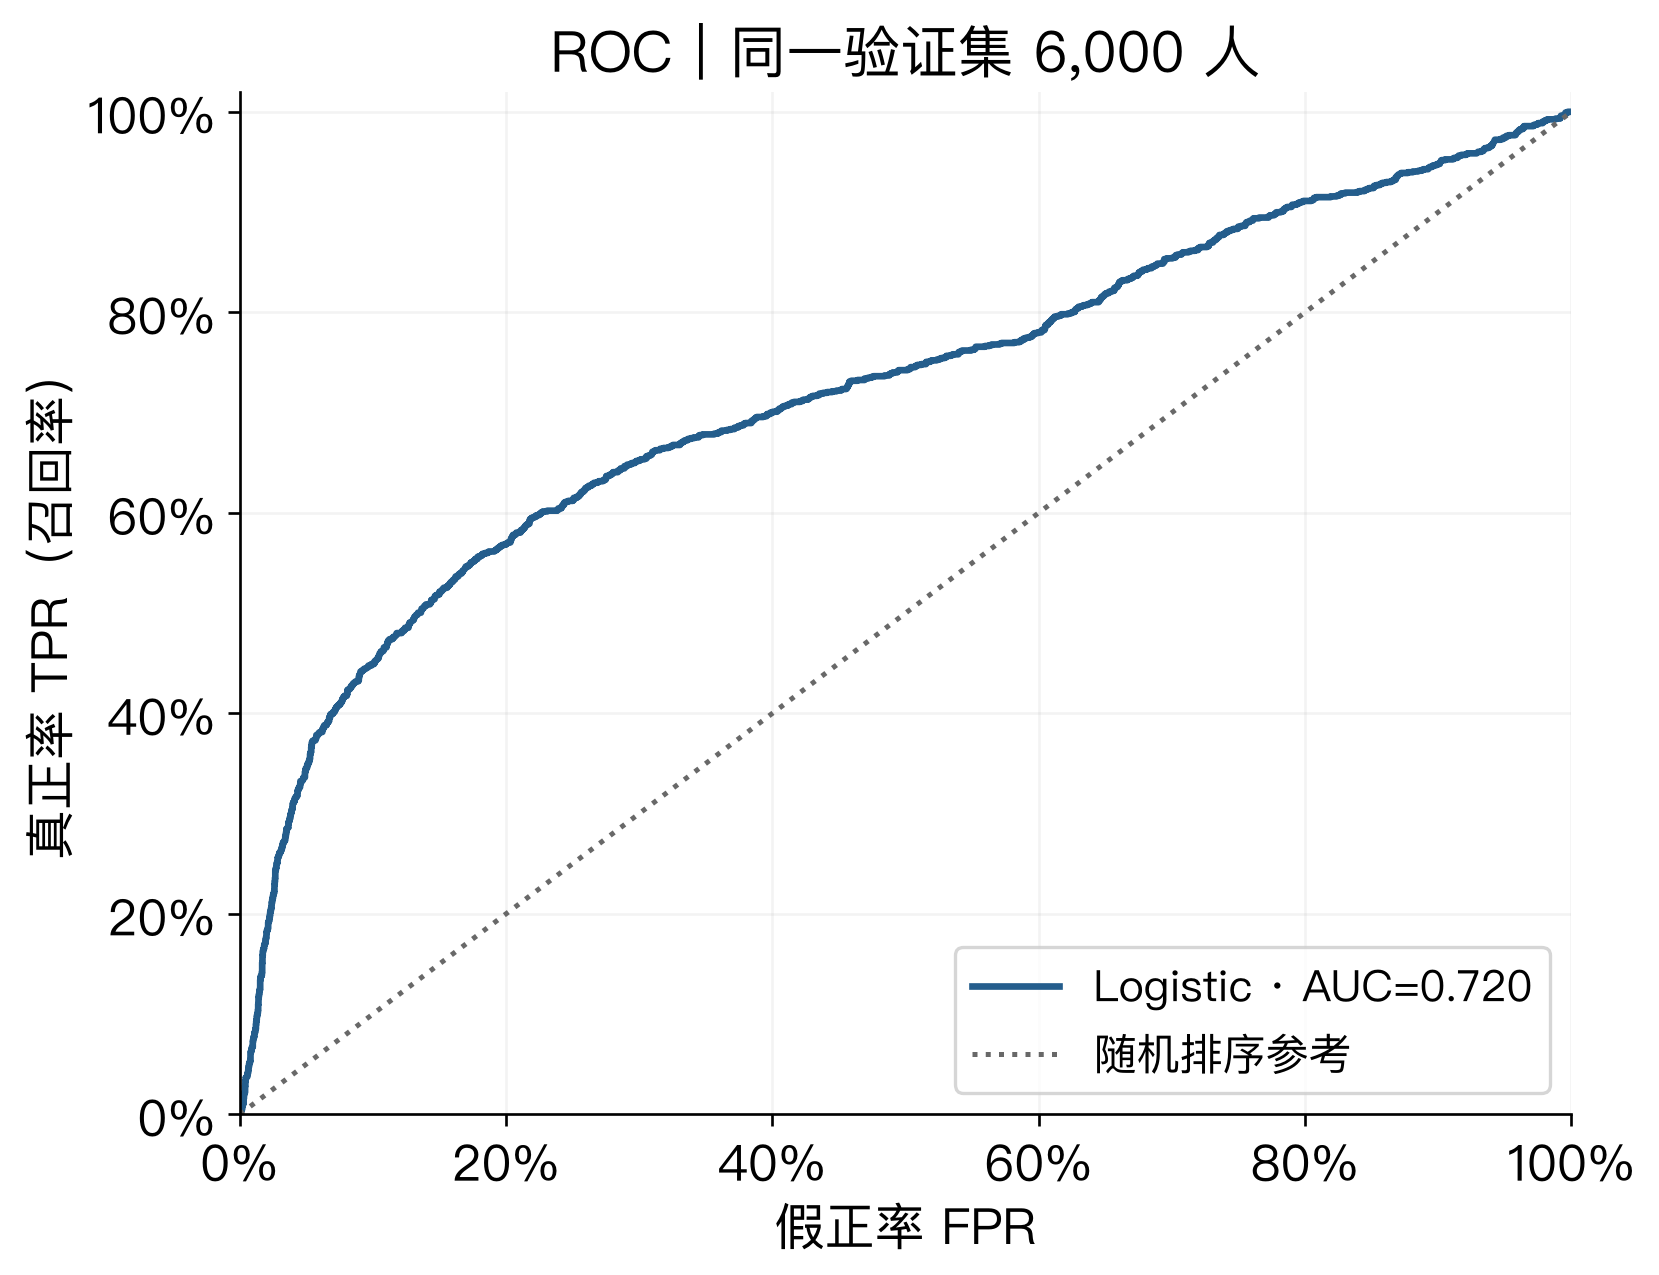

In [19]:
plot_roc(actual, {"LR": p_lr})

### 用UCI核对AUC的两种计算方法

沿相邻ROC点累加面积：$\Delta\mathrm{FPR}\times(\mathrm{TPR}_{j-1}+\mathrm{TPR}_j)/2$。水平段是矩形，竖直段宽为0。同一结果也可以用正负配对核对：正类分数更高得1，同分得0.5，更低得0。下面核对全部6,201,071对，结果约为0.720。

In [20]:
# [ref:l5-uci-auc-check]
from sklearn.metrics import auc
full_fpr, full_tpr, _ = roc_curve(actual, p_lr, drop_intermediate=False)
areas = np.diff(full_fpr) * (full_tpr[:-1] + full_tpr[1:]) / 2
positive_scores = p_lr[actual == 1]
negative_scores = p_lr[actual == 0]
credits = (positive_scores[:, None] > negative_scores).astype(float)
credits += .5 * (positive_scores[:, None] == negative_scores)
print("相邻区间面积之和:", areas.sum(), "sklearn auc:", auc(full_fpr, full_tpr))
print("全部正负配对平均得分:", credits.mean(), "配对数:", credits.size)
assert np.isclose(areas.sum(), lr_auc) and np.isclose(credits.mean(), lr_auc)

相邻区间面积之和: 0.7199528920084934 sklearn auc: 0.7199528920084934
全部正负配对平均得分: 0.7199528920084933 配对数: 6201071


<a id="lab05-pr"></a>
## 11｜PR关注被选中的人

查准率-召回率曲线（precision-recall curve，PR）同样扫阈值，横轴召回率，纵轴查准率。参考水平线取验证集正类率；随机排序的查准率在期望上接近该比例，有限样本并不保证每个点恰好落在线上。

In [21]:
# [ref:l5-pr]
from sklearn.metrics import precision_recall_curve, average_precision_score
lr_precision, lr_recall, lr_pr_thresholds = precision_recall_curve(actual, p_lr)
lr_ap = average_precision_score(actual, p_lr)
print("PR参考正类率:", positive_rate, "AP:", lr_ap)
display(pd.DataFrame({"threshold": lr_pr_thresholds[:5], "precision": lr_precision[:5], "recall": lr_recall[:5]}))

PR参考正类率: 0.22116666666666668 AP: 0.4927017623490143


,threshold,precision,recall
0,1.8744e-05,0.2212,1.0
1,4.8163e-04,0.2212,1.0
2,5.5816e-04,0.2212,1.0
3,1.1582e-03,0.2213,1.0
4,2.2093e-03,0.2213,1.0


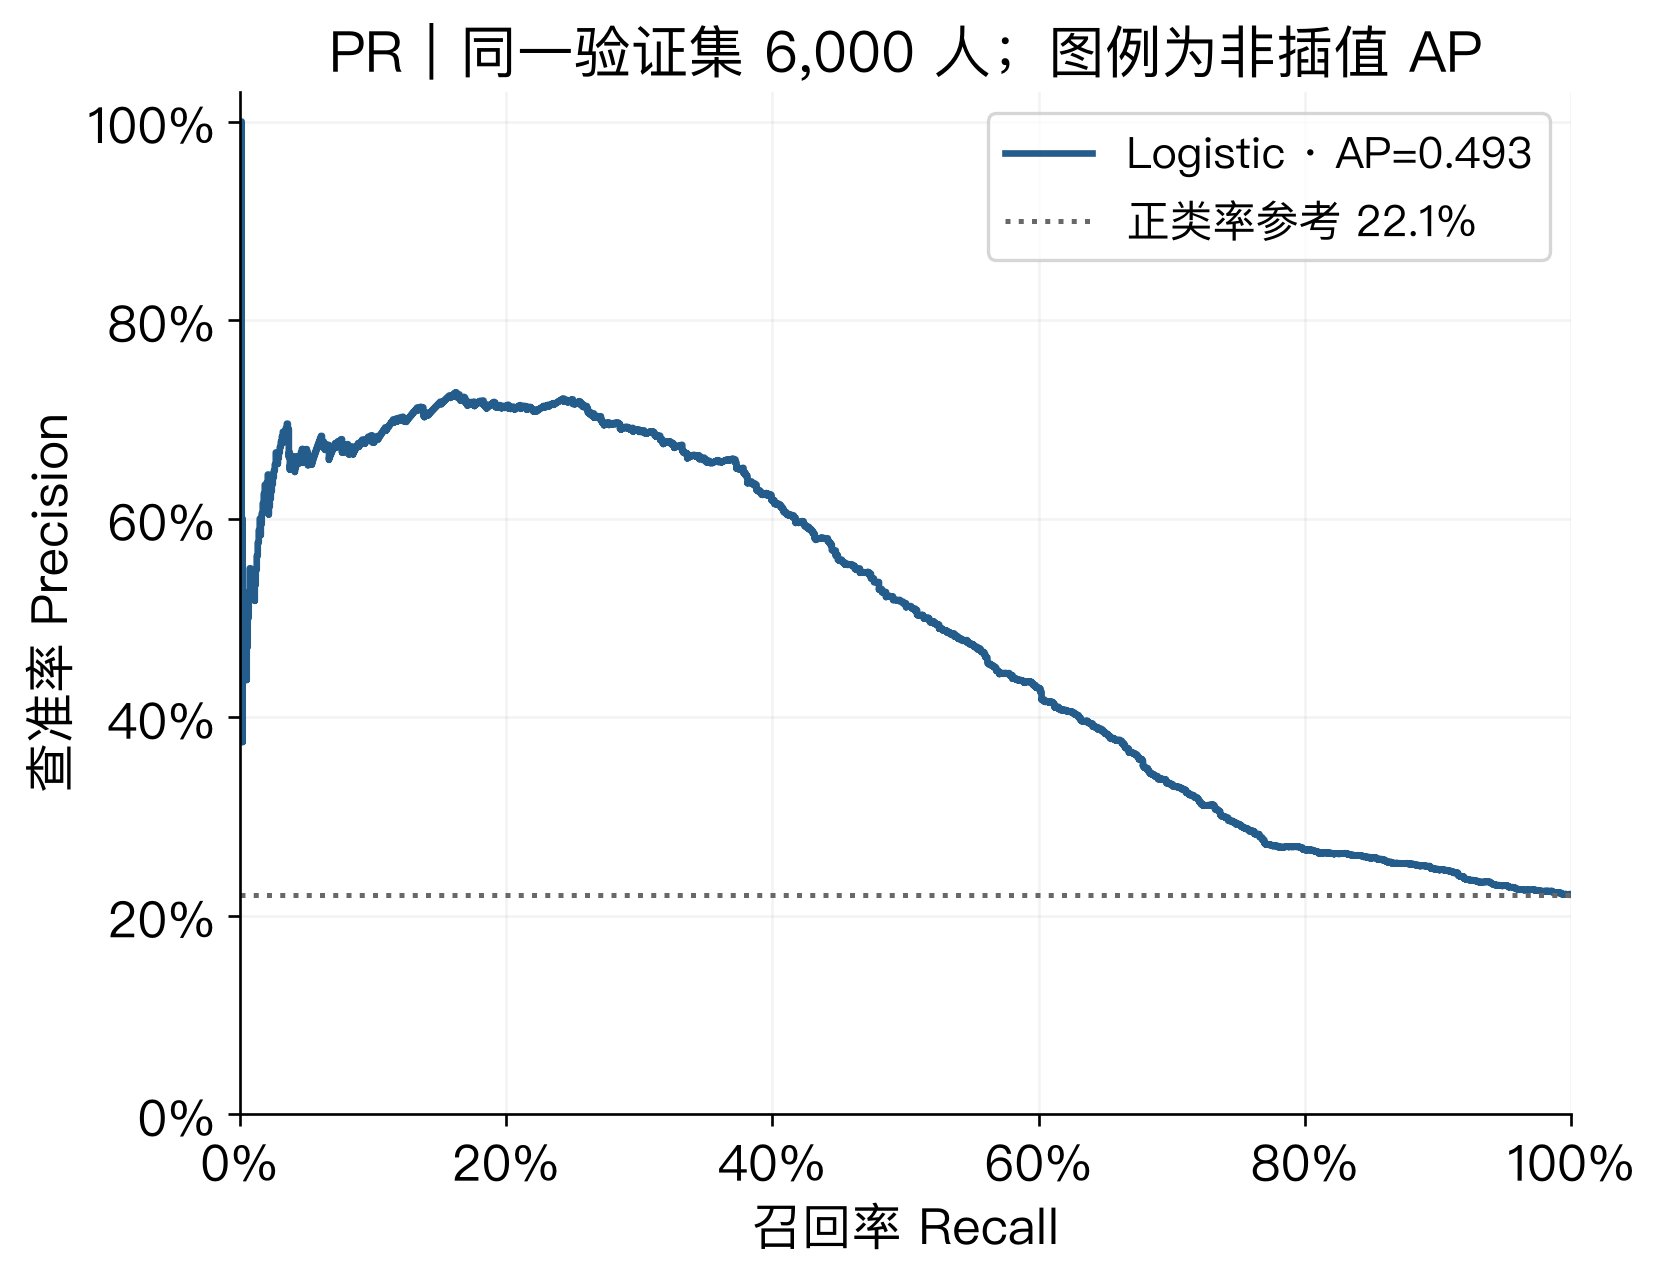

In [22]:
plot_pr(actual, {"LR": p_lr}, baseline=positive_rate)

## 12｜AP：按召回增量汇总查准率

平均查准率（Average Precision, AP）为 $\mathrm{AP}=\sum_j(R_j-R_{j-1})P_j$。每一段宽为Recall增加量，高为该步Precision；将矩形面积相加，得到本次UCI的AP约0.493。

`precision_recall_curve`返回的Recall从1降到0，所以下面的`np.diff`为负，需要加负号。先看一个区间的宽和高，再核对总和。

In [23]:
# [ref:l5-ap]
ap_from_steps = -np.sum(np.diff(lr_recall) * lr_precision[:-1])
print("按步长计算:", ap_from_steps, "接口AP:", lr_ap)
# 核对召回步长加权与接口AP一致。
assert np.isclose(ap_from_steps, lr_ap)
demo_precision, demo_recall, _ = precision_recall_curve(demo_y, demo_p)
print("四样本AP:", average_precision_score(demo_y, demo_p))
# 核对四样本PR阶梯面积等于5/6。
assert np.isclose(-np.sum(np.diff(demo_recall) * demo_precision[:-1]), 5/6)

按步长计算: 0.4927017623490143 接口AP: 0.4927017623490143
四样本AP: 0.8333333333333333


In [24]:
# [ref:l5-ap-intervals]
ap_intervals = pd.DataFrame({
    "Recall起点": lr_recall[1:], "Recall终点": lr_recall[:-1],
    "Recall增量": -np.diff(lr_recall), "Precision": lr_precision[:-1],
})
ap_intervals["面积贡献"] = ap_intervals["Recall增量"] * ap_intervals["Precision"]
display(ap_intervals.query("Recall增量 > 0").sort_values("Recall起点").head(5))
print("全部区间贡献之和:", ap_intervals["面积贡献"].sum())

,Recall起点,Recall终点,Recall增量,Precision,面积贡献
5809,0.0000,0.0008,0.0008,1.0000,0.0008
5808,0.0008,0.0015,0.0008,1.0000,0.0008
5805,0.0015,0.0023,0.0008,0.6000,0.0005
5801,0.0023,0.0030,0.0008,0.4444,0.0003
5800,0.0030,0.0038,0.0008,0.5000,0.0004


全部区间贡献之和: 0.4927017623490143


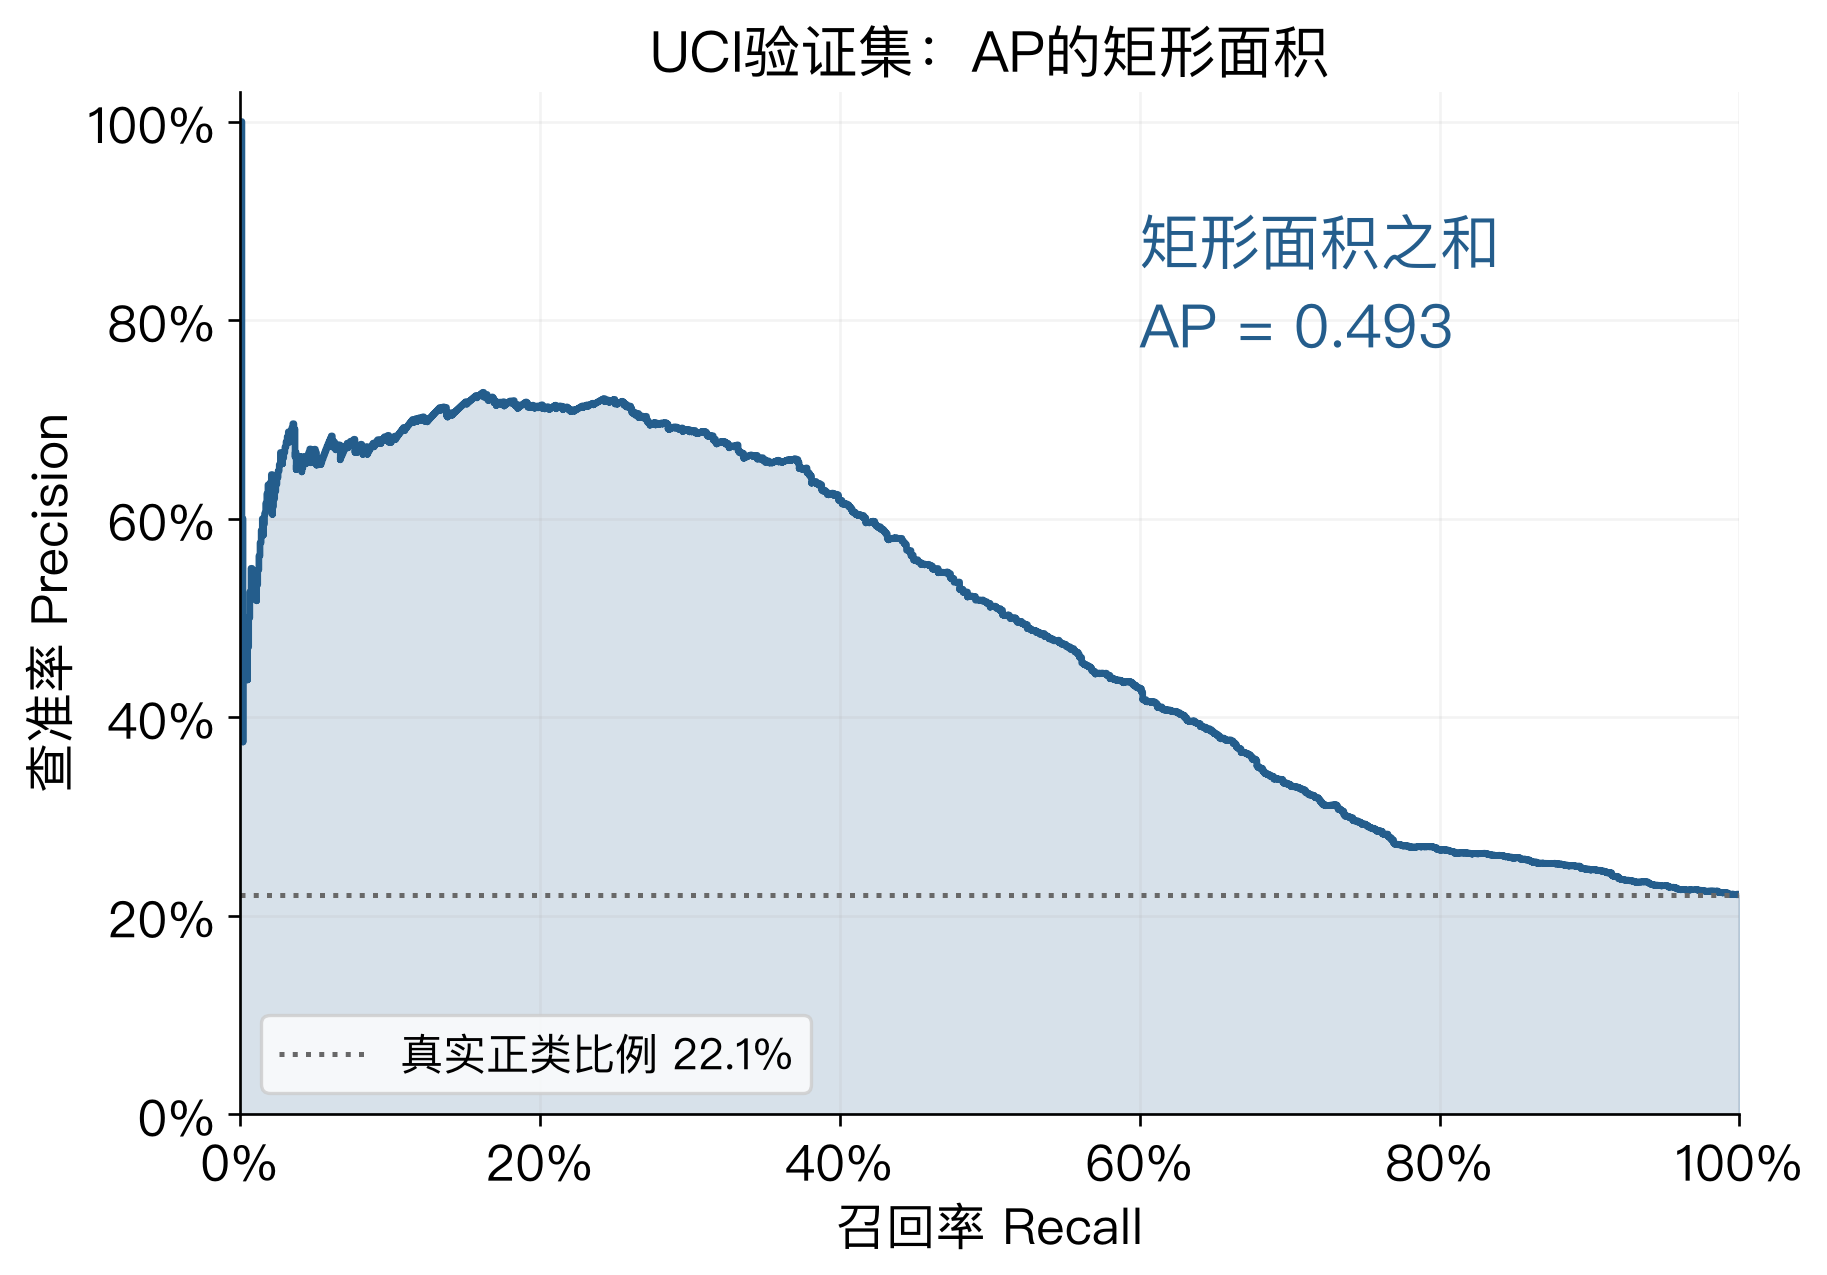

In [25]:
plot_ap_area(lr_precision, lr_recall, lr_ap, positive_rate)

🧮 四样本AP为什么是(1+2/3)/2=5/6，而ROC-AUC是3/4？两者对不同的排序表现加权，不能互换名称。

### 扩展阅读：平均精度均值（mean Average Precision, mAP）

多个类别分别计算AP，再取平均。例如猫AP=0.8、狗AP=0.6，则mAP=0.7。目标检测还需检查预测框与真实框是否匹配：交并比（Intersection over Union, IoU）衡量两框重叠程度。COCO会进一步汇总多个IoU阈值下的结果，因此比较mAP时要确认评价规则相同。

本章只做二分类AP，不训练目标检测模型。[COCO评价说明](https://cocodataset.org/dataset/detection-eval.htm)。

<a id="lab05-base-rate"></a>
## 13｜基本率变化思想实验

固定TPR=0.8、FPR=0.1，假设只有人群正类率π变化。根据条件概率：

$$\mathrm{Precision}=\frac{TPR\,\pi}{TPR\,\pi+FPR(1-\pi)}.$$

用π=0.2及0.01对照。这是保持两项条件率不变的假设思想实验，不是UCI真实部署结果，也不保证部署时TPR/FPR保持不变。

In [26]:
# [ref:l5-base-rate]
base_rate_table = pd.DataFrame({"pi": [.2, .01]})
base_rate_table["TPR"] = .8
base_rate_table["FPR"] = .1
base_rate_table["precision"] = (.8 * base_rate_table["pi"]) / (.8 * base_rate_table["pi"] + .1 * (1 - base_rate_table["pi"]))
display(base_rate_table)

,pi,TPR,FPR,precision
0,0.20,0.8,0.1,0.6667
1,0.01,0.8,0.1,0.0748


基本率从20%降到1%时，查准率从约66.7%降到7.48%。🧮 两组ROC工作点相同，查准率为什么差这么多？真实负类占比增加，误报在被选中的人中占了更大比例。

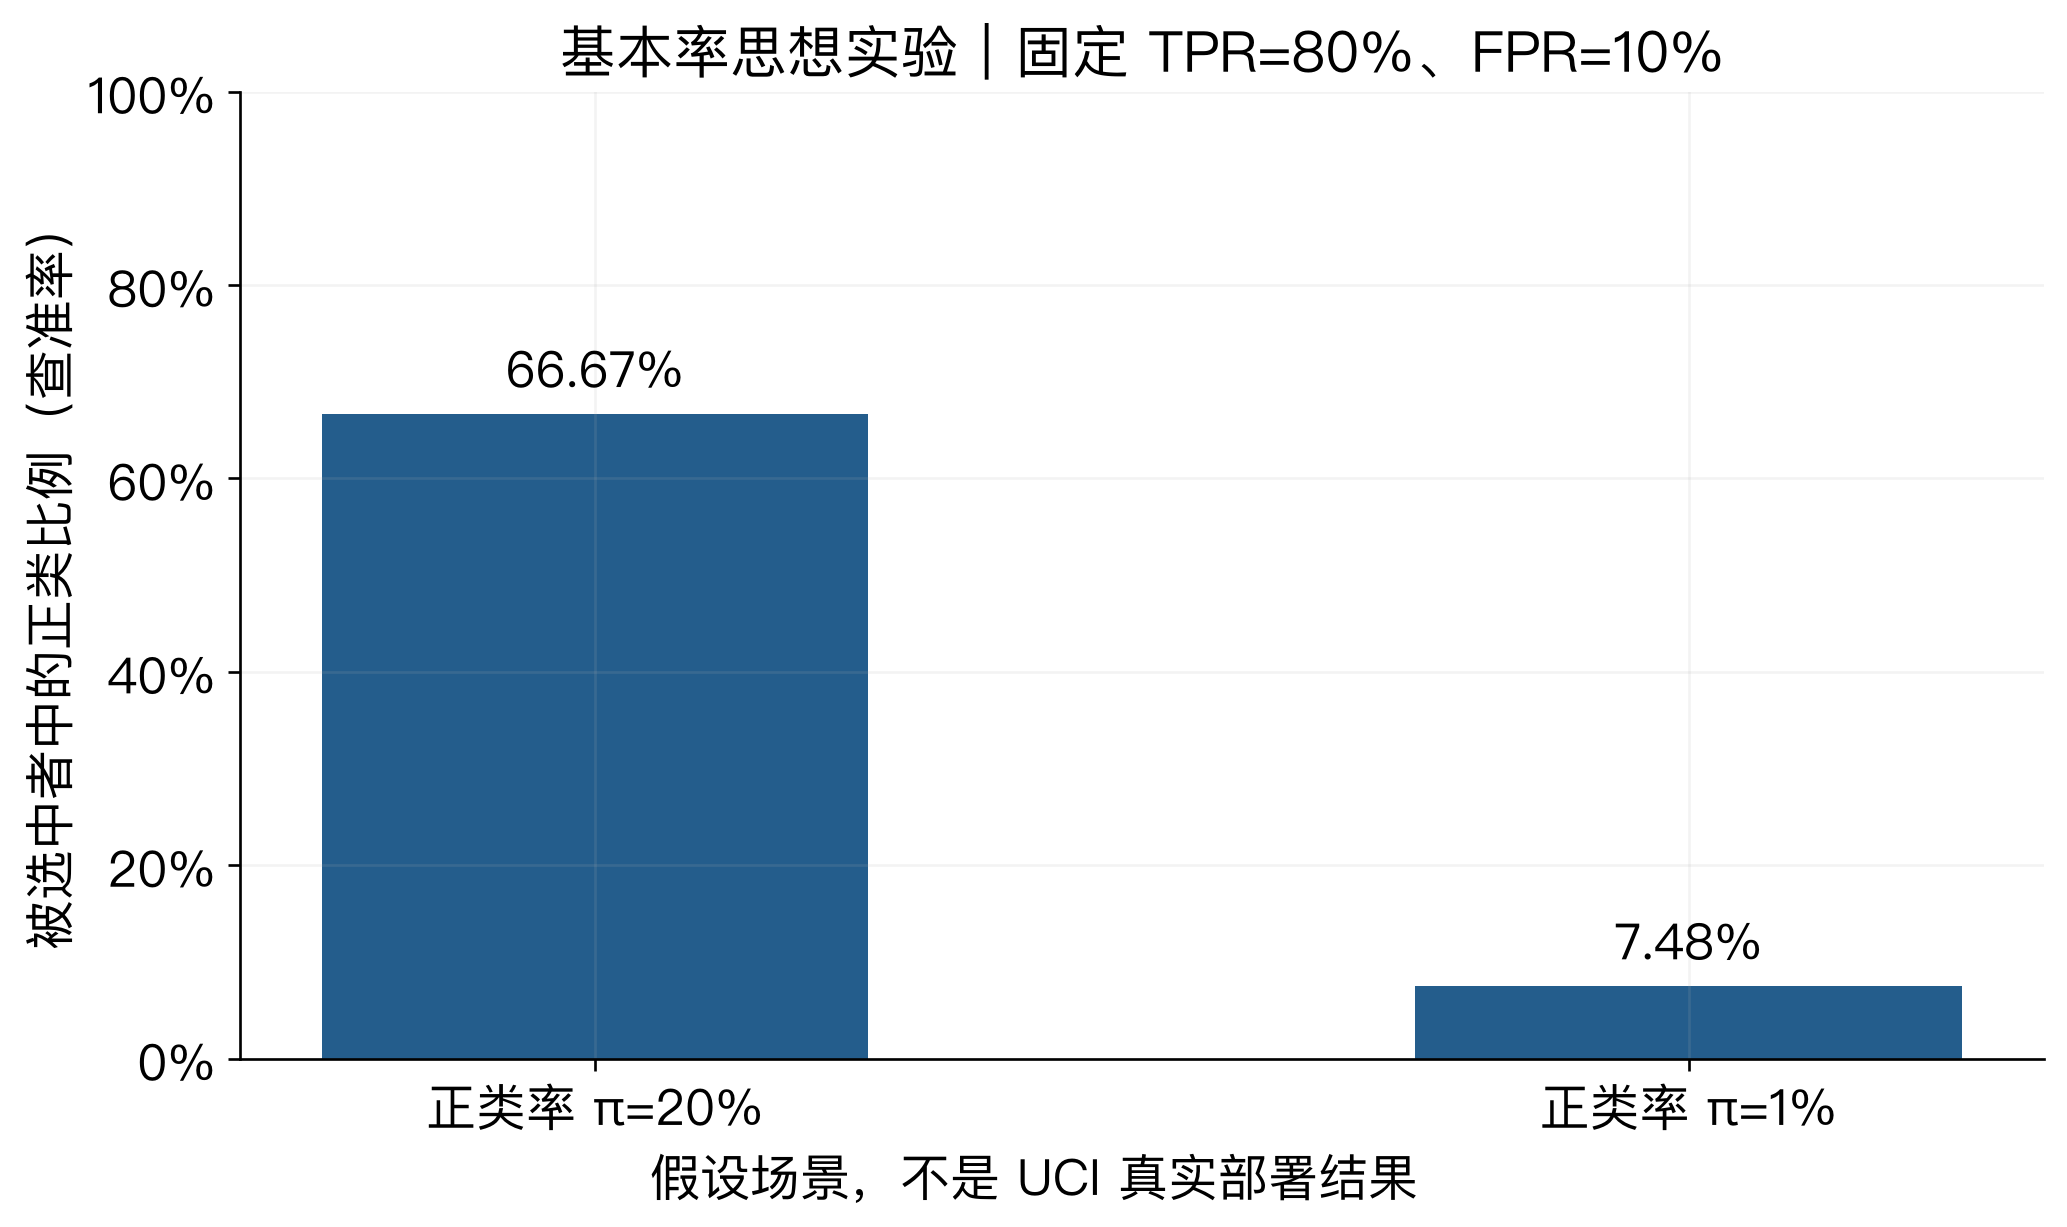

In [27]:
plot_base_rate(base_rate_table, path=asset_dir / "lab05-eval-base-rate.png")

<a id="lab05-monotonic"></a>
## 14｜改变概率而不改排序

ROC-AUC与AP是排序指标，不检查概率数值是否准确。四样本原概率为0.9、0.7、0.4、0.2，变换后约为0.988、0.845、0.308、0.0588；大小关系完全相同，但概率数值不同，因此ROC-AUC与AP不变并不代表概率可信。

**延伸实现**：下面用严格单调变换 $p'=\mathrm{sigmoid}(2\,\mathrm{logit}(p))$，其中 $\mathrm{logit}(p)=\log[p/(1-p)]$。对于0<p<1，变换让概率远离0.5，但保持大小关系与并列。这是上述现象的实现演示，不是校准修正，也不保证改善概率质量。

In [28]:
# [ref:l5-monotonic-transform]
from scipy.special import expit, logit
# 核对概率位于logit的有效区间内。
assert ((p_lr > 0) & (p_lr < 1)).all()
p_changed = expit(2 * logit(p_lr))
display(pd.DataFrame({"p": p_lr[:6], "sigmoid(2logit(p))": p_changed[:6]}))
# 核对单调变换保持稳定排序及并列顺序。
assert np.array_equal(np.argsort(-p_lr, kind="stable"), np.argsort(-p_changed, kind="stable"))
# 先核对课件中的四名示例客户，再读真实UCI结果。
display(pd.DataFrame({"客户": list("ABCD"), "原概率": demo_p, "变换后概率": expit(2 * logit(demo_p))}))

,p,sigmoid(2logit(p))
0,0.2473,0.0974
1,0.1390,0.0254
2,0.0536,0.0032
3,0.1003,0.0123
4,0.0922,0.0102
5,0.4904,0.4809


,客户,原概率,变换后概率
0,A,0.9,0.9878
1,B,0.7,0.8448
2,C,0.4,0.3077
3,D,0.2,0.0588


<a id="lab05-calibration"></a>
## 15｜等宽十箱看可靠性

**教学假设**：假设100名借款人的预测违约风险均为70%，后来实际有40名违约，则这组实际违约比例为40/100=40%。预测的70%比实际的40%高30个百分点，因此这组风险被高估；这里只判断这组，不能据此判断整个模型的校准情况。

概率校准（probability calibration）关注一群报出相近概率的人，实际正类比例是否接近该概率。可靠性图（reliability diagram）将每箱平均概率与实际正类比例比较。衔接到下面已有的真实UCI结果：[0.2,0.3)箱有n=1867人，meanp≈0.235，observed≈0.189，即这箱平均预测风险约23.5%，实际违约比例约18.9%。

固定10个等宽区间：[0,0.1)、…、[0.9,1]。每箱记录人数n、平均概率meanp与实际比例observed；空箱保留为NaN。

In [29]:
# [ref:l5-calibration]
edges = np.linspace(0, 1, 11)
calibration_tables = {}
for name, p in [("LR", p_lr), ("单调变换", p_changed)]:
    bin_id = np.minimum(np.searchsorted(edges, p, side="right") - 1, 9)
    frame = pd.DataFrame({"bin": bin_id, "p": p, "y": actual})
    table = frame.groupby("bin").agg(n=("y", "size"), meanp=("p", "mean"), observed=("y", "mean"))
    table = table.reindex(range(10))
    table["n"] = table["n"].fillna(0).astype(int)
    table.insert(0, "interval", [f"[{a:.1f},{b:.1f}{']' if b == 1 else ')'}" for a,b in zip(edges[:-1], edges[1:])])
    calibration_tables[name] = table
display(calibration_tables["LR"])

,interval,n,meanp,observed
bin,,,,
0,"[0.0,0.1)",1127,0.0609,0.1127
1,"[0.1,0.2)",1973,0.1479,0.1303
2,"[0.2,0.3)",1867,0.2348,0.1891
3,"[0.3,0.4)",236,0.3478,0.3517
4,"[0.4,0.5)",344,0.4488,0.5262
5,"[0.5,0.6)",248,0.5460,0.7500
6,"[0.6,0.7)",130,0.6265,0.6923
7,"[0.7,0.8)",44,0.7461,0.7500
8,"[0.8,0.9)",14,0.8517,0.6429


### 分组偏差汇总：期望校准误差（Expected Calibration Error，ECE）

本课采用正类概率校准：按预测违约概率 $p=P(\text{违约}\mid x)$ 分成10个等宽箱，沿用上一格的区间与6,000名验证样本。令 $B_m$ 为第 $m$ 箱，$n_m$ 为箱内人数，$\bar p_m$ 为平均预测概率（`meanp`），$\bar y_m$ 为实际违约比例（`observed`），则

$$\mathrm{ECE}=\sum_{m:\,n_m>0}\frac{n_m}{6000}\left|\bar p_m-\bar y_m\right|.$$

组差 `signed_gap = meanp - observed` 的正号表示高估、负号表示低估。ECE取绝对值再按人数加权，避免高估与低估抵消；空箱忽略。下表依次展示组差、绝对组差、权重与贡献，贡献之和就是ECE。分箱数量与边界会影响结果，比较时须使用同一规则。ECE是评估汇总，不是本实验的训练损失，也不是概率修正方法。

**论文延伸**：Guo等在ICML 2017的 [On Calibration of Modern Neural Networks](https://proceedings.mlr.press/v70/guo17a.html) 中展示了现代网络可能更准确却过度自信的现象。温度缩放（temperature scaling）固定模型权重，用独立校准数据学习正温度 $T>0$，将输出分数（logits）除以 $T$ 后再输出概率。论文的多分类最高概率标签置信度（top-label confidence）ECE比较置信度与预测正确率；本课则比较正类概率与违约比例，两者口径须区分。该论文是校准研究的主流背景参考，不能据此认为ECE由该论文提出。

In [30]:
# [ref:l5-ece]
ece_table = calibration_tables["LR"].query("n > 0").copy()
ece_table["signed_gap"] = ece_table["meanp"] - ece_table["observed"]
ece_table["absolute_gap"] = ece_table["signed_gap"].abs()
ece_table["weight"] = ece_table["n"] / 6000
ece_table["contribution"] = ece_table["weight"] * ece_table["absolute_gap"]
display(ece_table)
ece = ece_table["contribution"].sum()
print(f"LR ECE = {ece:.6f}（{ece * 100:.6f} 个百分点）")

,interval,n,meanp,observed,signed_gap,absolute_gap,weight,contribution
bin,,,,,,,,
0,"[0.0,0.1)",1127,0.0609,0.1127,-0.0518,0.0518,0.1878,9.7324e-03
1,"[0.1,0.2)",1973,0.1479,0.1303,0.0176,0.0176,0.3288,5.8027e-03
2,"[0.2,0.3)",1867,0.2348,0.1891,0.0457,0.0457,0.3112,1.4217e-02
3,"[0.3,0.4)",236,0.3478,0.3517,-0.0039,0.0039,0.0393,1.5434e-04
4,"[0.4,0.5)",344,0.4488,0.5262,-0.0774,0.0774,0.0573,4.4353e-03
5,"[0.5,0.6)",248,0.5460,0.7500,-0.2040,0.2040,0.0413,8.4334e-03
6,"[0.6,0.7)",130,0.6265,0.6923,-0.0658,0.0658,0.0217,1.4267e-03
7,"[0.7,0.8)",44,0.7461,0.7500,-0.0039,0.0039,0.0073,2.8364e-05
8,"[0.8,0.9)",14,0.8517,0.6429,0.2089,0.2089,0.0023,4.8732e-04


LR ECE = 0.046140（4.613974 个百分点）


## 16｜同一批人比较分箱

变换后有人进入不同的概率箱，因此两条曲线不必经过同样的人群。可靠性图配人数子图一起读，稀疏箱可能更不稳定。人数n没有给出不确定性区间，本实验不画置信区间。

In [31]:
# [ref:l5-calibration-counts]
display(calibration_tables["单调变换"])
for name, table in calibration_tables.items():
    # 核对十箱人数覆盖全部验证客户。
    assert table["n"].sum() == len(actual)
    weighted_observed = (table["n"] * table["observed"].fillna(0)).sum() / len(actual)
    print(name, "箱人数合计:", table["n"].sum(), "加权实际正类率:", weighted_observed)
    # 核对按人数加权的实际比例与总体正类率一致。
    assert np.isclose(weighted_observed, positive_rate)

,interval,n,meanp,observed
bin,,,,
0,"[0.0,0.1)",4609,0.0402,0.1382
1,"[0.1,0.2)",452,0.1377,0.2854
2,"[0.2,0.3)",132,0.2532,0.3636
3,"[0.3,0.4)",171,0.3469,0.4854
4,"[0.4,0.5)",183,0.4437,0.5683
5,"[0.5,0.6)",143,0.5484,0.7133
6,"[0.6,0.7)",119,0.6529,0.7899
7,"[0.7,0.8)",100,0.7275,0.7000
8,"[0.8,0.9)",37,0.8555,0.6757


LR 箱人数合计: 6000 加权实际正类率: 0.22116666666666668
单调变换 箱人数合计: 6000 加权实际正类率: 0.22116666666666668


👀 某箱只有几个人时，点很靠近对角线足够证明模型已校准吗？不够；还需要考虑分箱口径及样本不确定性。

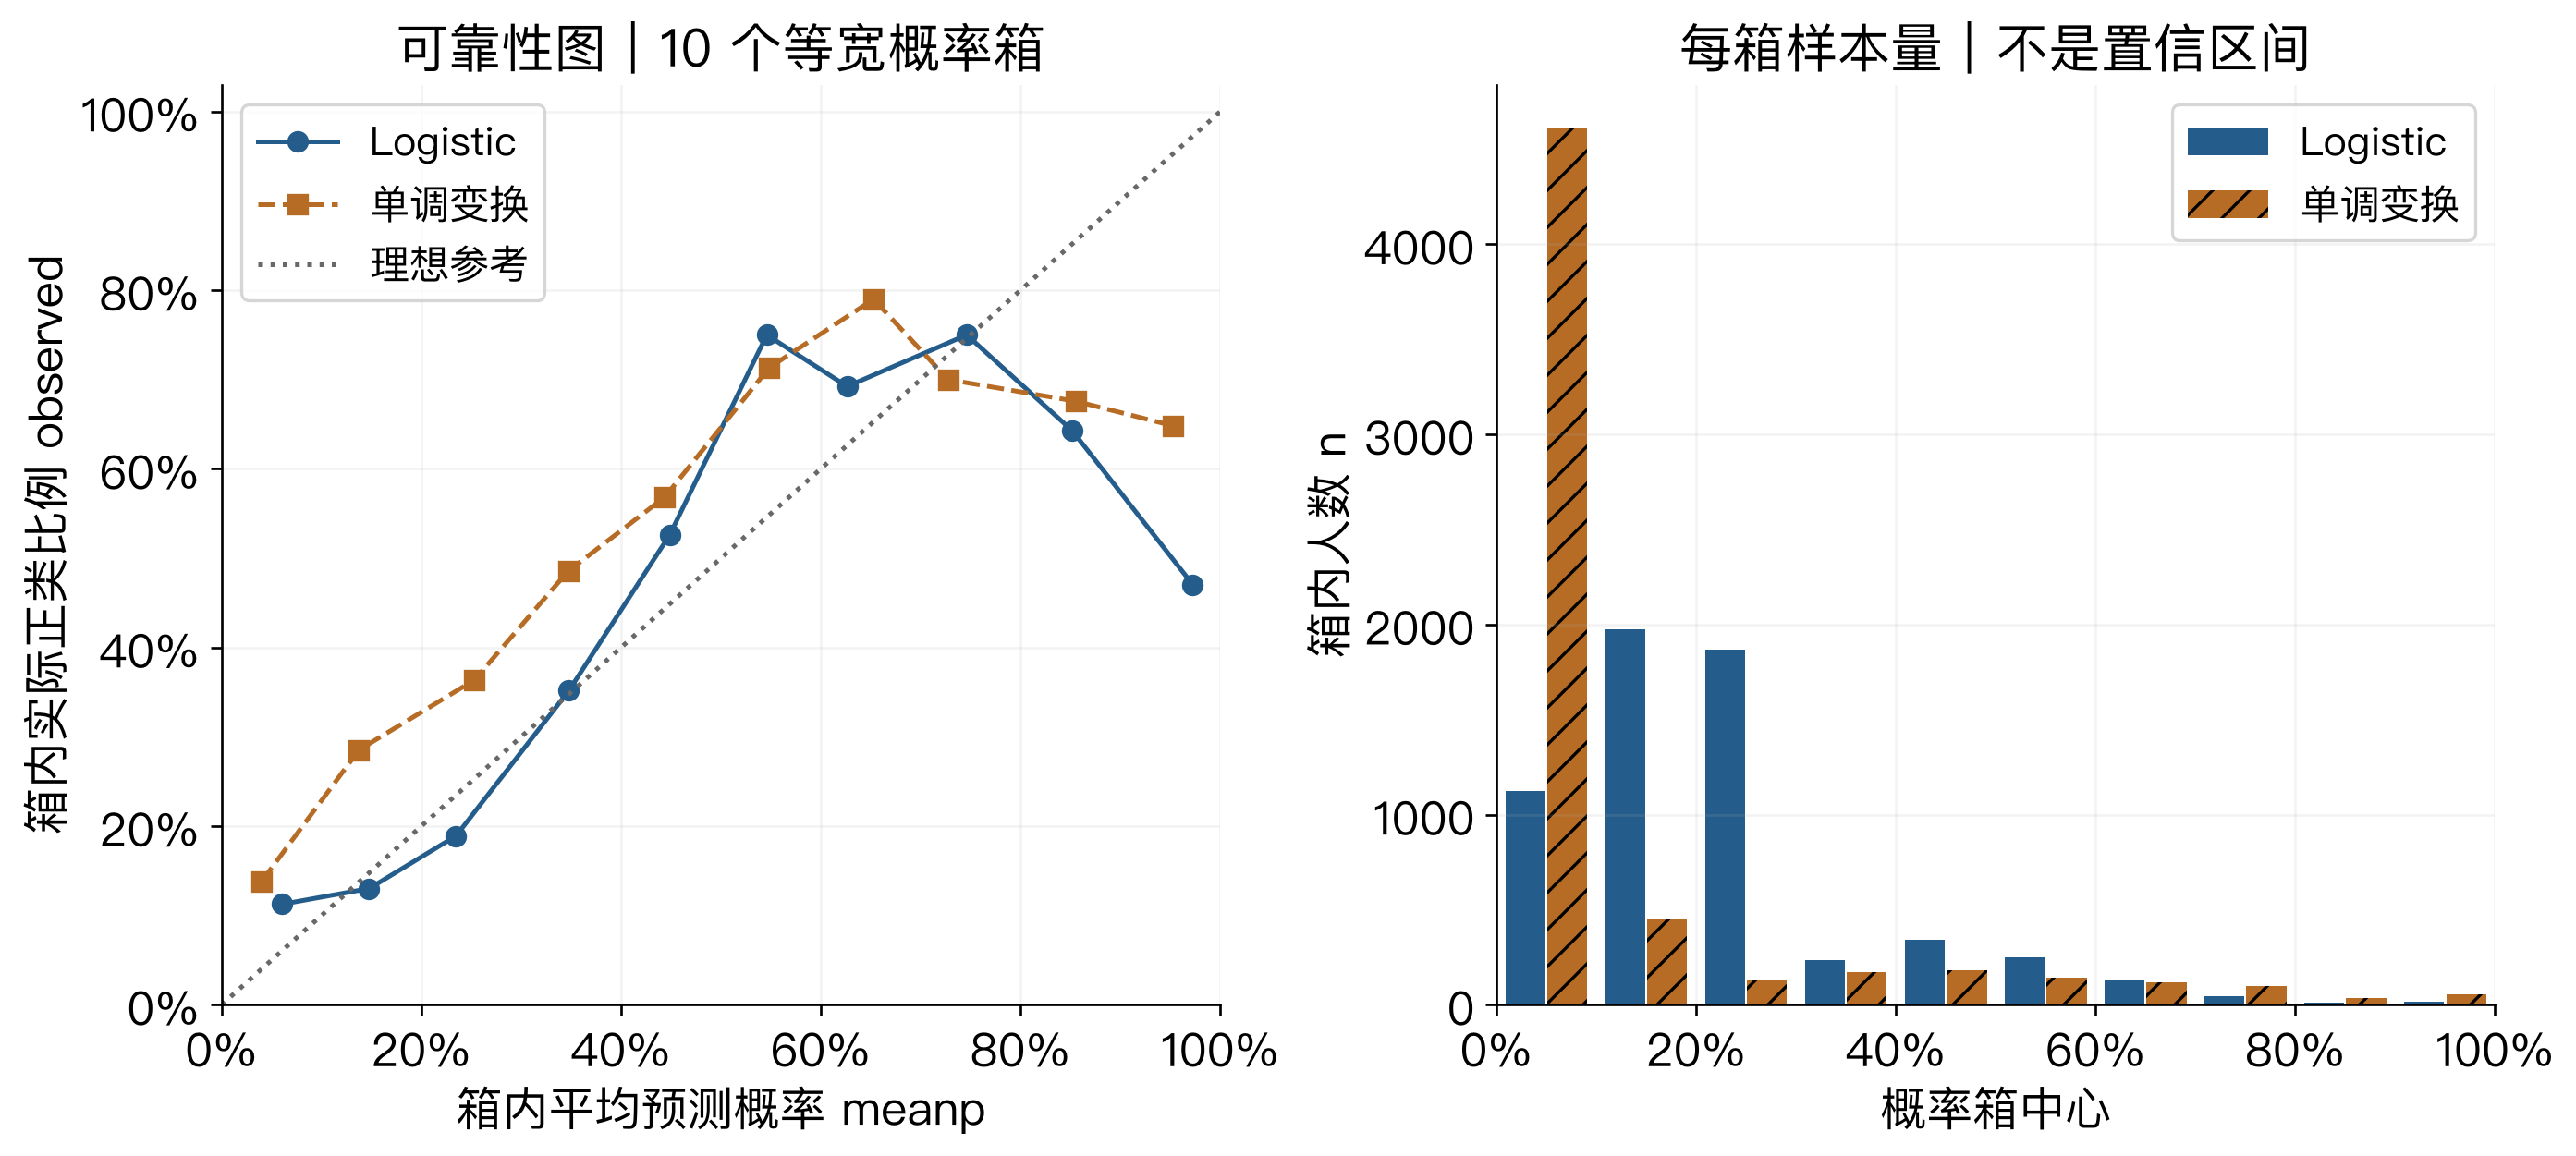

In [32]:
plot_calibration(calibration_tables, path=asset_dir / "lab05-eval-calibration.png")

## 17｜概率质量用什么量

布里尔损失（Brier loss）是二分类平均平方概率误差 $\frac1n\sum_i(p_i-y_i)^2$。对数损失（log loss）是平均负对数概率 $-\frac1n\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)]$；错误且很自信的预测可能受到较大惩罚。

Brier同时受可靠性、区分能力及数据不确定性影响，不能单凭更低的Brier就断言校准更好。本地1.9.0使用 `scale_by_half=True` 保持二分类0到1口径。

**为什么需要Brier**：两样本真实标签为 `[1, 0]`，模型A都预测0.5，Brier=0.25；模型B预测 `[0.9, 0.1]`，Brier=0.01。A在这组的预测概率与实际正类比例都为0.5，分组偏差可为0，但没有区分两人。B在本例的概率预测更好，说明分组校准与整体概率质量需要分别评价；小样本不证明长期校准。

In [33]:
# [ref:l5-monotonic]
from sklearn.metrics import brier_score_loss, log_loss
probability_rows = []
for name, p in [("LR", p_lr), ("单调变换", p_changed)]:
    probability_rows.append({"model": name, "roc_auc": roc_auc_score(actual, p),
        "ap": average_precision_score(actual, p),
        "brier": brier_score_loss(actual, p, scale_by_half=True), "logloss": log_loss(actual, p)})
monotonic_table = pd.DataFrame(probability_rows).set_index("model")
display(monotonic_table)
# 核对单调变换前后的AUC与AP一致。
assert np.allclose(monotonic_table.loc["LR", ["roc_auc", "ap"]], monotonic_table.loc["单调变换", ["roc_auc", "ap"]])
# 核对Brier接口值与二分类平方误差均值一致。
assert np.isclose(monotonic_table.loc["LR", "brier"], np.mean((p_lr - actual)**2))

,roc_auc,ap,brier,logloss
model,,,,
LR,0.72,0.4927,0.1464,0.4724
单调变换,0.72,0.4927,0.1541,0.5800


AUC与AP保持不变，Brier与对数损失可以改变。⚠️ 这种变换是否一定改善概率质量？没有这种保证；本次变化的方向只由上述实际输出决定。

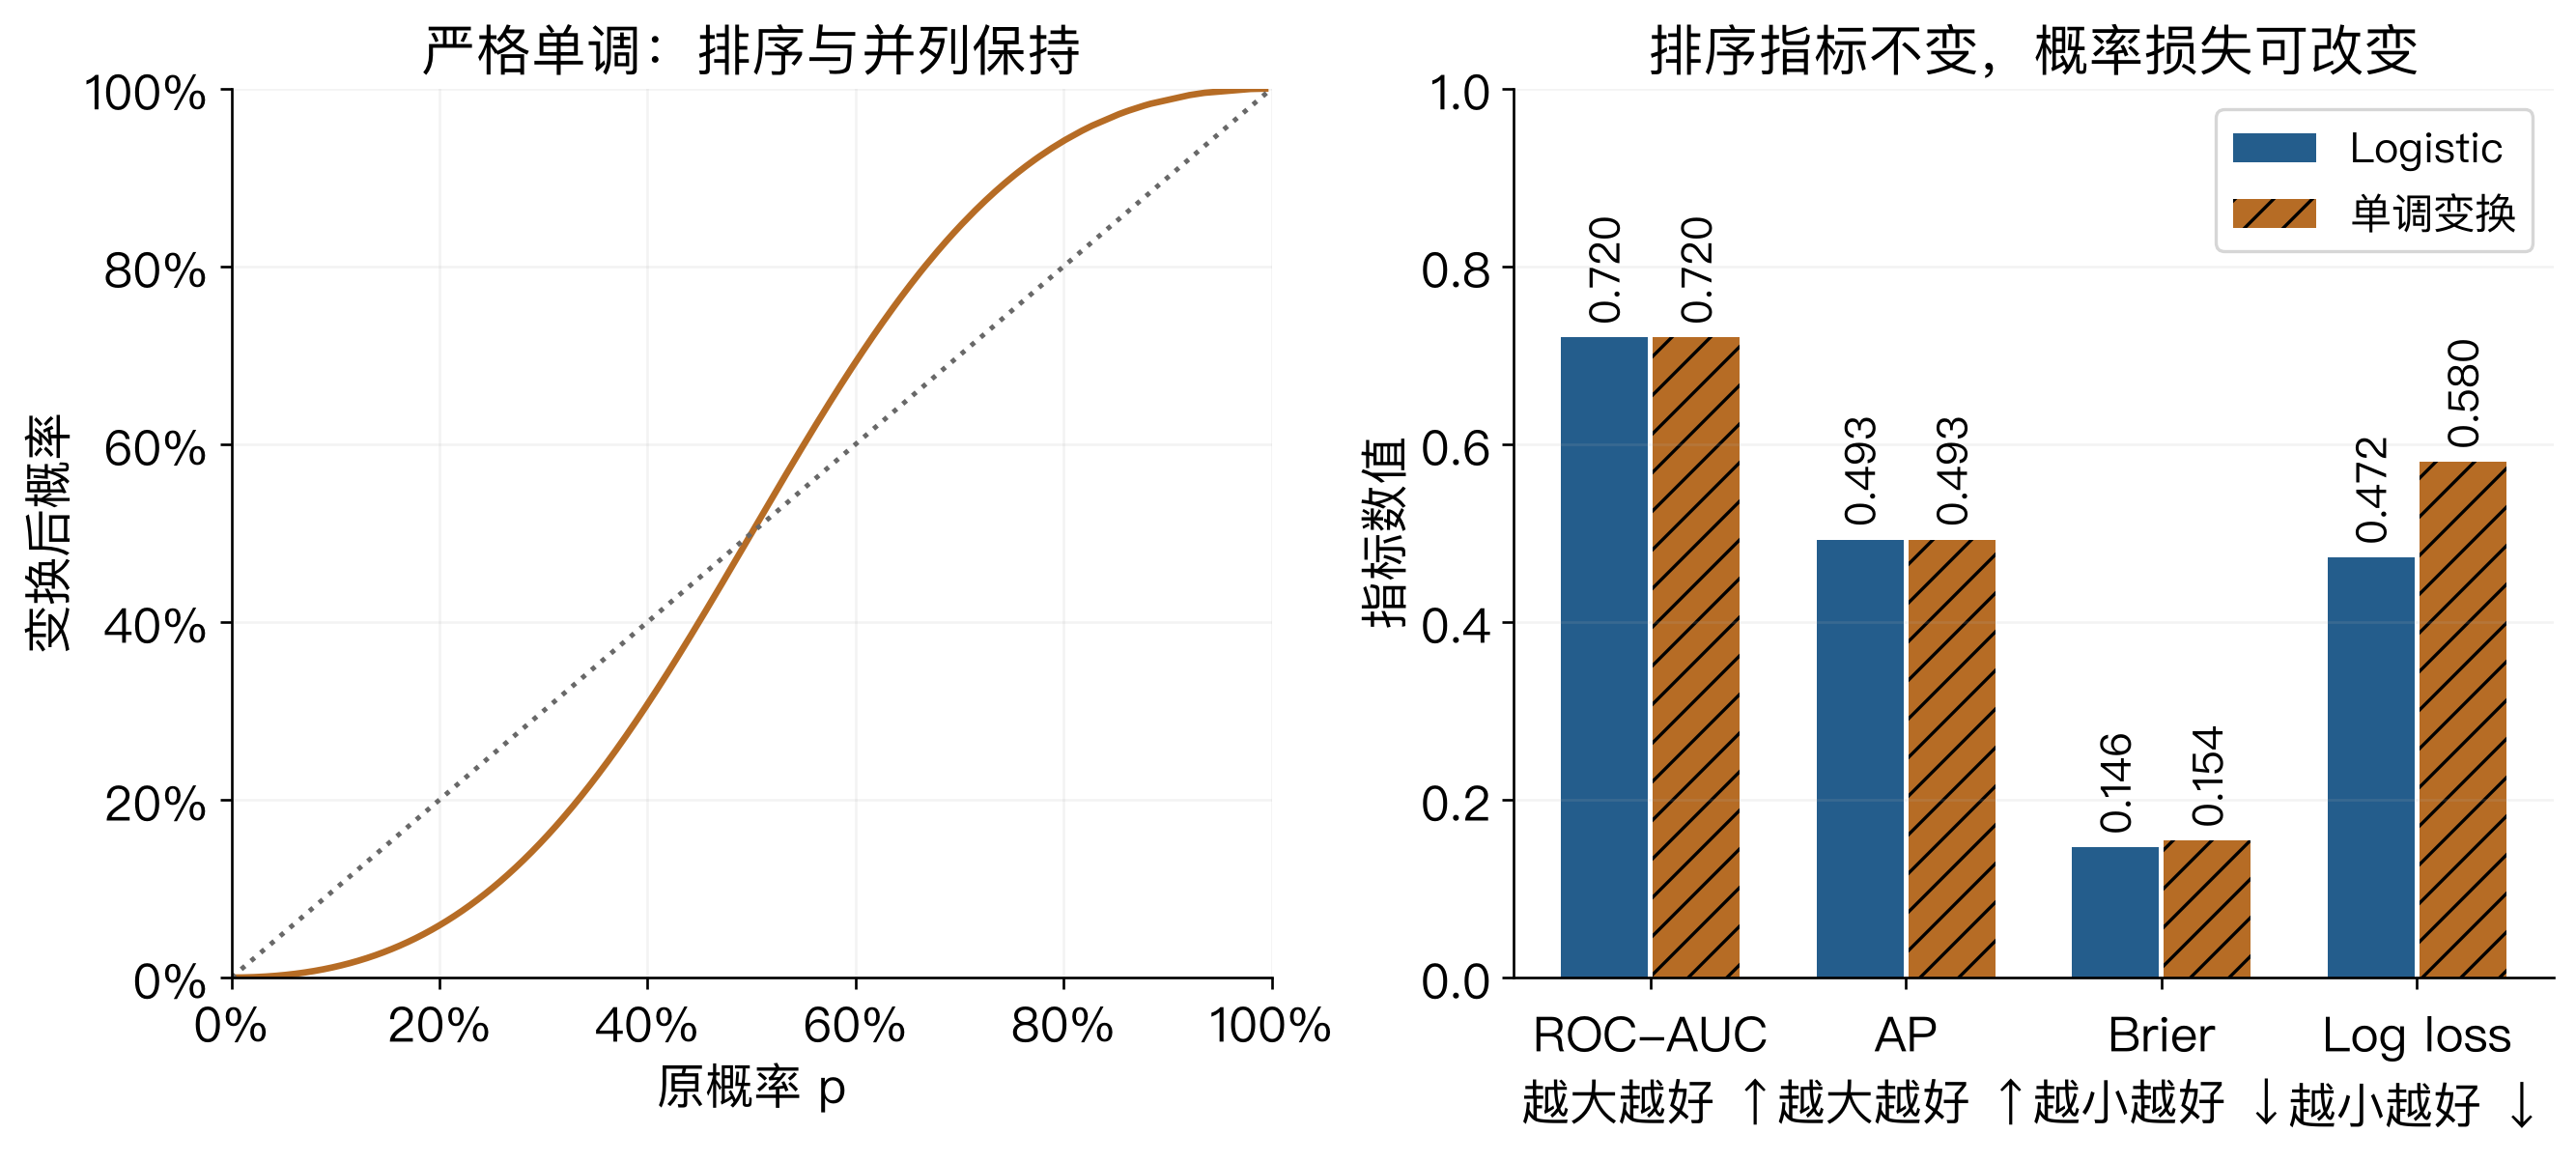

In [34]:
plot_monotonic(p_lr, p_changed, monotonic_table, path=asset_dir / "lab05-eval-monotonic.png")

## 18｜复现kNN三邻居

复用第4章的训练内标准化、k=3、暴力搜索及单线程配置。概率只能取0、1/3、2/3、1，排名中会有大量并列；容量结果依赖已公开的并列约定。

In [35]:
# [ref:l5-knn]
from sklearn.neighbors import KNeighborsClassifier
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3, algorithm="brute", n_jobs=1))
knn.fit(X_fit, y_fit)
p_knn = knn.predict_proba(X_valid)[:, 1]
print("kNN分数及人数:", np.unique(p_knn, return_counts=True))

kNN分数及人数: (array([0.        , 0.33333333, 0.66666667, 1.        ]), array([3350, 1665,  694,  291]))


## 19｜复现分箱贝叶斯

五列连续特征用训练集5分位箱，三列还款状态 `PAY_0/PAY_2/PAY_3` 用 `OrdinalEncoder`。箱号与编码都是类别索引。固定 `alpha=1`，保留第4章的 `averaged_inverted_cdf` 分位数算法。

In [36]:
# [ref:l5-nb-preprocess]
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import KBinsDiscretizer, OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB
category_columns = ["PAY_0", "PAY_2", "PAY_3"]
numeric_columns = [f for f in feature_names if f not in category_columns]
nb_preprocessor = ColumnTransformer([
    ("bins", KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile",
                              quantile_method="averaged_inverted_cdf", subsample=None), numeric_columns),
    ("categories", OrdinalEncoder(dtype=int), category_columns)])
nb = make_pipeline(nb_preprocessor, CategoricalNB(alpha=1))

In [37]:
# [ref:l5-nb]
nb.fit(X_fit, y_fit)
p_nb = nb.predict_proba(X_valid)[:, 1]
print("连续列实际箱数:", nb[0].named_transformers_["bins"].n_bins_)
print("alpha:", nb[-1].alpha)
display(pd.DataFrame(nb[0].transform(X_valid.head(3)), columns=[*numeric_columns, *category_columns]))

连续列实际箱数: [5 5 5 5 5]
alpha: 1


,LIMIT_BAL,BILL_AMT1,BILL_AMT2,PAY_AMT1,PAY_AMT2,PAY_0,PAY_2,PAY_3
0,0.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0
1,4.0,4.0,4.0,4.0,3.0,2.0,2.0,2.0
2,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


重复值会使部分箱宽被删除，实际箱数可能小于5；以输出为准。当前验证集未出现训练中未见的还款编码，否则默认 `OrdinalEncoder` 会报错，需要另行约定。

## 20｜加入常数概率基线

Dummy在本章使用 `strategy="prior"`，所有客户的正类概率都等于训练正类率；默认预测标签仍全为0，与第4章多数类基线的标签一致。第4章 `most_frequent` 的概率为0，本章改用先验概率，供Brier与对数损失比较，不能声称两章概率完全一致。

常数分数使AUC=0.5、AP等于验证正类率；其前K名只依赖固定验证顺序。没有预测正类时查准率无定义，表格以 `zero_division=0` 约定显示0。

In [38]:
# [ref:l5-dummy]
from sklearn.dummy import DummyClassifier
dummy = DummyClassifier(strategy="prior").fit(X_fit, y_fit)
p_dummy = dummy.predict_proba(X_valid)[:, 1]
print("Dummy正类分数:", np.unique(p_dummy))
print("Dummy预测类别:", np.unique(dummy.predict(X_valid)))
print("训练正类率:", y_fit.mean())
# 核对Dummy的常数概率等于训练正类率。
assert np.allclose(p_dummy, y_fit.mean())

Dummy正类分数: [0.22122222]
Dummy预测类别: [0]
训练正类率: 0.2212222222222222


<a id="lab05-model-comparison"></a>
## 21｜最后循环比较模型

同一批验证客户、默认阈值0.5、同一容量K=600。准确率看分类，AUC/AP看排序，Brier/对数损失看概率预测质量。比较完整方案，不能把预处理效果单独归因于分类器。

In [39]:
# [ref:l5-model-comparison]
scores = {"LR": p_lr, "kNN3": p_knn, "binnedCategoricalNB": p_nb, "Dummy": p_dummy}
metric_rows = []
for name, p in scores.items():
    pred = p >= .5
    metric_rows.append({"model": name, "accuracy": accuracy_score(actual, pred),
        "precision": precision_score(actual, pred, zero_division=0), "recall": recall_score(actual, pred),
        "roc_auc": roc_auc_score(actual, p), "ap": average_precision_score(actual, p),
        "brier": brier_score_loss(actual, p, scale_by_half=True), "logloss": log_loss(actual, p)})
metrics_table = pd.DataFrame(metric_rows).set_index("model")
display(metrics_table)
# 核对常数分数的AP等于验证正类率。
assert np.isclose(metrics_table.loc["Dummy", "ap"], positive_rate)

,accuracy,precision,recall,roc_auc,ap,brier,logloss
model,,,,,,,
LR,0.8120,0.7196,0.2457,0.7200,0.4927,0.1464,0.4724
kNN3,0.7767,0.4934,0.3662,0.6750,0.3688,0.1812,3.6607
binnedCategoricalNB,0.7947,0.5443,0.4401,0.7501,0.4949,0.1611,0.5569
Dummy,0.7788,0.0000,0.0000,0.5000,0.2212,0.1723,0.5284


**读表**：本次分箱贝叶斯的ROC-AUC约0.750，高于LR的0.720；两者AP约0.495与0.493。LR的Brier与对数损失更低。这些差异来自完整方案，回答的问题也不同。

kNN输出包含0与1。若真实正类收到概率0，或真实负类收到概率1，对数损失的理论惩罚趋于无穷；接口按浮点精度截断概率后得到有限值。本次kNN对数损失约3.66，不能仅凭它的默认准确率判断概率质量。

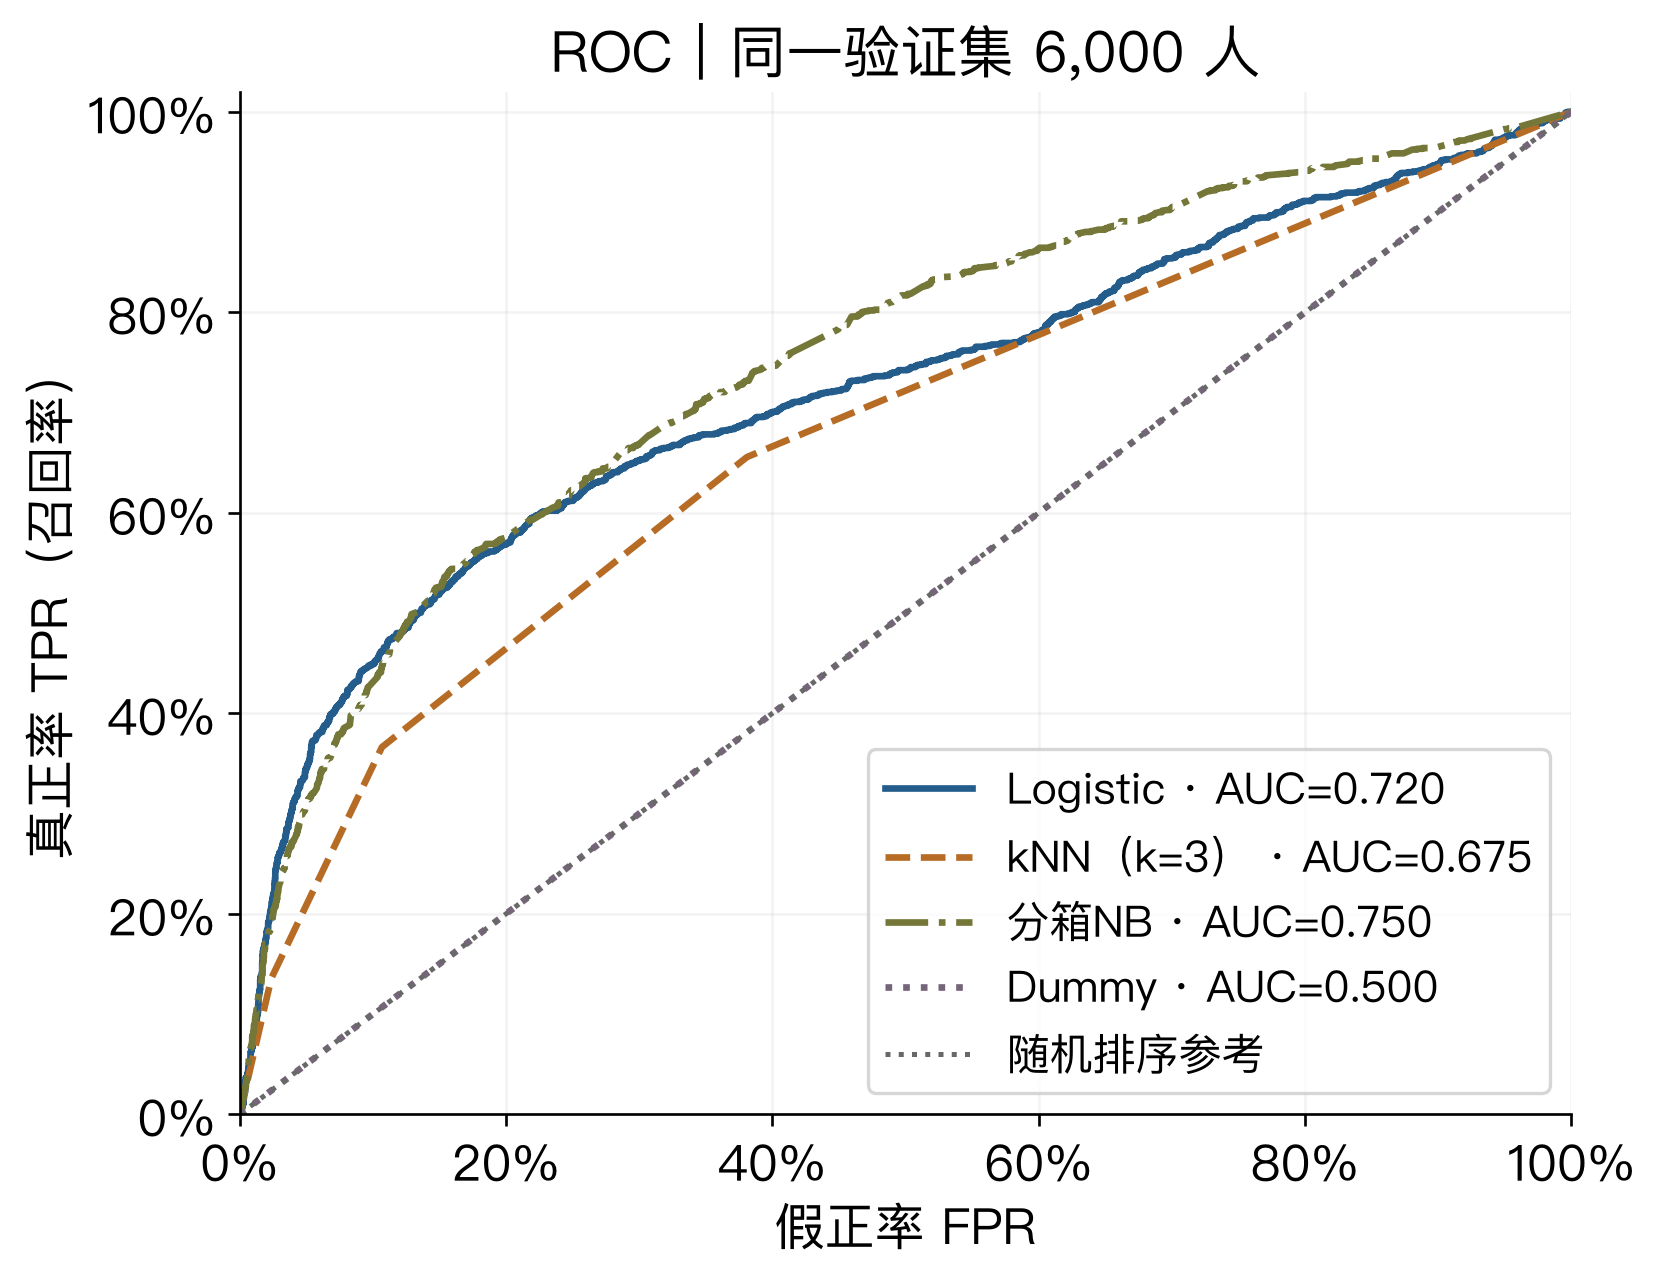

In [40]:
plot_roc(actual, scores, path=asset_dir / "lab05-eval-roc.png")

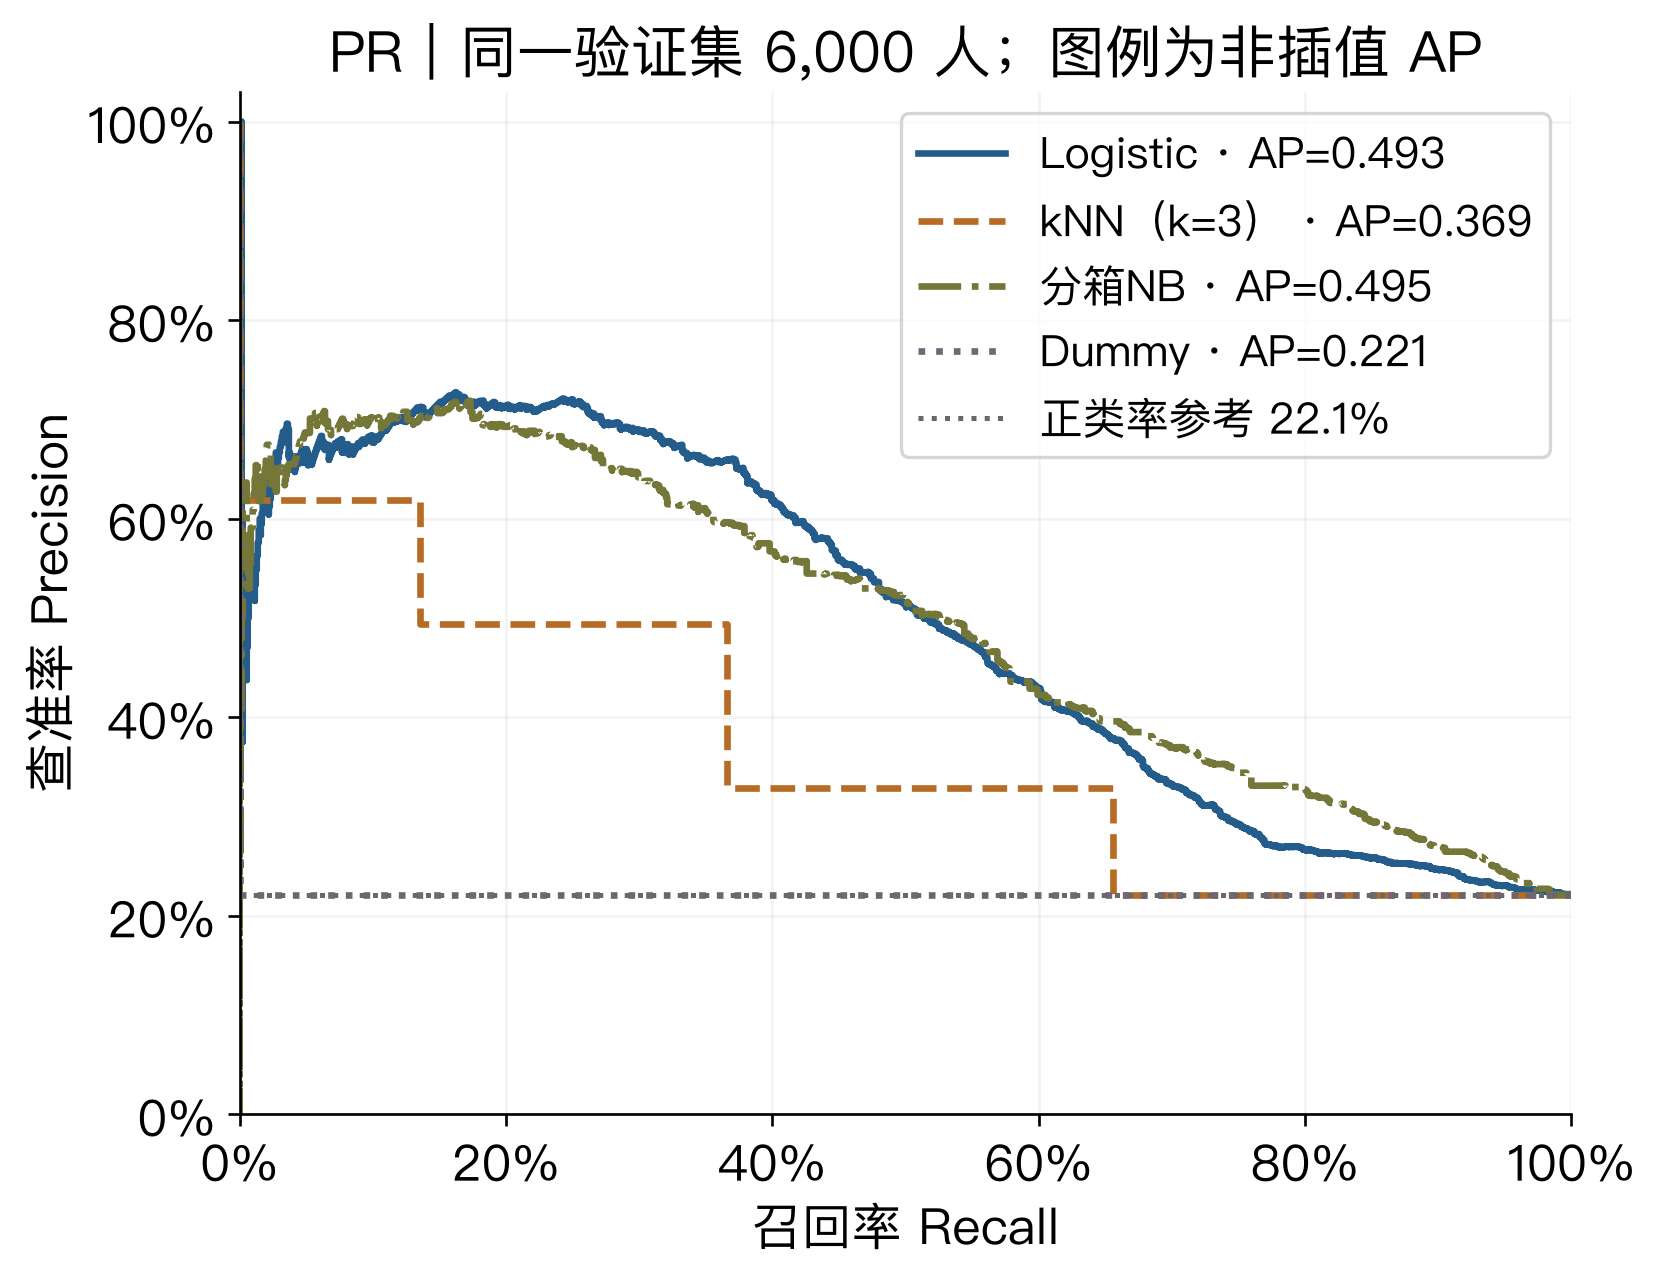

In [41]:
plot_pr(actual, scores, baseline=positive_rate, path=asset_dir / "lab05-eval-pr.png")

<a id="lab05-capacity"></a>
## 22｜只核查前600名

核查容量（capacity）设为验证集的10%，即K=600。先看一个模型的排序前几行，再计算前K名中找到多少真实正类。排序稳定性用 `kind="stable"`：同分时按验证行顺序。

标签只用于事后评价名单，生成排名时只用模型分数。

In [42]:
# [ref:l5-ranking]
K = 600
ranking = np.argsort(-p_lr, kind="stable")
ranking_head = pd.DataFrame({"rank": np.arange(1, 9), "validation_row": ranking[:8],
    "客户ID": credit.loc[valid_positions[ranking[:8]], "ID"].to_numpy(),
    "score": p_lr[ranking[:8]], "actual": actual[ranking[:8]]})
display(ranking_head)
print("第600名分数:", p_lr[ranking[K-1]], "第601名分数:", p_lr[ranking[K]])

,rank,validation_row,客户ID,score,actual
0,1,2867,13713,0.9939,1
1,2,4328,13636,0.9938,1
2,3,2585,832,0.9938,0
3,4,1191,982,0.9937,0
4,5,2598,9980,0.9937,1
5,6,5773,13262,0.9931,0
6,7,5840,4445,0.9924,0
7,8,241,8998,0.9923,0


第600名分数: 0.4590258019689049 第601名分数: 0.45834834277564124


## 23｜容量下的查准与召回

前K名查准率（Precision@K）=前K名真实正类数/K；前K名召回率（Recall@K）=前K名真实正类数/验证全部正类数。两项是本章容量比较的核心。

累计捕获比例（cumulative gain）在此等于Recall@K；提升倍数（lift）=Precision@K/正类率，只表示对随机排序的名单浓度比。它们不证明核查造成了违约减少或因果收益。

In [43]:
# [ref:l5-capacity]
hits_600 = int(actual[ranking[:K]].sum())
lr_capacity = {"k": K, "selected_fraction": K / len(actual), "hits": hits_600,
               "precision_at_k": hits_600 / K, "recall_at_k": hits_600 / actual.sum(),
               "gain": hits_600 / actual.sum(), "lift": (hits_600 / K) / positive_rate}
display(pd.DataFrame([lr_capacity]))

,k,selected_fraction,hits,precision_at_k,recall_at_k,gain,lift
0,600,0.1,412,0.6867,0.3105,0.3105,3.1047


⚖️ 核查前600名后有更多正类进入名单，能直接说核查减少了这些人的违约吗？不能；当前数据只评价名单对已有标签的捕获。

## 24｜容量改变后再比较

K取300、600、1200，分别占验证集5%、10%、20%。增加K使捕获人数不减少，但查准率未必单调变化；结果要看实际名单。

In [44]:
# [ref:l5-capacity-lr]
lr_capacity_rows = []
for k in [300, 600, 1200]:
    hits = int(actual[ranking[:k]].sum())
    lr_capacity_rows.append({"model": "LR", "k": k, "hits": hits,
        "precision_at_k": hits / k, "recall_at_k": hits / actual.sum()})
display(pd.DataFrame(lr_capacity_rows))

,model,k,hits,precision_at_k,recall_at_k
0,LR,300,217,0.7233,0.1635
1,LR,600,412,0.6867,0.3105
2,LR,1200,637,0.5308,0.4800


In [45]:
# [ref:l5-capacity-comparison]
capacity_rows = []
for name, p in scores.items():
    order = np.argsort(-p, kind="stable")
    for k in [300, 600, 1200]:
        hits = int(actual[order[:k]].sum())
        capacity_rows.append({"model": name, "k": k, "selected_fraction": k / len(actual), "hits": hits,
            "precision_at_k": hits / k, "recall_at_k": hits / actual.sum(),
            "gain": hits / actual.sum(), "lift": (hits / k) / positive_rate})
capacity_table = pd.DataFrame(capacity_rows)
display(capacity_table.loc[capacity_table["k"] == 600].set_index("model"))

,k,selected_fraction,hits,precision_at_k,recall_at_k,gain,lift
model,,,,,,,
LR,600,0.1,412,0.6867,0.3105,0.3105,3.1047
kNN3,600,0.1,309,0.5150,0.2329,0.2329,2.3286
binnedCategoricalNB,600,0.1,388,0.6467,0.2924,0.2924,2.9239
Dummy,600,0.1,145,0.2417,0.1093,0.1093,1.0927


In [46]:
# [ref:l5-capacity-ties]
display(capacity_table.pivot(index="k", columns="model", values=["precision_at_k", "recall_at_k"]))
tie_rows = []
for name, p in scores.items():
    order = np.argsort(-p, kind="stable")
    boundary = p[order[599]]
    tie_rows.append({"model": name, "boundary_score": boundary, "total_equal_boundary": int((p == boundary).sum()),
                     "selected_equal_boundary": int((p[order[:600]] == boundary).sum())})
tie_table = pd.DataFrame(tie_rows)
display(tie_table)

precision_at_k                                     recall_at_k          \
model          Dummy      LR binnedCategoricalNB    kNN3       Dummy      LR   
k                                                                              
300           0.2467  0.7233              0.7167  0.6133      0.0558  0.1635   
600           0.2417  0.6867              0.6467  0.5150      0.1093  0.3105   
1200          0.2283  0.5308              0.5300  0.4483      0.2065  0.4800   

                                   
model binnedCategoricalNB    kNN3  
k                                  
300                0.1620  0.1387  
600                0.2924  0.2329  
1200               0.4793  0.4054

,model,boundary_score,total_equal_boundary,selected_equal_boundary
0,LR,0.4590,1,1
1,kNN3,0.6667,694,309
2,binnedCategoricalNB,0.8814,1,1
3,Dummy,0.2212,6000,600


⚠️ 尤其是kNN与Dummy，分数相同的客户可能跨越容量边界。当前表格只报告固定验证顺序下的结果，不暗示并列名单唯一，也不根据标签破除并列。

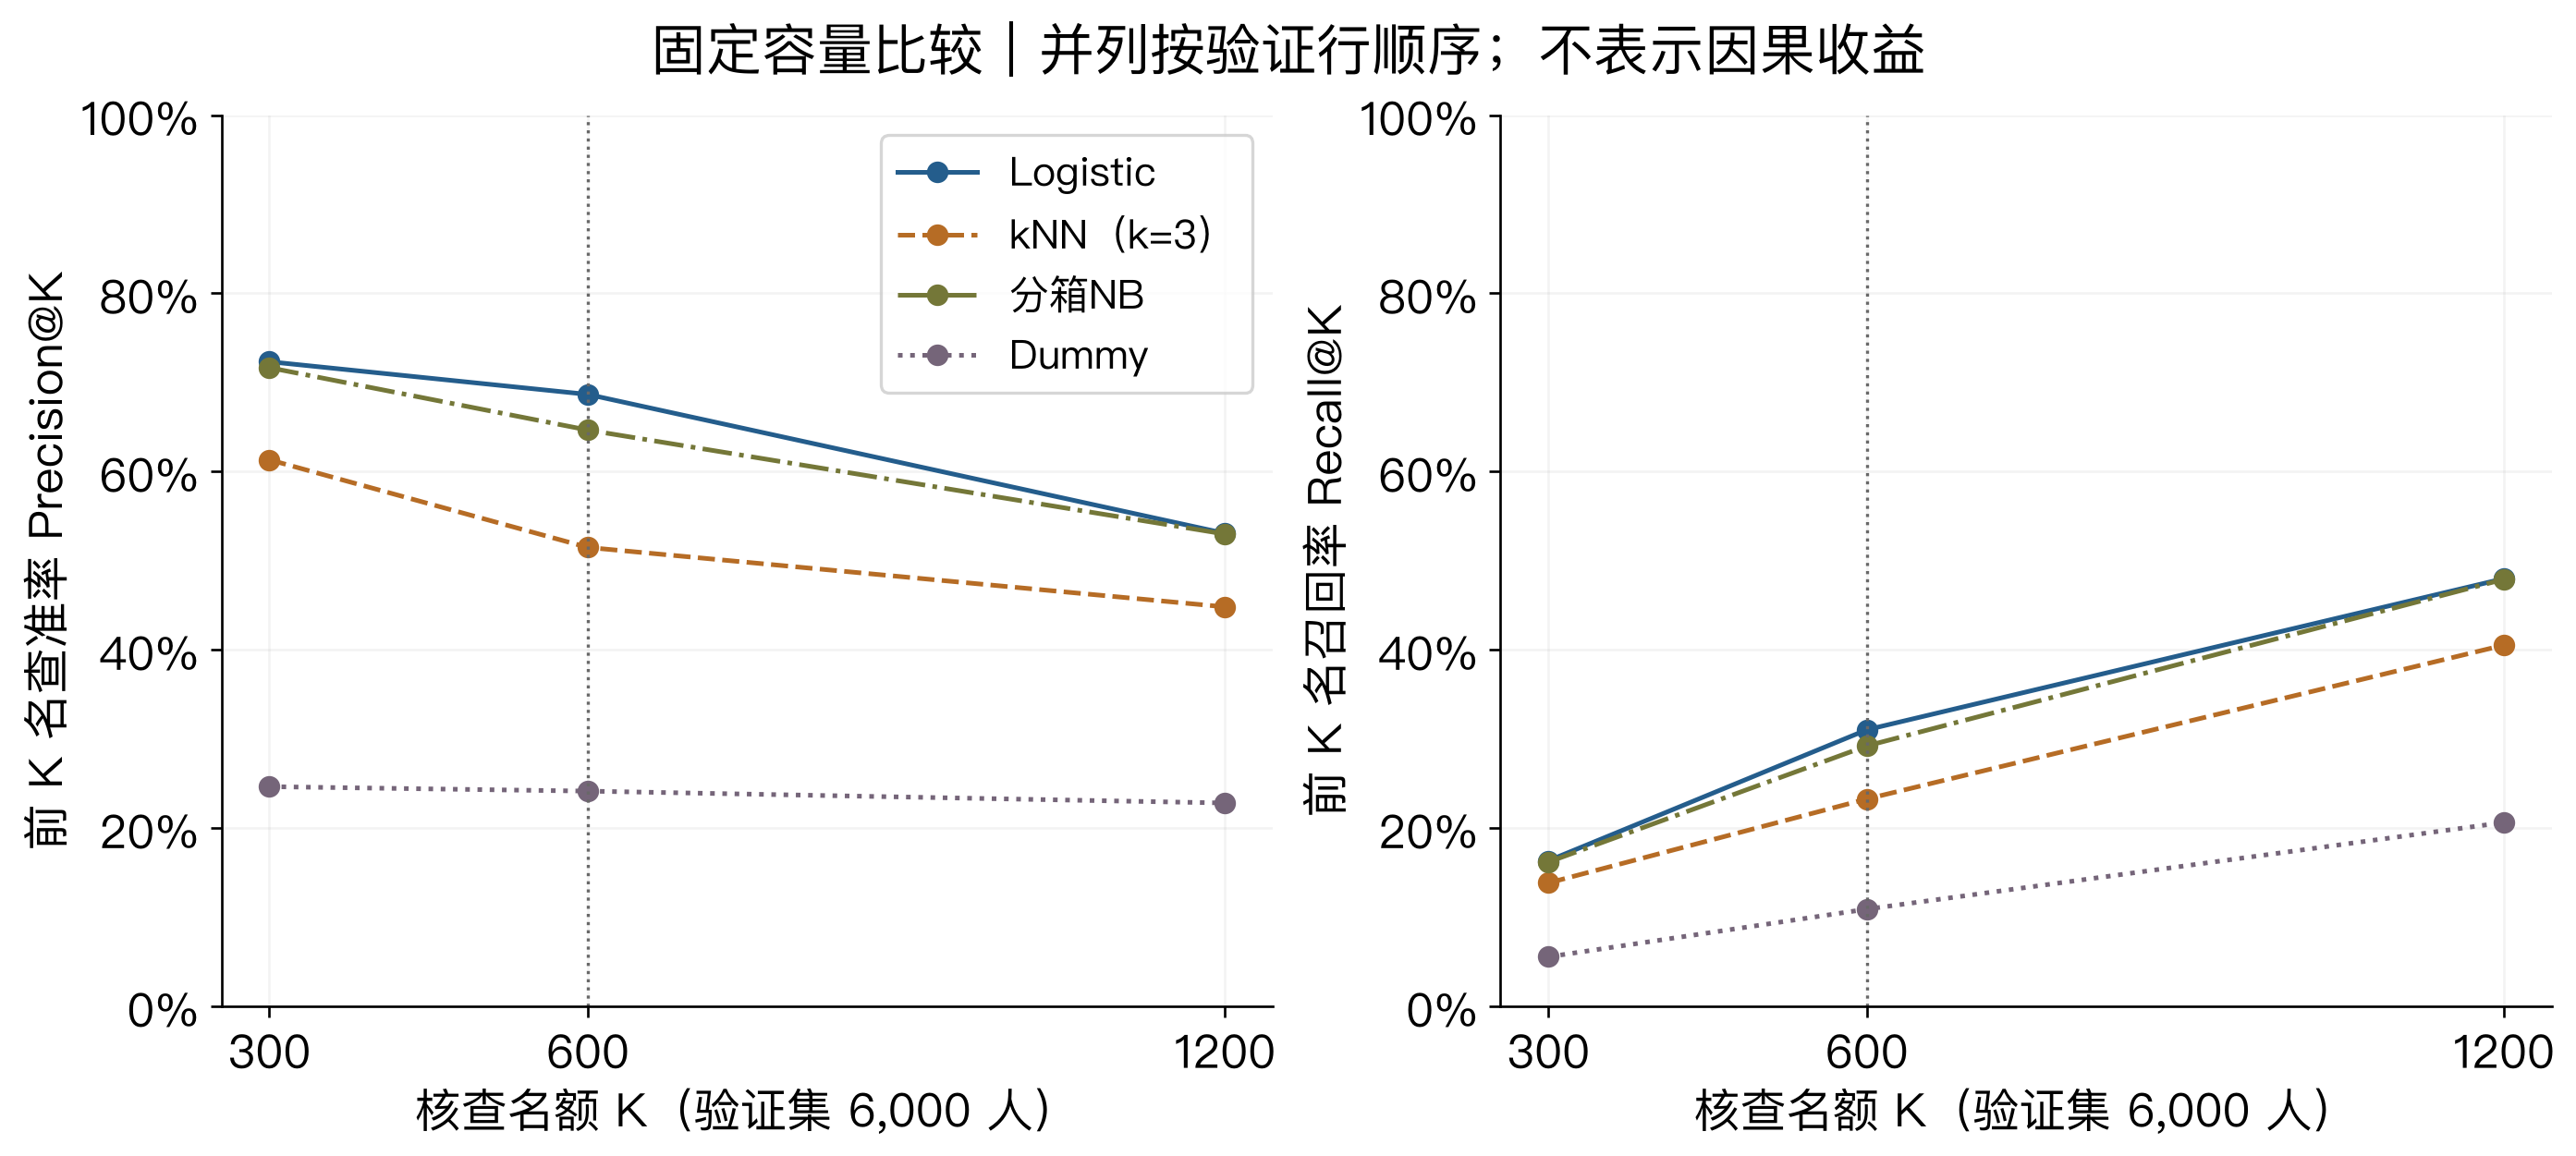

In [47]:
plot_capacity(capacity_table, path=asset_dir / "lab05-eval-capacity.png")

<a id="lab05-cost"></a>
## 25｜代价改变，目标改变

设每次误报代价为1，每次漏报代价为r，验证总错误代价为 $C=FP+rFN$。这是预设代价单位，不是客户金额损失估计。先在Logistic模型与r=4上看一个阈值。

前K名受名额约束；代价阈值受错误权重约束，二者不必选同样多的人。

In [48]:
threshold = .3
pred = p_lr >= threshold
tn_one, fp_one, fn_one, tp_one = confusion_matrix(actual, pred, labels=[0, 1]).ravel()
print("阈值:", threshold, "FP:", fp_one, "FN:", fn_one, "r=4代价:", fp_one + 4 * fn_one)
print("预测正类人数:", pred.sum(), "固定容量:", K)

阈值: 0.3 FP: 443 FN: 737 r=4代价: 3391
预测正类人数: 1033 固定容量: 600


## 26｜验证阈值探索

r取1、4、10，阈值候选固定为0.05到0.95，步长0.05。比较每个r内的最低代价；不同r的代价单位权重不同，不拿最小总数跨r排名。并列最低代价时保留候选顺序中的较小阈值。

这些是同一验证集上的教学探索，不能当成独立泛化证明。本章不重复第4章的冻结后测试。

In [49]:
# [ref:l5-cost]
cost_rows = []
for threshold in np.round(np.arange(.05, .951, .05), 2):
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(actual, p_lr >= threshold, labels=[0, 1]).ravel()
    for r in [1, 4, 10]:
        cost_rows.append({"r": r, "threshold": threshold, "FP": int(fp_t), "FN": int(fn_t),
            "TP": int(tp_t), "TN": int(tn_t), "cost": int(fp_t + r * fn_t),
            "precision": tp_t / (tp_t + fp_t) if tp_t + fp_t else 0., "recall": tp_t / actual.sum()})
cost_table = pd.DataFrame(cost_rows)
cost_best = cost_table.loc[cost_table.groupby("r")["cost"].idxmin()].reset_index(drop=True)
display(cost_best)

,r,threshold,FP,FN,TP,TN,cost,precision,recall
0,1,0.45,204,898,429,4469,1102,0.6777,0.3233
1,4,0.25,701,637,690,3972,3249,0.4960,0.5200
2,10,0.05,4308,56,1271,365,4868,0.2278,0.9578


⚖️ r增大时为什么更愿意容许误报？一次漏报变得更贵。但最终选到哪个候选阈值，由当前分数与错误计数共同决定。

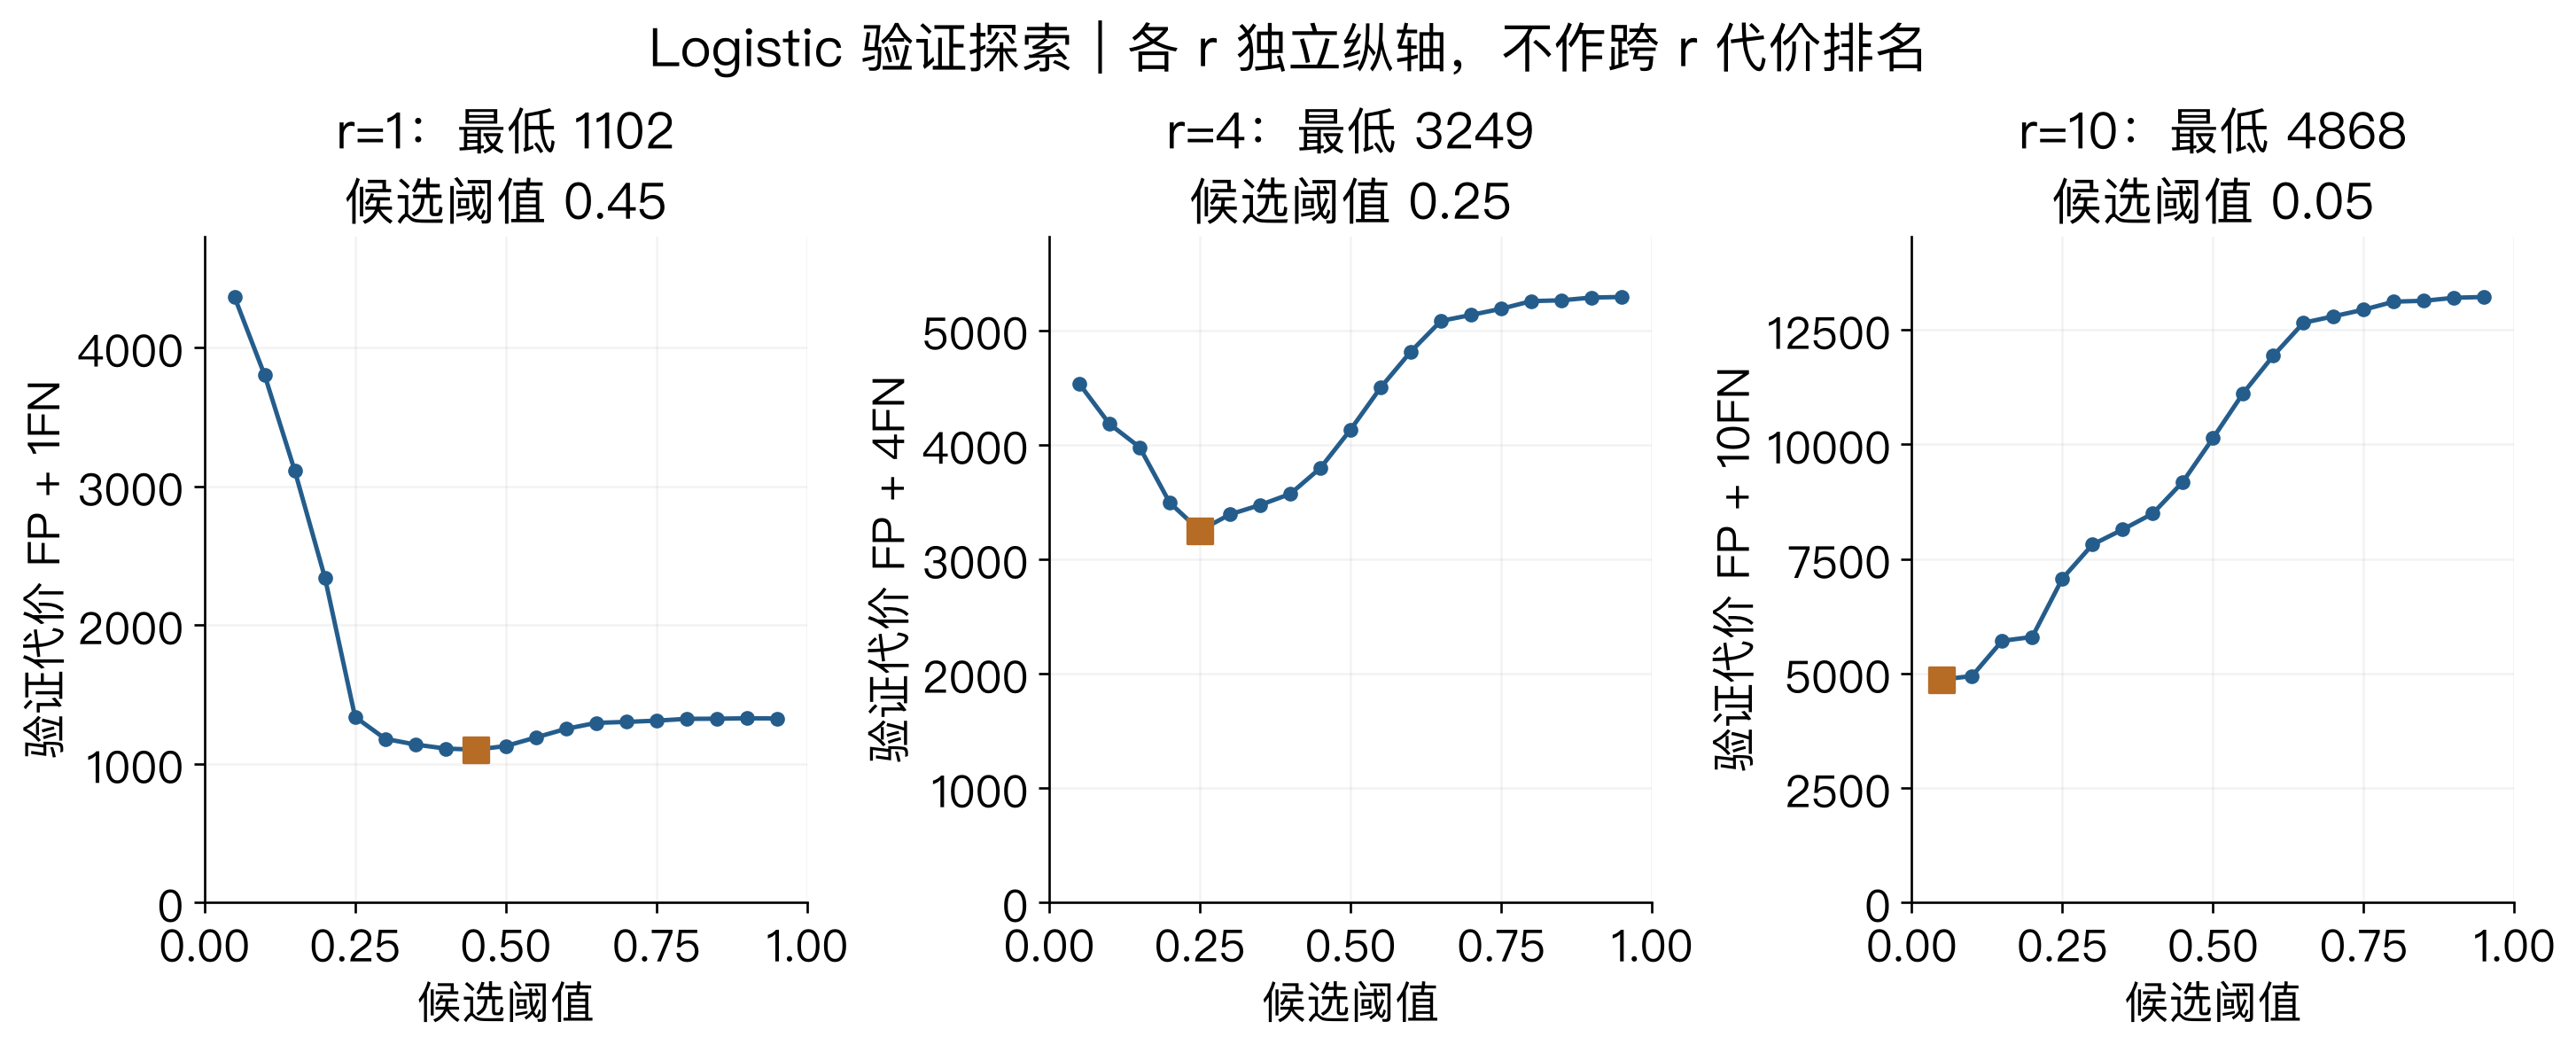

In [50]:
plot_cost(cost_table, cost_best, path=asset_dir / "lab05-eval-cost.png")

## 27｜延伸实验｜类别权重改变训练，再回到600个名额

保持训练18,000条、验证6,000条及八个特征不变。候选权重预先设为 `[1, 2, 4, 8]`，其他参数与原Logistic一致；仅在训练集拟合。这里是在同一验证集上的教学探索，不能作为独立最终测试成绩。

In [51]:
# [ref:l5-weighted-fit]
weighted_scores = {1: p_lr}
weighted_models = {1: lr}
for positive_weight in [2, 4, 8]:
    candidate = make_pipeline(StandardScaler(), LogisticRegression(
        class_weight={0: 1, 1: positive_weight}, max_iter=1000, random_state=SEED))
    candidate.fit(X_fit, y_fit)  # 预处理与模型都只拟合训练集
    weighted_models[positive_weight] = candidate
    weighted_scores[positive_weight] = candidate.predict_proba(X_valid)[:, 1]
print("候选正类权重：", list(weighted_scores))

候选正类权重： [1, 2, 4, 8]


### 1｜先看固定阈值0.5

权重增加后，超过0.5的人可能更多，但这不代表每天600个名额内找得更准。先核对名单人数与概率评分。

In [52]:
# [ref:l5-weighted-default]
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss
weighted_default_rows = []
for weight, score in weighted_scores.items():
    tn_w, fp_w, fn_w, tp_w = confusion_matrix(actual, score >= .5, labels=[0, 1]).ravel()
    weighted_default_rows.append(dict(weight=weight, reported=int(tp_w+fp_w), TP=int(tp_w),
        precision=tp_w/(tp_w+fp_w), recall=tp_w/actual.sum(), AUC=roc_auc_score(actual, score),
        AP=average_precision_score(actual, score), Brier=brier_score_loss(actual, score),
        LogLoss=log_loss(actual, score)))
weighted_default = pd.DataFrame(weighted_default_rows)
display(weighted_default.round(4))

,weight,reported,TP,precision,recall,AUC,AP,Brier,LogLoss
0,1,453,326,0.7196,0.2457,0.7200,0.4927,0.1464,0.4724
1,2,921,553,0.6004,0.4167,0.7200,0.4920,0.1621,0.5088
2,4,2925,946,0.3234,0.7129,0.7201,0.4913,0.2214,0.6375
3,8,4921,1205,0.2449,0.9081,0.7200,0.4906,0.3281,0.8731


### 2｜每个模型各自选择阈值：最多600人，漏报代价为4

遍历该模型所有不同分数及空名单，按 `score >= t` 生成名单，同分样本整组加入。只保留不超过600人的名单，再选 `FP + 4*FN` 最低的规则；同代价时优先人数少的规则。权重是训练参数，代价比是业务评价条件，两者分开设置。

In [53]:
# [ref:l5-weighted-threshold]
sys.path.insert(0, str(notebook_dir))
from helpers.weighted_capacity import threshold_candidates
weighted_threshold_rows = []
weighted_curves = {}
for weight, score in weighted_scores.items():
    curve = threshold_candidates(actual, score, cost_ratio=4)
    weighted_curves[weight] = curve
    feasible = curve.query("reported <= 600")
    best = feasible.sort_values(["cost", "reported", "threshold"], ascending=[True, True, False]).iloc[0]
    weighted_threshold_rows.append(dict(weight=weight, **best.to_dict()))
weighted_threshold = pd.DataFrame(weighted_threshold_rows)
display(weighted_threshold[["weight", "threshold", "reported", "TP", "FP", "FN", "cost"]].round(4))

,weight,threshold,reported,TP,FP,FN,cost
0,1,0.4592,599.0,412.0,187.0,915.0,3847.0
1,2,0.6149,600.0,412.0,188.0,915.0,3848.0
2,4,0.7480,600.0,411.0,189.0,916.0,3853.0
3,8,0.8464,600.0,410.0,190.0,917.0,3858.0


### 3｜公平比较排序：每个模型恰选600人

分数降序，同分保持固定验证行顺序；不按真实标签打破同分。此时 `P@600 = TP/600`，`R@600 = TP/1327`，两个指标都由命中数决定。

In [54]:
# [ref:l5-weighted-topk]
weighted_topk_rows = []
for weight, score in weighted_scores.items():
    order = np.argsort(-score, kind="stable")  # 同分保持固定验证行序
    selected = order[:600]
    tp_k = int(actual[selected].sum())
    fp_k, fn_k = 600-tp_k, int(actual.sum())-tp_k
    weighted_topk_rows.append(dict(weight=weight, TP=tp_k, FP=fp_k, FN=fn_k,
        P600=tp_k/600, R600=tp_k/actual.sum(), cost=fp_k+4*fn_k,
        cutoff=float(score[order[599]])))
weighted_topk = pd.DataFrame(weighted_topk_rows)
assert len(actual) == 6000 and actual.sum() == 1327
display(weighted_topk.round(4))

,weight,TP,FP,FN,P600,R600,cost,cutoff
0,1,412,188,915,0.6867,0.3105,3848,0.4590
1,2,412,188,915,0.6867,0.3105,3848,0.6149
2,4,411,189,916,0.6850,0.3097,3853,0.7480
3,8,410,190,917,0.6833,0.3090,3858,0.8464


### 两张图分别回答什么？

**阈值与名单人数**：每条曲线对应一个重新训练的模型；通过调阈值控制复核人数。权重1达到600人需要约0.459，权重8需要约0.846，重训后应重新选择阈值。

**权重与Precision／Recall**：阈值固定0.5，只改变训练权重。本次正类权重增大后，名单人数和Recall上升，Precision下降。它说明当前实验减少漏报的同时增加了误报，不保证固定容量下命中更多。

### 细分权重｜1至8，每0.5一档

保持判定阈值0.5，每个权重都重新训练。原先四档模型直接复用；中间点为实际训练结果，不是曲线插值。下图仅标注1、2、4、8，完整15档结果保留在表中。

In [55]:
# [ref:l5-weighted-dense]
dense_scores = dict(weighted_scores)
for weight in np.arange(1, 8.01, .5):
    if weight not in dense_scores:
        candidate = make_pipeline(StandardScaler(), LogisticRegression(
            class_weight={0: 1, 1: weight}, max_iter=1000, random_state=SEED))
        candidate.fit(X_fit, y_fit)
        dense_scores[weight] = candidate.predict_proba(X_valid)[:, 1]

dense_rows = []
for weight, score in sorted(dense_scores.items()):
    tn_d, fp_d, fn_d, tp_d = confusion_matrix(actual, score >= .5, labels=[0, 1]).ravel()
    dense_rows.append(dict(weight=float(weight), reported=int(tp_d+fp_d),
        precision=tp_d/(tp_d+fp_d), recall=tp_d/actual.sum()))
weighted_dense = pd.DataFrame(dense_rows)
display(weighted_dense.round(4))

,weight,reported,precision,recall
0,1.0,453,0.7196,0.2457
1,1.5,778,0.6452,0.3783
2,2.0,921,0.6004,0.4167
3,2.5,1078,0.5584,0.4537
4,3.0,1373,0.4975,0.5147
5,3.5,2288,0.3763,0.6488
6,4.0,2925,0.3234,0.7129
7,4.5,3314,0.2981,0.7445
8,5.0,3610,0.2825,0.7687
9,5.5,3880,0.2709,0.7920


findfont: Failed to find font weight normal, now using 300.


findfont: Failed to find font weight normal, now using 300.


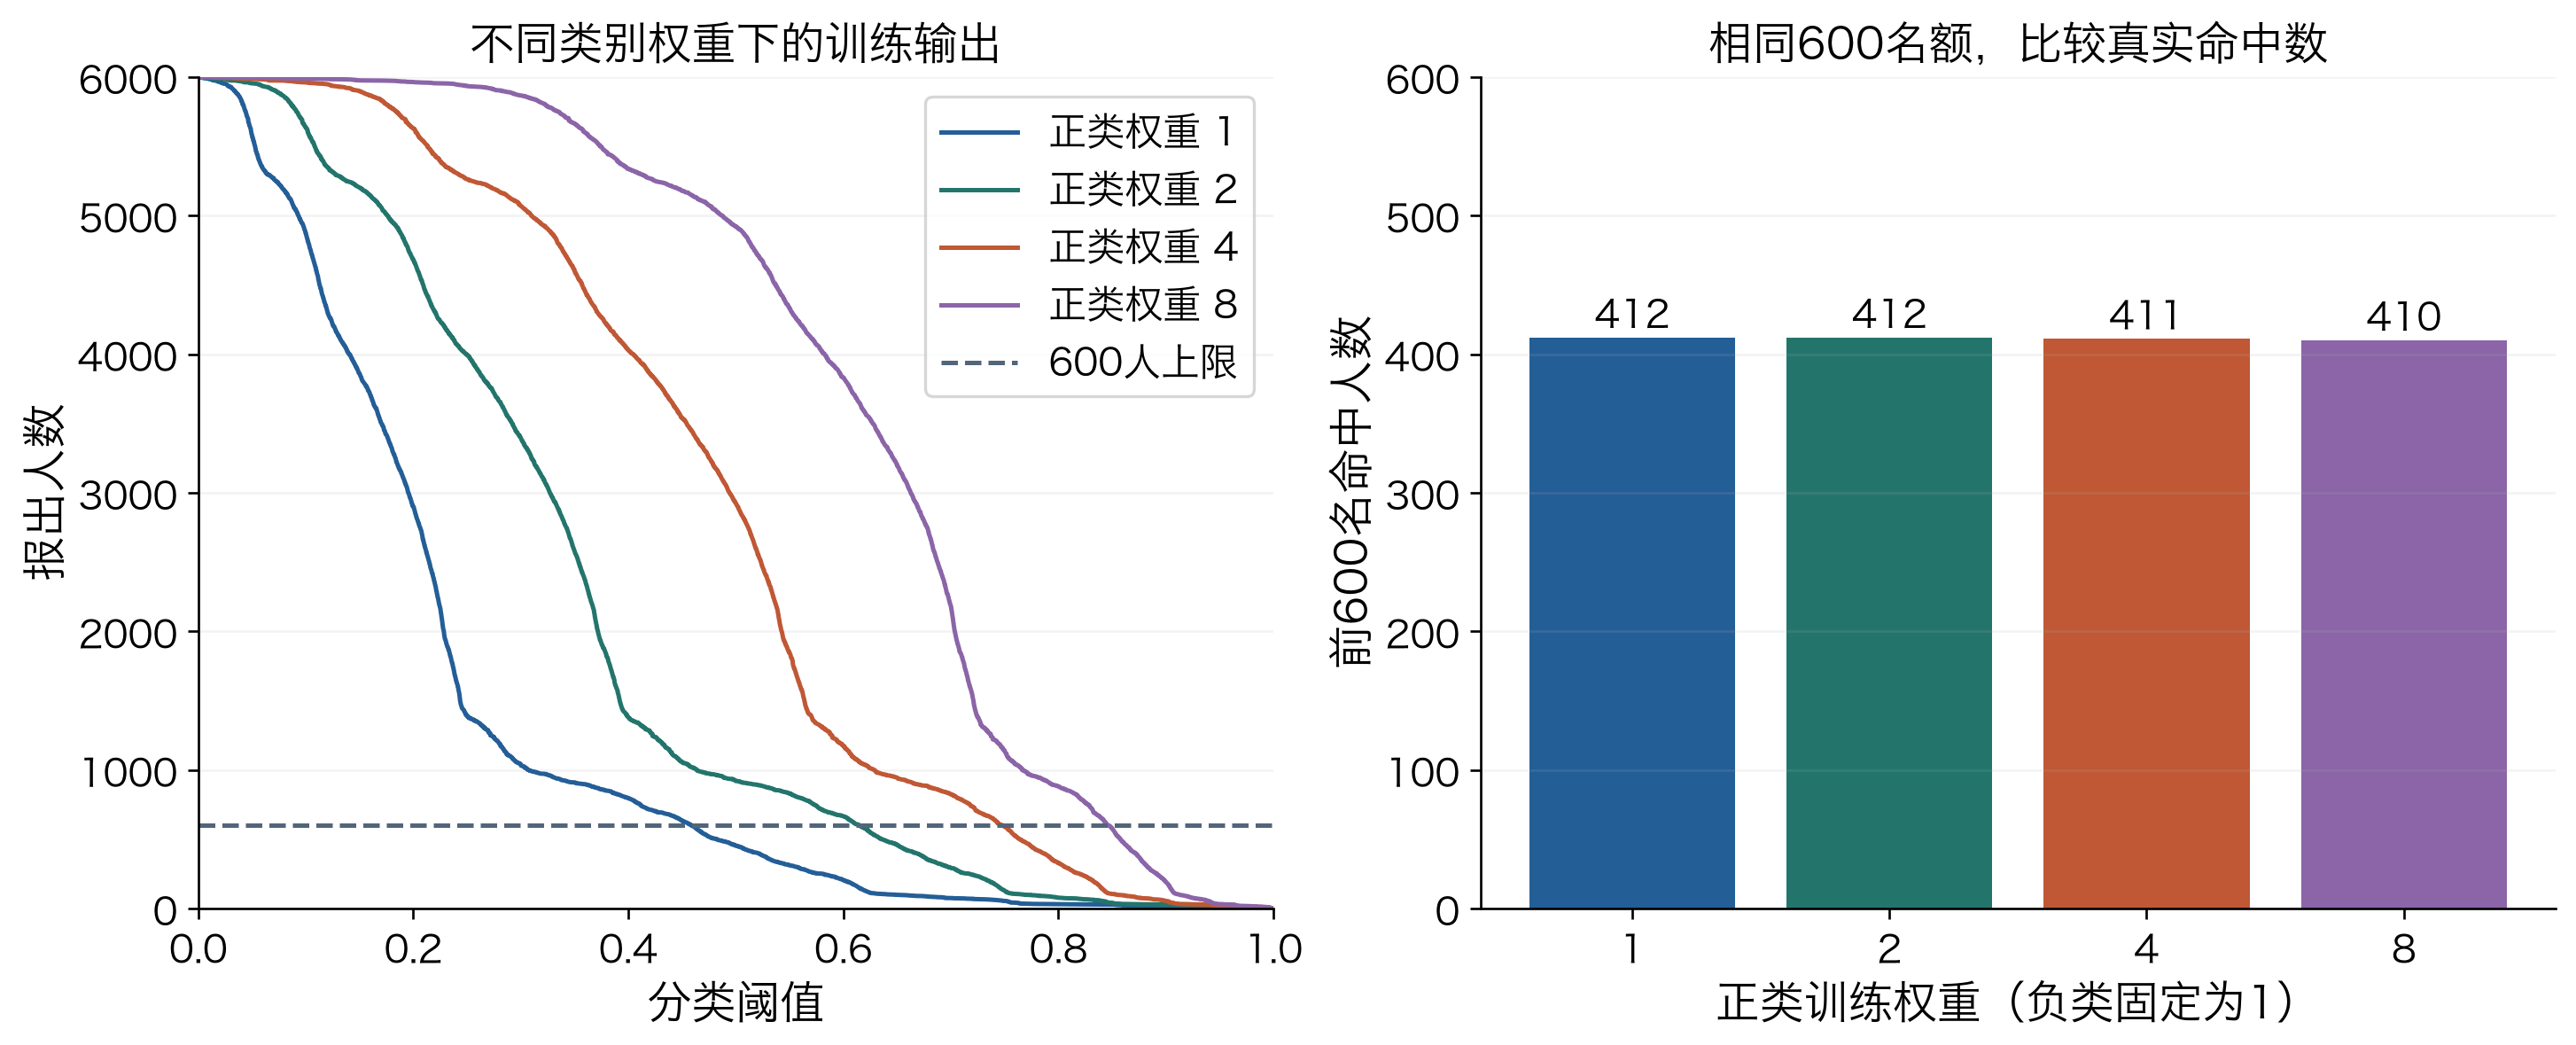

findfont: Failed to find font weight normal, now using 300.


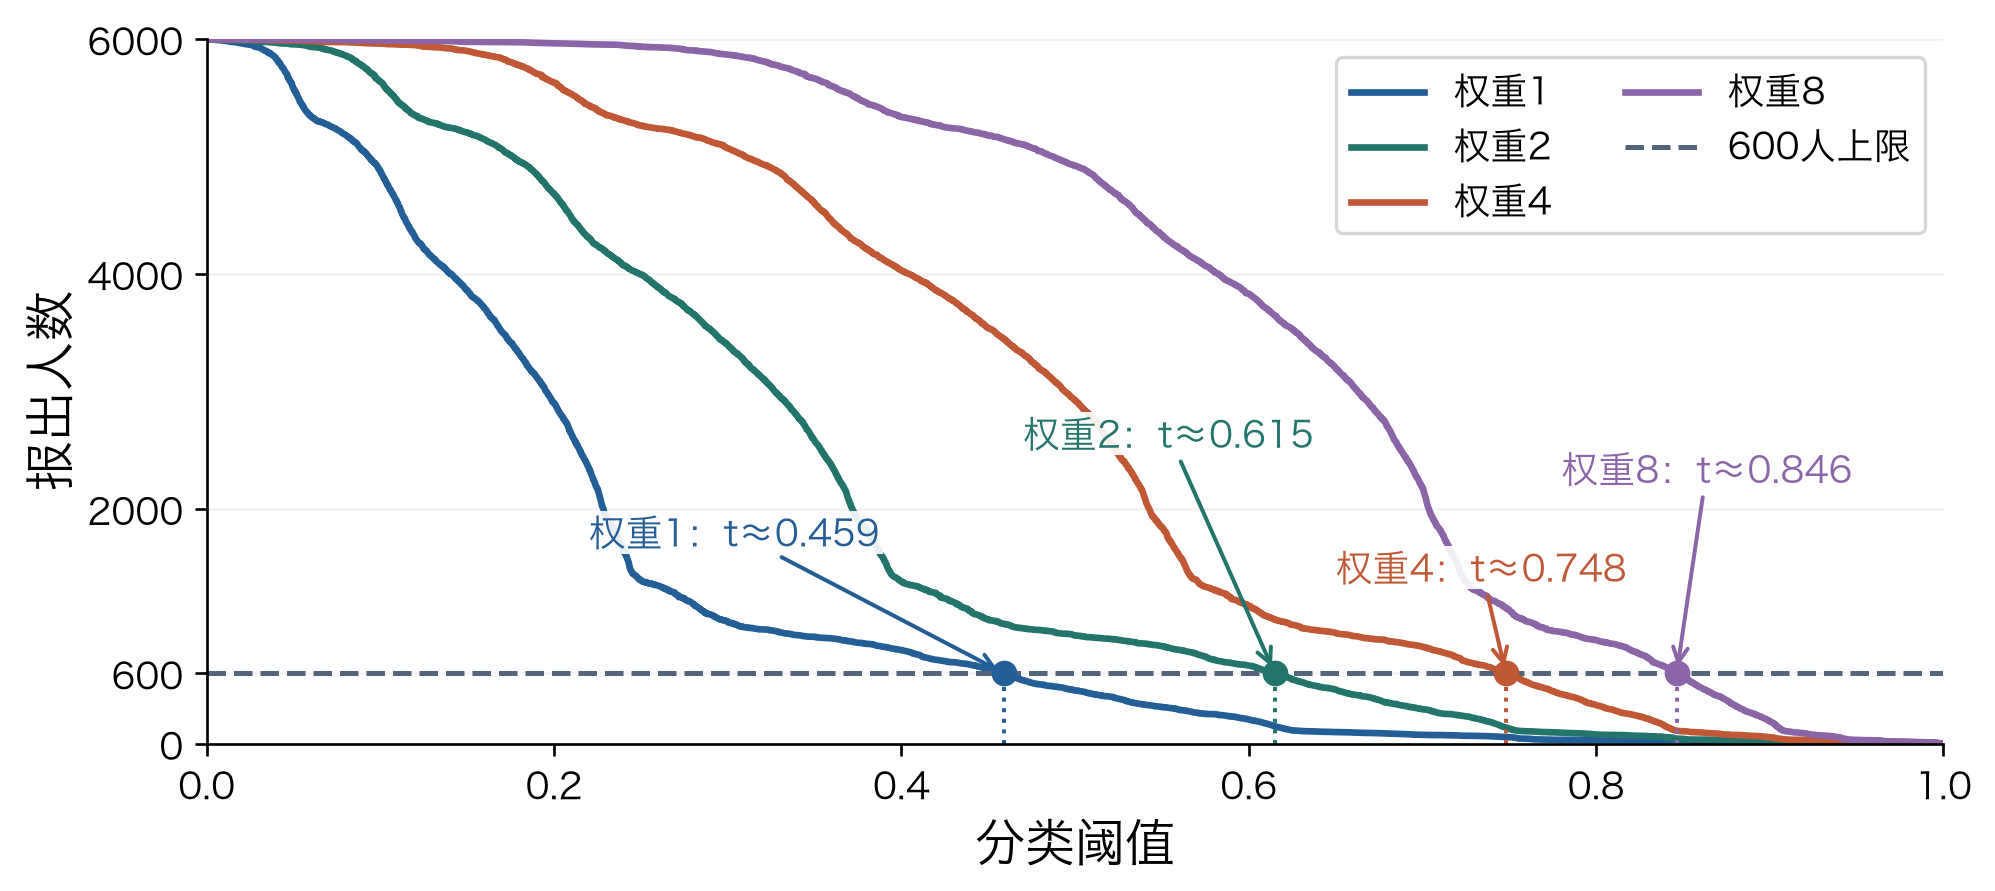

findfont: Failed to find font weight normal, now using 300.


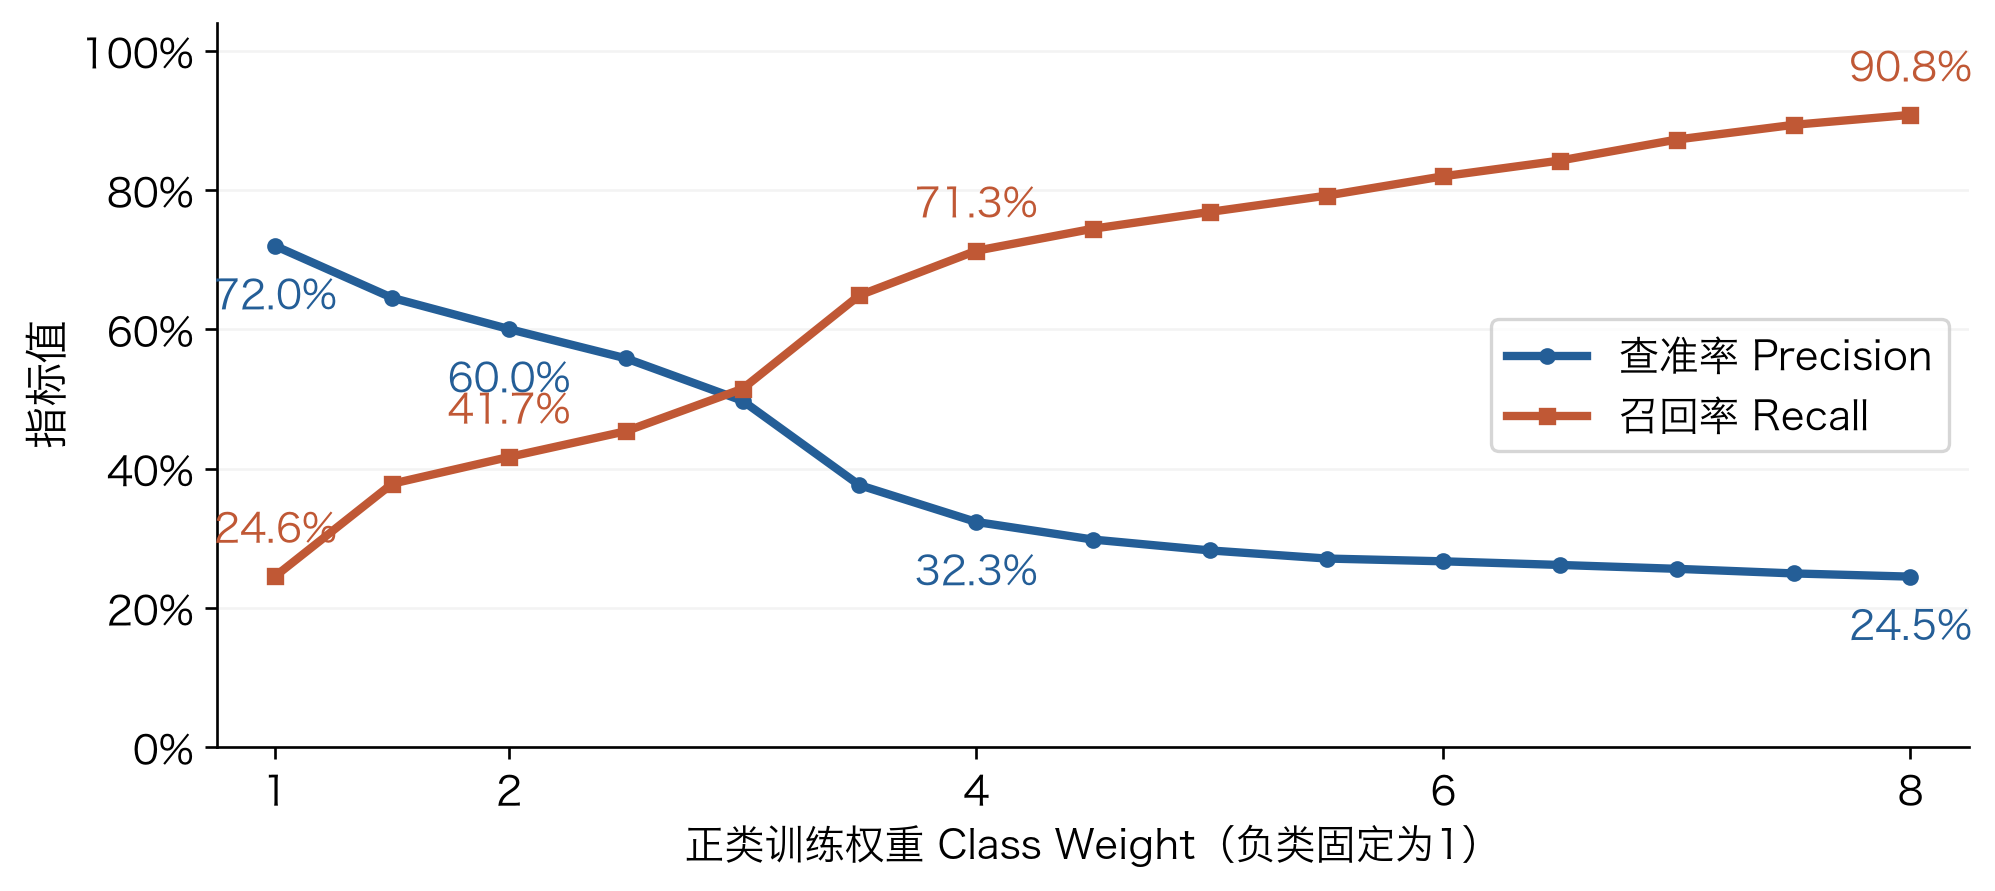

4824

In [56]:
# [ref:l5-weighted-plots]
from helpers.weighted_capacity import plot_weighted_capacity, plot_weighted_rates
plot_weighted_capacity(weighted_curves, weighted_topk, asset_dir / "lab05-weighted-capacity.png")
plot_weighted_rates(weighted_dense, asset_dir / "lab05-weighted-rates.png")
weighted_result = {"protocol": "train18000/valid6000; no test; weights1,2,4,8; C=1; seed42; cost_ratio4; stable validation order ties",
    "dense": weighted_dense.to_dict(orient="records"),
    "default": weighted_default.to_dict(orient="records"),
    "threshold": weighted_threshold.to_dict(orient="records"),
    "topk": weighted_topk.to_dict(orient="records")}
(asset_dir / "lab05-weighted-results.json").write_text(json.dumps(weighted_result, ensure_ascii=False, indent=2))

## 28｜多容量探索｜600、1000、1500、2000人

使用全部15档已训练模型，分别比较恰选前K名、容量内最低代价及名单重合。固定划分结果仍是探索；随后用训练、选择、评价三块数据复核Top-K选择，历史测试行始终排除。

K,600,1000,1500,2000
weight,,,,
1.0,412,581,718,817
1.5,411,581,721,814
2.0,412,581,723,814
2.5,411,580,721,813
3.0,411,580,721,813
3.5,411,580,722,812
4.0,411,579,721,812
4.5,411,579,719,811
5.0,410,579,719,811


,weight,K,threshold,reported,TP,cost
0,1.0,600,0.4592,599.0,412.0,3847.0
1,1.0,1000,0.3074,1000.0,581.0,3403.0
2,1.0,1500,0.2437,1497.0,718.0,3215.0
3,1.0,2000,0.2351,1807.0,788.0,3175.0
4,1.5,600,0.5521,599.0,411.0,3852.0
5,1.5,1000,0.3954,1000.0,581.0,3403.0
6,1.5,1500,0.3258,1499.0,721.0,3202.0
7,1.5,2000,0.3157,1802.0,785.0,3185.0
8,2.0,600,0.6149,600.0,412.0,3848.0
9,2.0,1000,0.4637,998.0,579.0,3411.0


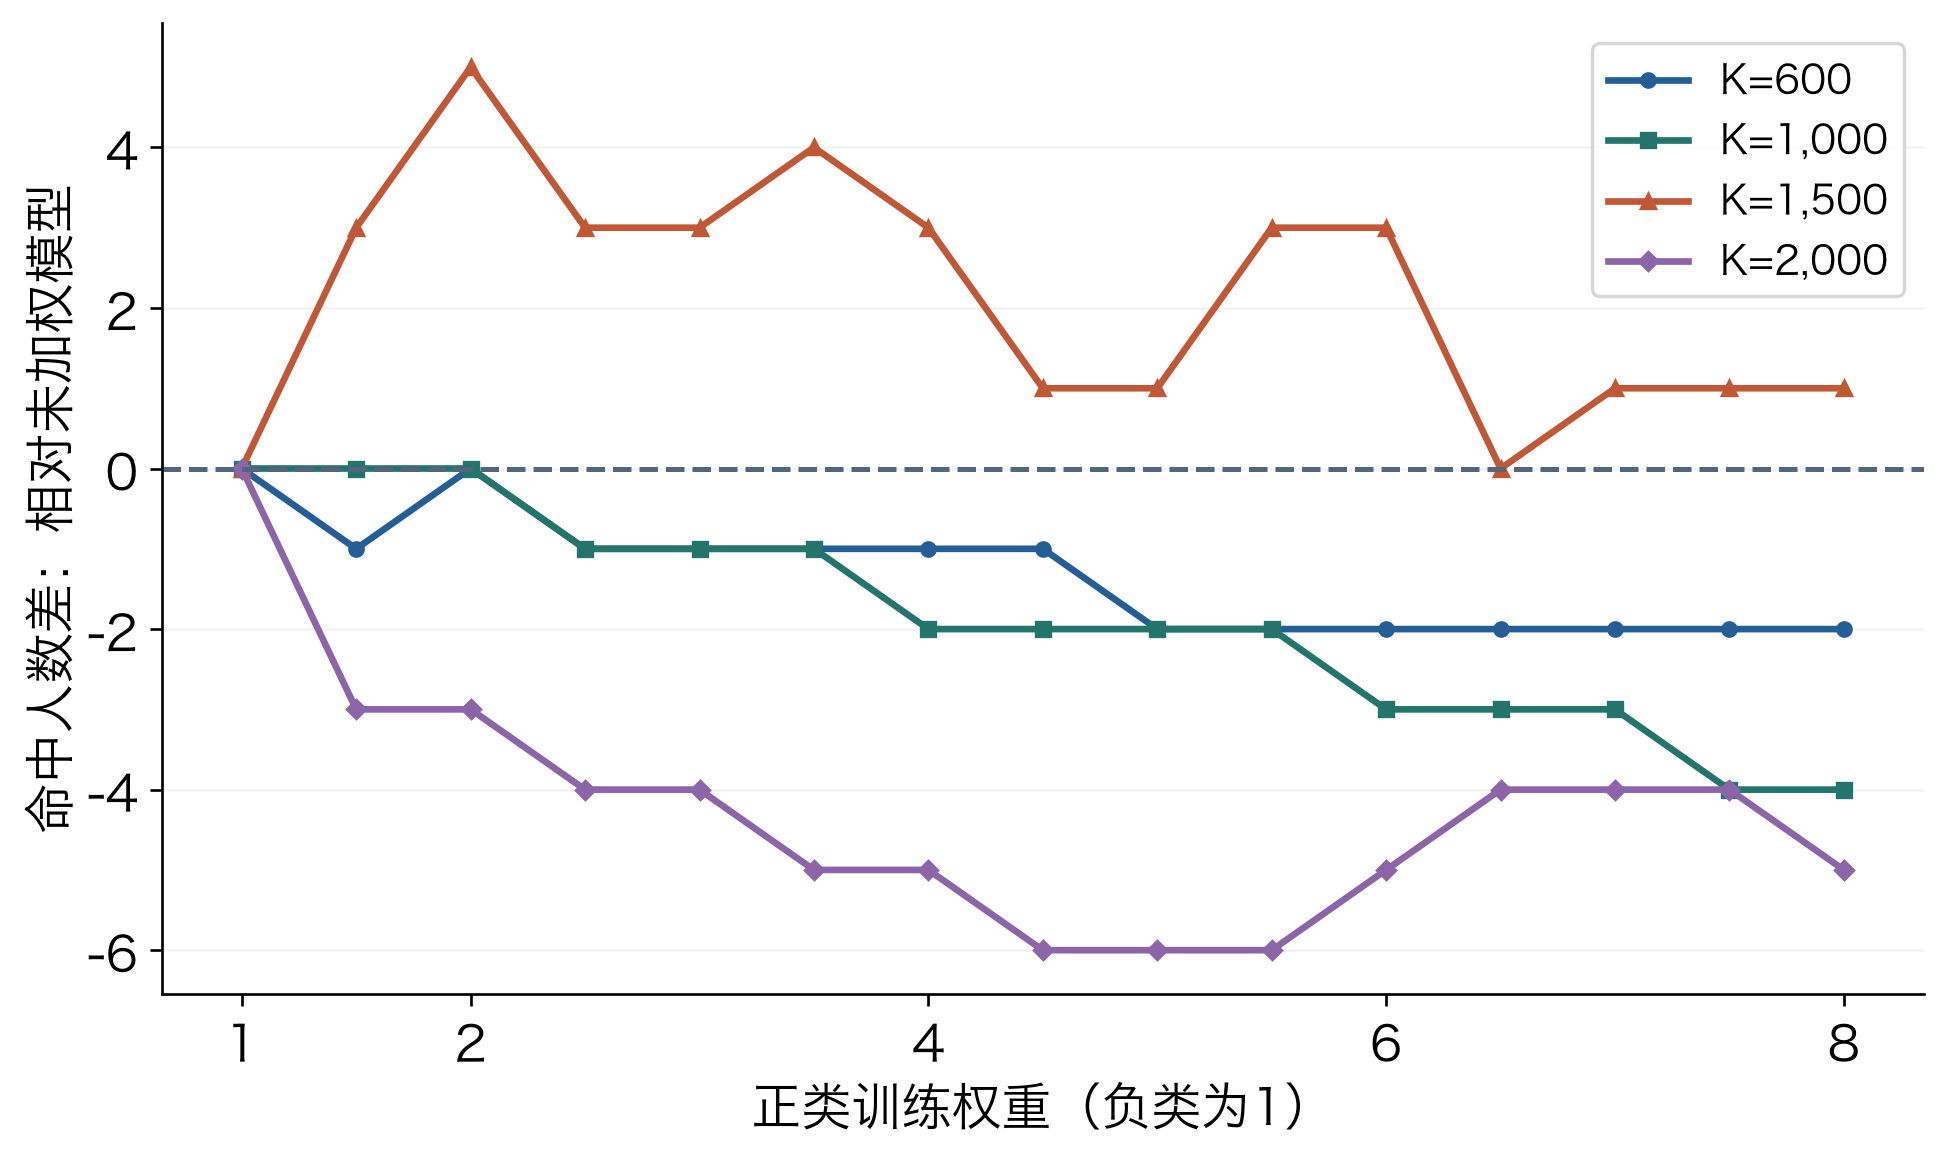

In [57]:
# [ref:l5-weighted-multik]
from helpers.weighted_capacity import evaluate_capacities, plot_capacity_sweep
capacities = [600, 1000, 1500, 2000]
capacity_sweep, cost_sweep = evaluate_capacities(actual, dense_scores, capacities)
display(capacity_sweep.pivot(index="weight", columns="K", values="TP"))
display(cost_sweep[["weight", "K", "threshold", "reported", "TP", "cost"]].round(4))
plot_capacity_sweep(capacity_sweep, asset_dir / "lab05-weighted-multik.png")

In [58]:
# [ref:l5-weighted-capacity-summary]
winner_rows = []
for k, group in capacity_sweep.groupby("K", sort=True):
    base = int(group.loc[group.weight == 1, "TP"].iloc[0])
    best_hits = int(group.TP.max())
    ties = group.loc[group.TP == best_hits, "weight"].tolist()
    winner_rows.append({"容量K": k, "未加权模型命中": base,
        "候选权重最高命中": best_hits, "差值": best_hits-base,
        "并列权重": "、".join(f"{w:g}" for w in ties)})
capacity_winners = pd.DataFrame(winner_rows)
display(capacity_winners)

,容量K,未加权模型命中,候选权重最高命中,差值,并列权重
0,600,412,412,0,1、2
1,1000,581,581,0,1、1.5、2
2,1500,718,723,5,2
3,2000,817,817,0,1


In [59]:
# [ref:l5-weighted-cost-summary]
# 容量相同先比错误代价；并列时取较小训练权重。
cost_winners = (cost_sweep.sort_values(["K", "cost", "weight"])
    .groupby("K", as_index=False).first())
for field in ["K", "reported", "TP", "FP", "FN", "cost"]:
    cost_winners[field] = cost_winners[field].astype(int)
display(cost_winners[["K", "weight", "threshold", "reported", "TP", "FP", "FN", "cost"]])
best_2000 = cost_winners.query("K == 2000").iloc[0]
print("最多2000人的实际执行阈值:", repr(float(best_2000.threshold)))
assert (cost_winners.reported <= cost_winners.K).all()

,K,weight,threshold,reported,TP,FP,FN,cost
0,600,1.0,0.4592,599,412,187,915,3847
1,1000,1.0,0.3074,1000,581,419,746,3403
2,1500,2.0,0.3920,1500,723,777,604,3193
3,2000,4.0,0.5527,1791,786,1005,541,3169


最多2000人的实际执行阈值: 0.5526775781616757


### 代价曲线｜最多2000人

虚线画出完整代价扫描，实线只保留容量内可选部分，空心圆标各模型容量内最低点。图中用1、2、4、8四档代表权重；前面的表比较全部15档。漏报代价比固定为4，没有把训练权重当成业务代价。

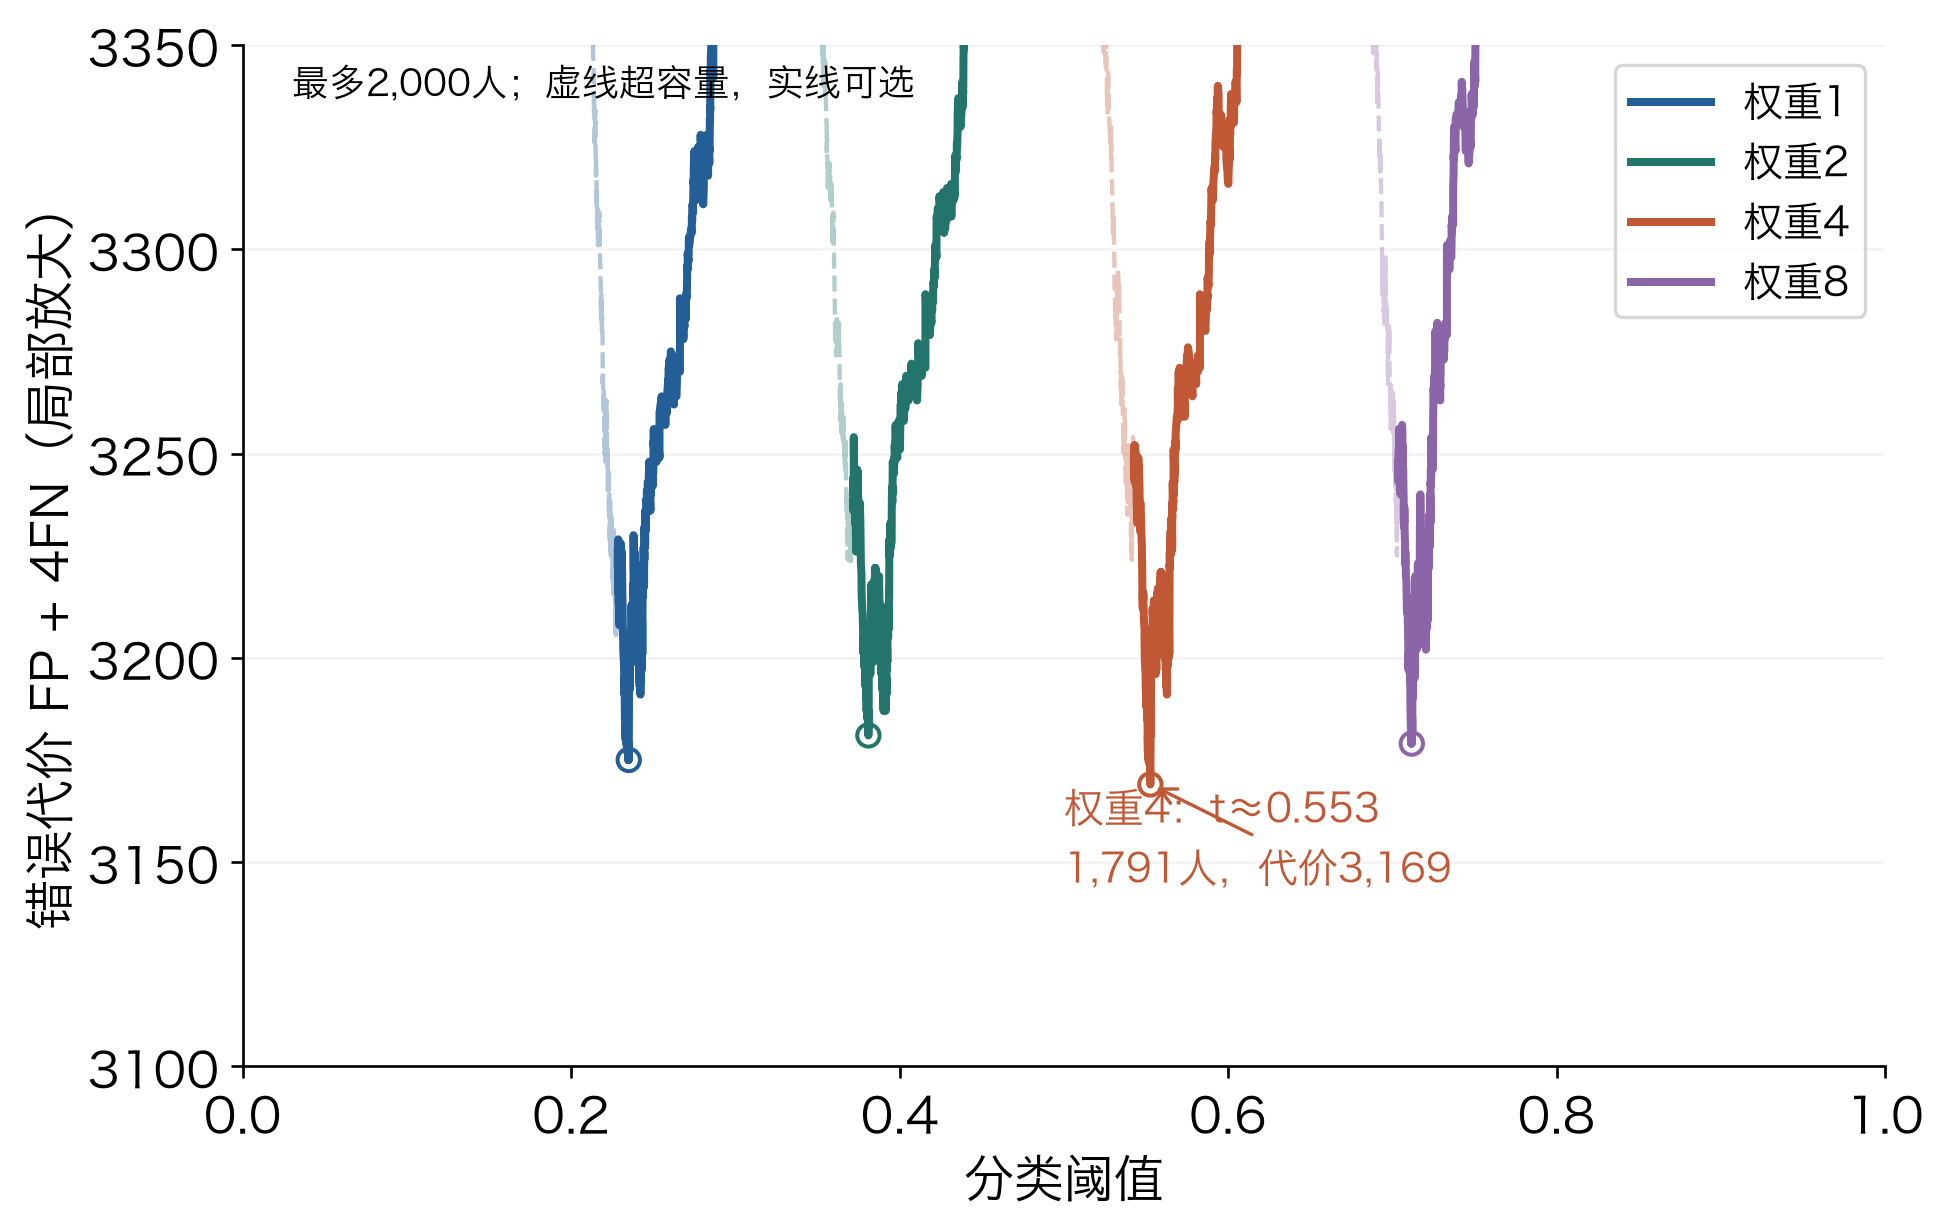

In [60]:
# [ref:l5-weighted-cost-curves]
from helpers.weighted_capacity import plot_weighted_cost_curves
plot_weighted_cost_curves(weighted_curves, asset_dir / "lab05-weighted-cost-curves.png", capacity=2000)

### 名单相似，不等于名单相同

与权重1的前K名单比较：重合人数、换入和换出的真实违约人数。即使命中总数相同，也可能复核了不同客户。

In [61]:
# [ref:l5-weighted-overlap]
display(capacity_sweep[["weight", "K", "TP", "overlap", "overlap_rate", "gained_positive", "lost_positive"]].round(4))
assert (capacity_sweep.gained_positive - capacity_sweep.lost_positive == capacity_sweep.delta_TP).all()

,weight,K,TP,overlap,overlap_rate,gained_positive,lost_positive
0,1.0,600,412,600,1.0000,0,0
1,1.0,1000,581,1000,1.0000,0,0
2,1.0,1500,718,1500,1.0000,0,0
3,1.0,2000,817,2000,1.0000,0,0
4,1.5,600,411,594,0.9900,3,4
5,1.5,1000,581,999,0.9990,0,0
6,1.5,1500,721,1494,0.9960,3,0
7,1.5,2000,814,1995,0.9975,0,3
8,2.0,600,412,590,0.9833,5,5
9,2.0,1000,581,997,0.9970,2,2


### 选读｜稳定性：三次外层划分，选择与评价分开

只用现有24,000条开发记录。每次留6,000条作外层评价；余下18,000条再分12,000训练和6,000选择。15档权重仅由选择集前K命中数选出（同分取较小权重），再在18,000条上重训选中模型，评价外层6,000条。每次另报未加权基线。三次评价集有重叠，不能当作三个独立新数据集；第6讲展开验证协议。

In [62]:
# [ref:l5-weighted-repeat-splits]
from sklearn.model_selection import train_test_split
development_X = credit[feature_names]
development_y = credit[target].astype(int).to_numpy()
development_rows = np.arange(len(credit))
repeat_splits = []
for repeat_seed in [101, 102, 103]:
    outer_train, outer_eval = train_test_split(development_rows, test_size=.25,
        stratify=development_y, random_state=repeat_seed)
    inner_fit, inner_select = train_test_split(outer_train, test_size=1/3,
        stratify=development_y[outer_train], random_state=repeat_seed)
    repeat_splits.append((repeat_seed, inner_fit, inner_select, outer_train, outer_eval))

In [63]:
# [ref:l5-weighted-repeat-select]
selection_choices = []
for repeat_seed, inner_fit, inner_select, outer_train, outer_eval in repeat_splits:
    trial_rows = []
    for weight in sorted(dense_scores):
        trial = make_pipeline(StandardScaler(), LogisticRegression(
            class_weight={0: 1, 1: weight}, max_iter=1000, random_state=SEED))
        trial.fit(development_X.iloc[inner_fit], development_y[inner_fit])
        score = trial.predict_proba(development_X.iloc[inner_select])[:, 1]
        order = np.argsort(-score, kind="stable")
        for k in capacities:
            trial_rows.append(dict(K=k, weight=weight, TP=int(development_y[inner_select][order[:k]].sum())))
    trials = pd.DataFrame(trial_rows)
    for k in capacities:
        winner = trials.query("K == @k").sort_values(["TP", "weight"], ascending=[False, True]).iloc[0]
        selection_choices.append(dict(seed=repeat_seed, K=k, weight=float(winner.weight), selection_TP=int(winner.TP)))
selection_choices = pd.DataFrame(selection_choices)
display(selection_choices)

,seed,K,weight,selection_TP
0,101,600,4.5,419
1,101,1000,1.0,606
2,101,1500,2.5,738
3,101,2000,5.0,832
4,102,600,2.0,424
5,102,1000,1.0,578
6,102,1500,1.0,720
7,102,2000,1.0,827
8,103,600,7.5,410
9,103,1000,7.5,584


In [64]:
# [ref:l5-weighted-repeat-eval]
repeat_rows = []
for repeat_seed, inner_fit, inner_select, outer_train, outer_eval in repeat_splits:
    choices = selection_choices.query("seed == @repeat_seed")
    eval_scores = {}
    for weight in sorted(set(choices.weight) | {1.0}):
        final = make_pipeline(StandardScaler(), LogisticRegression(
            class_weight={0: 1, 1: weight}, max_iter=1000, random_state=SEED))
        final.fit(development_X.iloc[outer_train], development_y[outer_train])
        eval_scores[weight] = final.predict_proba(development_X.iloc[outer_eval])[:, 1]
    for choice in choices.itertuples():
        order = np.argsort(-eval_scores[choice.weight], kind="stable")
        baseline = np.argsort(-eval_scores[1.0], kind="stable")
        hits = int(development_y[outer_eval][order[:choice.K]].sum())
        base_hits = int(development_y[outer_eval][baseline[:choice.K]].sum())
        repeat_rows.append(dict(seed=repeat_seed, K=choice.K, weight=choice.weight,
            selected_TP=hits, baseline_TP=base_hits, delta_TP=hits-base_hits))
repeat_result = pd.DataFrame(repeat_rows)
display(repeat_result)
display(repeat_result.groupby("K")["delta_TP"].agg(["mean", "min", "max"]))

,seed,K,weight,selected_TP,baseline_TP,delta_TP
0,101,600,4.5,395,400,-5
1,101,1000,1.0,575,575,0
2,101,1500,2.5,714,715,-1
3,101,2000,5.0,820,818,2
4,102,600,2.0,404,405,-1
5,102,1000,1.0,581,581,0
6,102,1500,1.0,730,730,0
7,102,2000,1.0,819,819,0
8,103,600,7.5,412,416,-4
9,103,1000,7.5,593,592,1


,mean,min,max
K,,,
600,-3.3333,-5,-1
1000,0.3333,0,1
1500,-0.3333,-1,0
2000,0.6667,0,2


In [65]:
# [ref:l5-weighted-multik-export]
multi_result = dict(capacities=capacities, weights=list(sorted(dense_scores)),
    protocol="fixed valid exploratory; nested selection12000fit/6000select/6000eval; refit18000; seeds101/102/103; no historical test; stable row ties",
    topk=capacity_sweep.to_dict(orient="records"), cost=cost_sweep.to_dict(orient="records"),
    choices=selection_choices.to_dict(orient="records"), repeat=repeat_result.to_dict(orient="records"))
(asset_dir / "lab05-weighted-multik-results.json").write_text(json.dumps(multi_result, ensure_ascii=False, indent=2))

30105

### 分组检查｜同样1500个名额，收益分布在哪里？

用训练集额度三分位点分低、中、高三组；比较权重1与2的前1500名。各组真实违约人数作为Recall分母。分组差异是观察，不推断额度导致了错误；只用当前验证集。

In [66]:
# [ref:l5-weighted-group-coverage]
group_cutpoints = X_fit["LIMIT_BAL"].quantile([1/3, 2/3]).to_numpy()
credit_groups = pd.cut(X_valid["LIMIT_BAL"], [-np.inf, *group_cutpoints, np.inf],
    labels=["低额度", "中额度", "高额度"], right=True).to_numpy()
group_rows = []
for weight in [1, 2]:
    order = np.argsort(-dense_scores[weight], kind="stable")
    chosen = np.zeros(len(actual), dtype=bool)
    chosen[order[:1500]] = True
    for group in ["低额度", "中额度", "高额度"]:
        mask = credit_groups == group
        positives = int(actual[mask].sum())
        hits = int(actual[mask & chosen].sum())
        group_rows.append(dict(weight=weight, group=group, n=int(mask.sum()),
            positive=positives, reported=int((mask & chosen).sum()), TP=hits, Recall=hits/positives))
group_coverage = pd.DataFrame(group_rows)
assert group_coverage.groupby("weight").reported.sum().eq(1500).all()
display(group_coverage.round(4))
(asset_dir / "lab05-weighted-group-results.json").write_text(group_coverage.to_json(orient="records", force_ascii=False, indent=2))

,weight,group,n,positive,reported,TP,Recall
0,1,低额度,2138,645,833,422,0.6543
1,1,中额度,1931,402,446,201,0.5000
2,1,高额度,1931,280,221,95,0.3393
3,2,低额度,2138,645,844,427,0.6620
4,2,中额度,1931,402,443,201,0.5000
5,2,高额度,1931,280,213,95,0.3393


810

### 选读｜按训练额度三分位观察错误

只用训练集 `LIMIT_BAL` 的1/3与2/3分位数确定切点。最外边界延伸为负无穷与正无穷，覆盖验证集所有额度。验证客户按这些固定区间分组，统计人数n、实际正类数positives、误报FP和漏报FN；LR仍用阈值0.5。

组大小与正类率可能不同，比较错误人数时一起看分母。这是当前验证集的描述，不能说明额度导致错误或模型对某群体有因果影响。

In [67]:
# [ref:l5-error-group-bins]
amount_cuts = X_fit["LIMIT_BAL"].quantile([1/3, 2/3]).to_numpy()
amount_edges = np.r_[-np.inf, amount_cuts, np.inf]
amount_groups = pd.cut(X_valid["LIMIT_BAL"], bins=amount_edges,
                       labels=["低额度", "中额度", "高额度"], right=True)
print("训练集额度三分位切点:", amount_cuts)
print("分组区间: (-inf,切点1]、(切点1,切点2]、(切点2,+inf]")
# 核对固定额度区间覆盖全部验证客户。
assert amount_groups.notna().all()

训练集额度三分位切点: [ 80000. 200000.]
分组区间: (-inf,切点1]、(切点1,切点2]、(切点2,+inf]


In [68]:
# [ref:l5-error-groups]
error_frame = pd.DataFrame({"group": amount_groups.array, "y": actual,
    "FP": ((actual == 0) & (pred_lr == 1)).astype(int),
    "FN": ((actual == 1) & (pred_lr == 0)).astype(int)})
error_groups = error_frame.groupby("group", observed=False).agg(
    n=("y", "size"), positives=("y", "sum"), FP=("FP", "sum"), FN=("FN", "sum")).reset_index()
display(error_groups)
# 核对各额度组人数合计为6,000。
assert error_groups["n"].sum() == 6000
# 核对分组误报与漏报合计和总体计数一致。
assert error_groups["FP"].sum() == fp and error_groups["FN"].sum() == fn

,group,n,positives,FP,FN
0,低额度,2138,645,93,429
1,中额度,1931,402,32,310
2,高额度,1931,280,2,262


🧮 哪组漏报人数更多？各组真实正类人数是否相同？先核对表中分母，再说明本次观察；不要从这张表推断额度的因果作用。

本次三组的FP分别为93、32、2，FN分别为429、310、262；低、中、高额度的真实正类人数分别为645、402、280。错误人数较少不等于组内错误率一定更低。

## 29｜指标关系：先明确要评价什么

| 评价对象 | 指标 | 输入和主要问题 |
|---|---|---|
| 分类结果 | Accuracy、Precision、Recall（TPR）、FPR | 阈值后的标签：整体对多少、名单准不准、正类找回多少、负类误报多少 |
| 排序 | ROC-AUC、AP | 分数顺序：正类是否排在前面；AP还受正类比例影响 |
| 概率 | ECE、Brier Score、Log Loss | 概率数值：分组是否相称、整体预测误差多大 |
| 决策 | P@K、R@K、FP+rFN | 给定容量和代价，最终名单是否满足目标 |

只调阈值时，预测分数保持，AUC/AP和概率评分不变；严格递增变换保持排序，概率评分可能改变；类别加权需要重训，各类指标都要重新评价。

## 30｜课堂练习：恰选人数与最低代价

比较两份课件名单：A为未加权模型恰选前2,000名；B为最多2,000人、$\mathrm{FP}+4\mathrm{FN}$最低的候选规则。先看人数约束，再看目标。下面直接从已计算结果构造表格。

In [69]:
# [ref:l5-list-exercise]
list_a = capacity_sweep.query("weight == 1 and K == 2000").iloc[0]
decision_table = pd.DataFrame([
    dict(名单="A：未加权前2000名", 人数=2000, TP=int(list_a.TP)),
    dict(名单="B：容量内最低代价", 人数=int(best_2000.reported), TP=int(best_2000.TP)),
])
decision_table["FP"] = decision_table["人数"] - decision_table["TP"]
decision_table["FN"] = int(actual.sum()) - decision_table["TP"]
decision_table["FP+4FN"] = decision_table["FP"] + 4 * decision_table["FN"]
display(decision_table)

,名单,人数,TP,FP,FN,FP+4FN
0,A：未加权前2000名,2000,817,1183,510,3223
1,B：容量内最低代价,1791,786,1005,541,3169


**读结果**：A多命中31名违约客户；B的错误代价低54，且只报出1,791人。若必须恰选2,000人，B不满足人数要求；若允许少选并最小化当前错误代价，两份候选中B更合适。

业务代价里的4乘的是漏报次数，定义预测后的评价目标；`class_weight={0:1,1:4}`乘的是所有真实正类的训练交叉熵损失，引导学习倾向。两者不等价。

## 31｜课末检测与实验作业

📝 同一模型只改变阈值，Accuracy、Recall、ROC-AUC和Brier Score中哪些可能变化？

📝 在当前验证集发现权重2多命中5人，能确认它在未来更好吗？用选读中的选择后评价说明下一步如何核对。

**提交三份证据**：① 原概率与单调变换后的AUC、AP、Brier、Log Loss对照；② 15档权重在600／1000／1500／2000四种容量下的未加权命中、候选最高命中及并列权重；③ 最多2,000人、FP+4FN最低的权重、实际阈值、人数和TP/FP/FN。

完整要求见本讲`assignment.md`；分组与重复划分为选做。人数约束、真实正类总人数和业务代价比均需写明。引用保存输出即可，不要求逐行重算。

## 32｜选读｜课件图与证据导出

主线图已在各节展示；下面只生成课件单面板素材和可追溯的结果汇总。

findfont: Failed to find font weight normal, now using 300.


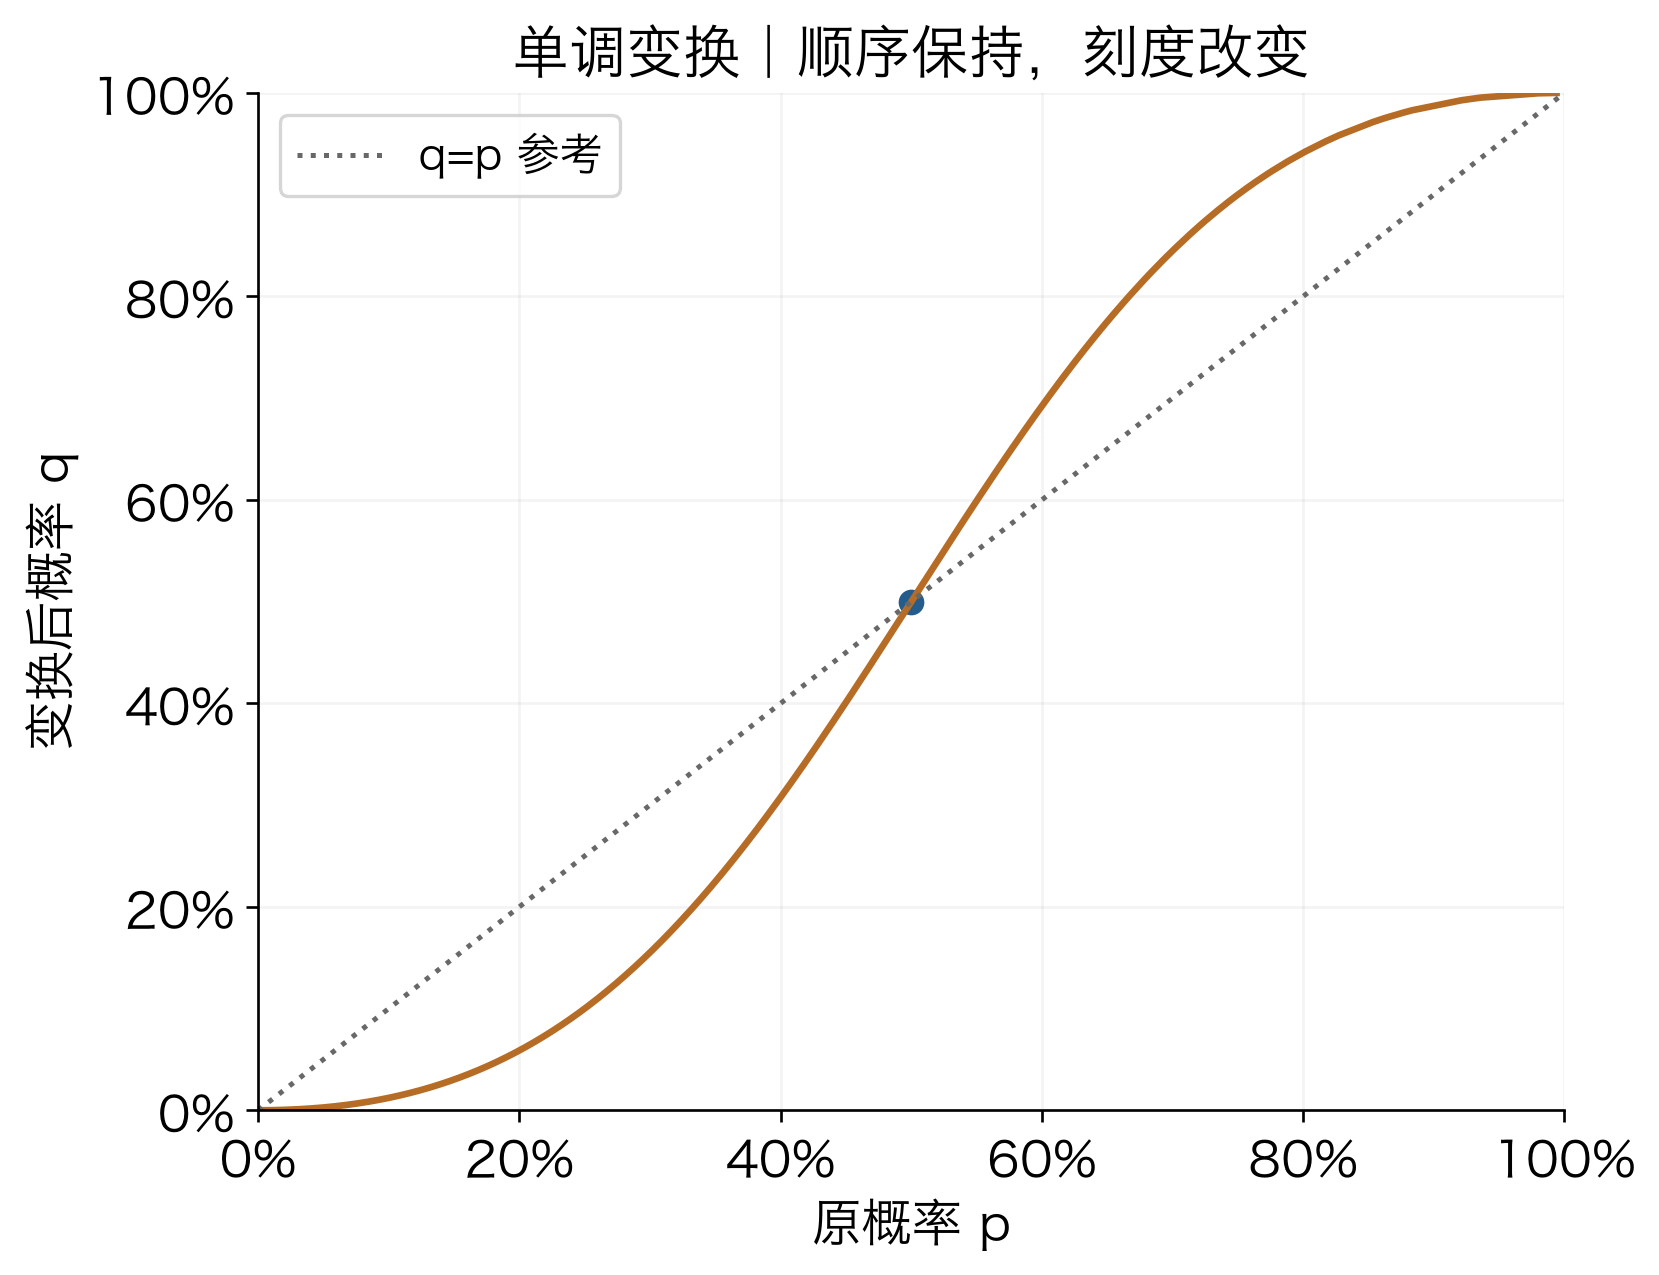

findfont: Failed to find font weight normal, now using 300.


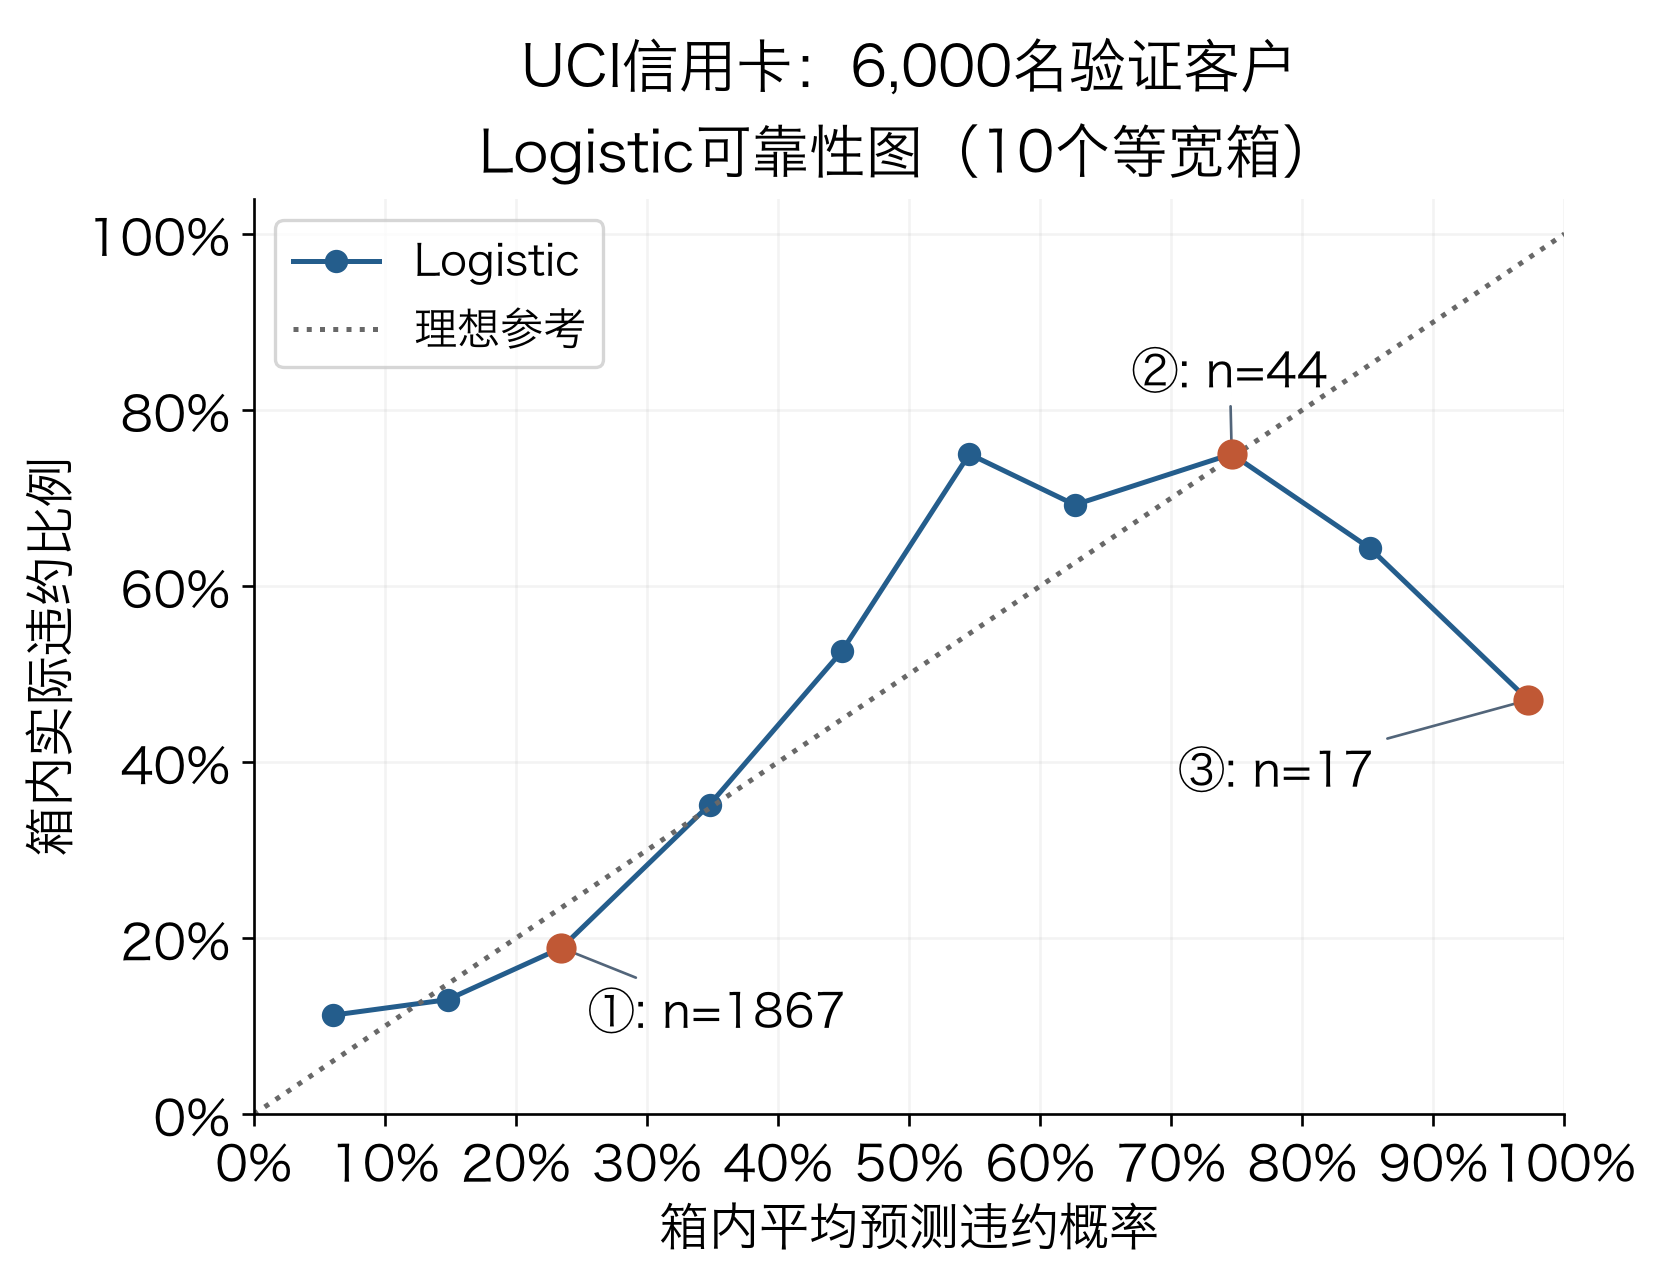

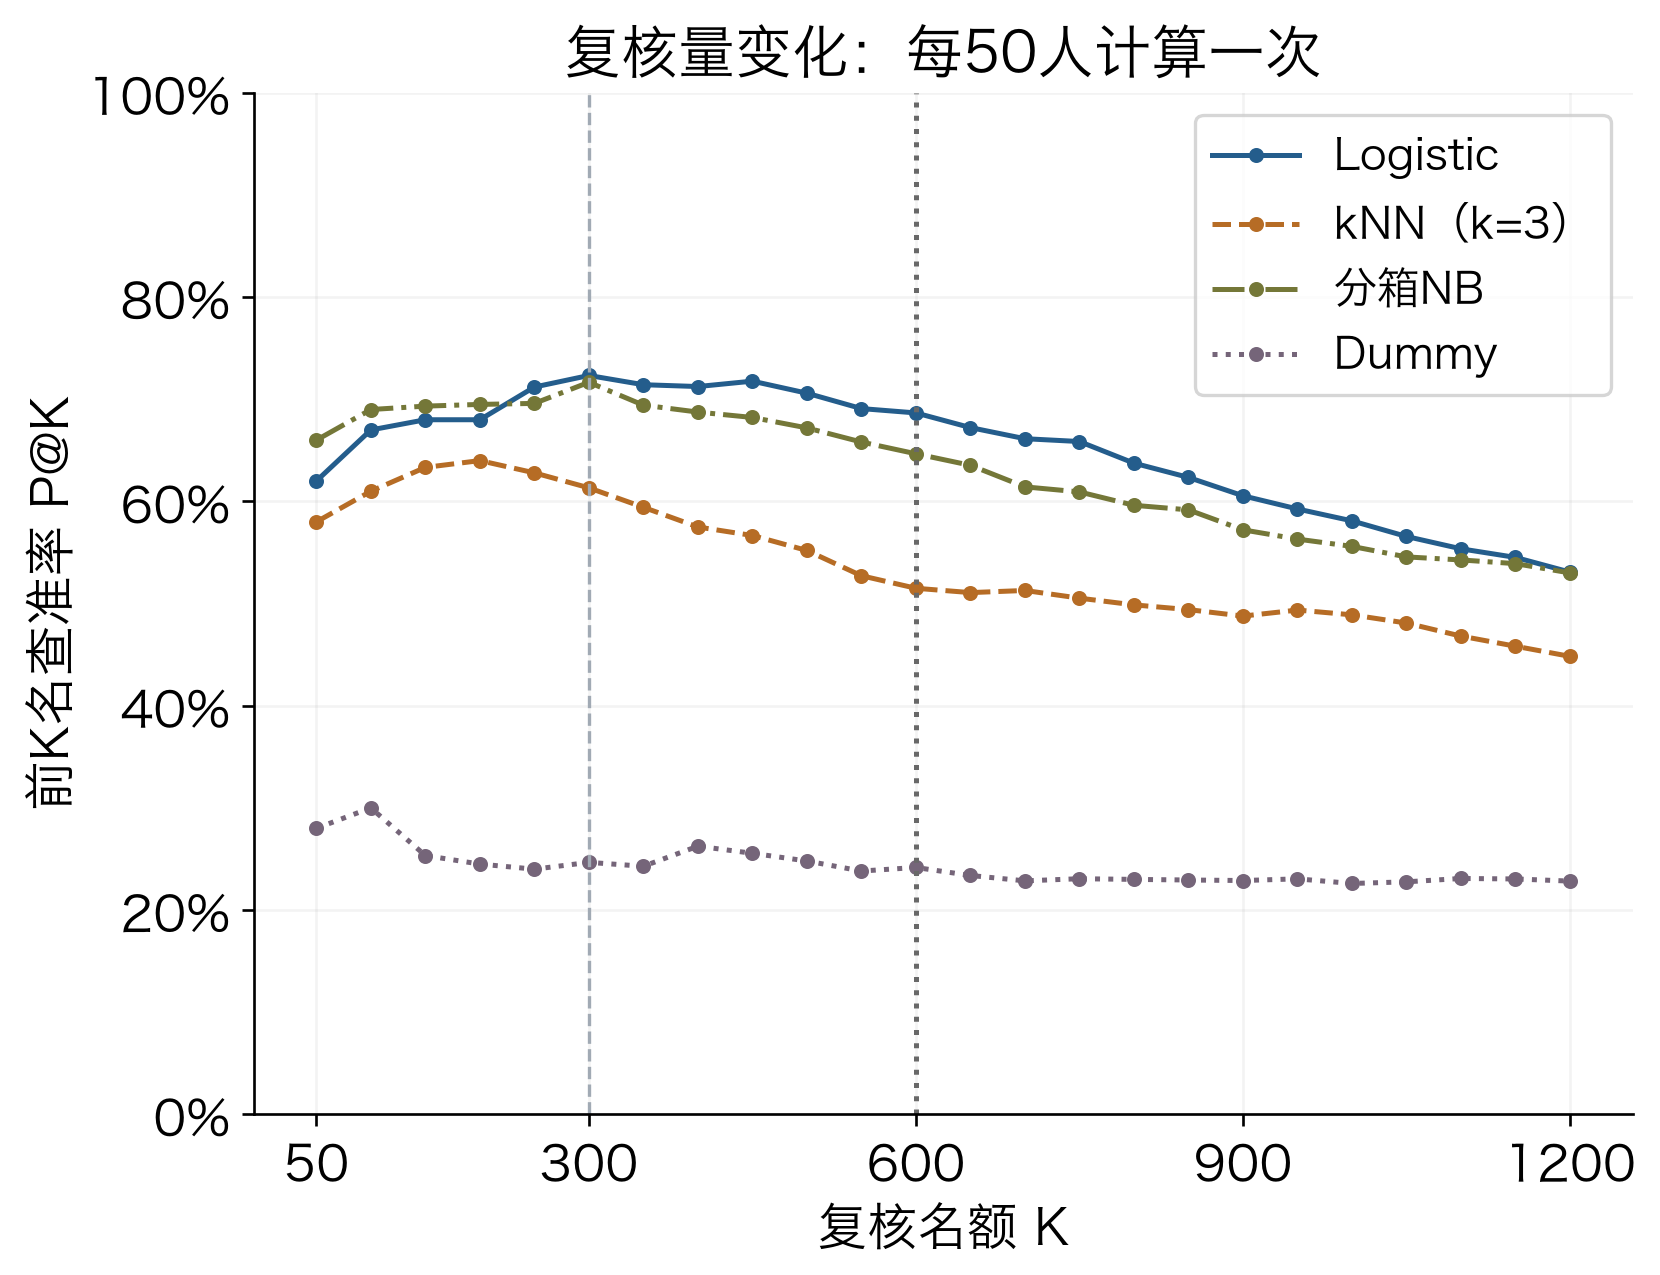

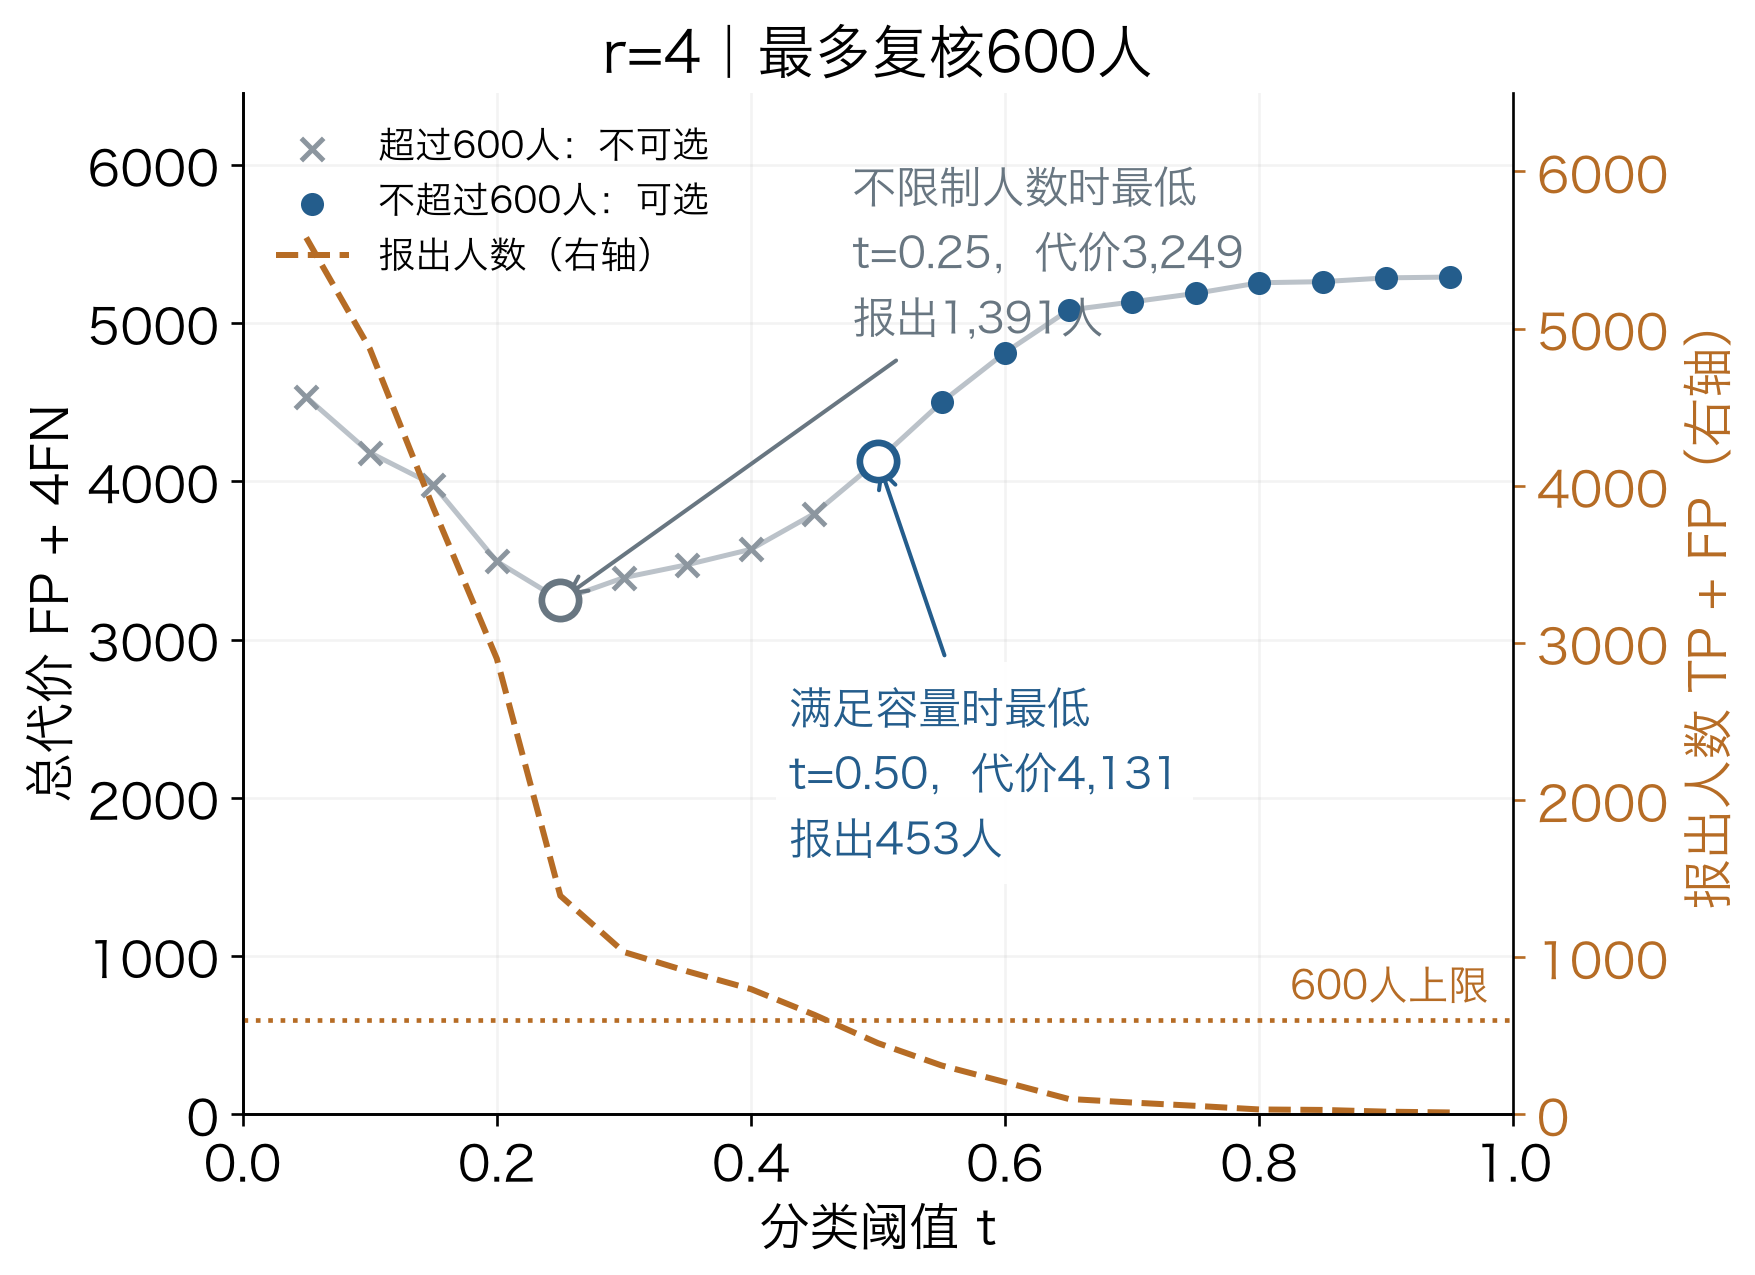

In [70]:
# 课件采用单面板版，完整多面板图仍保留在上方。
# 仅为课件曲线增加名额点，主线K=600表保持不变。
capacity_curve_rows = []
for name, p in scores.items():
    order = np.argsort(-p, kind="stable")
    cumulative_hits = np.cumsum(actual[order])
    for k in range(50, 1201, 50):
        capacity_curve_rows.append({"model": name, "k": k, "precision_at_k": cumulative_hits[k-1] / k})
capacity_curve_table = pd.DataFrame(capacity_curve_rows)
plot_slide_views(p_lr, p_changed, calibration_tables, capacity_curve_table, cost_table, cost_best, asset_dir)


### 导出汇总（可选）

JSON保存原始精度数值、语义anchors、运行版本及口径，供课件核对。使用Python标准库即可，Windows也能运行。默认导出本章 `lab05-evaluation-summary.json`；设 `EXPORT_SUMMARY=False` 可以只在内存查看。只更新本章新汇总，不改旧素材。每个模型的 `capacity_at_600` 对应同一6,000行验证集。

统一汇总包含类别权重、四种容量、选择后评价、分组覆盖及两份课堂名单；独立JSON继续保留，便于单项核对。

课程维护者更新阅读版时，运行 `.venv/bin/python scripts/export_lesson05_reading.py`。该脚本保留已执行输出，将Markdown公式转换为原生MathML；阅读版离线显示公式无需外部CDN。Jupyter中的源Notebook继续使用标准LaTeX公式。

In [71]:
anchors = {'four-roc': 'l5-four-roc', 'confusion': 'l5-confusion', 'four-samples': 'l5-four-samples', 'four-thresholds': 'l5-four-thresholds', 'auc-pairs': 'l5-auc-pairs', 'partition': 'l5-partition', 'data': 'l5-data', 'lr': 'l5-lr', 'probabilities': 'l5-probabilities', 'roc': 'l5-roc', 'pr': 'l5-pr', 'ap': 'l5-ap', 'monotonic-transform': 'l5-monotonic-transform', 'monotonic': 'l5-monotonic', 'calibration': 'l5-calibration', 'calibration-counts': 'l5-calibration-counts', 'base-rate': 'l5-base-rate', 'ranking': 'l5-ranking', 'capacity': 'l5-capacity', 'capacity-lr': 'l5-capacity-lr', 'cost': 'l5-cost', 'knn': 'l5-knn', 'nb-preprocess': 'l5-nb-preprocess', 'nb': 'l5-nb', 'dummy': 'l5-dummy', 'model-comparison': 'l5-model-comparison', 'capacity-comparison': 'l5-capacity-comparison', 'capacity-ties': 'l5-capacity-ties', 'error-group-bins': 'l5-error-group-bins', 'error-groups': 'l5-error-groups', 'summary': 'l5-summary'}
models_summary = metrics_table.to_dict(orient="index")
for name in models_summary:
    row = capacity_table.query("model == @name and k == 600").iloc[0].drop("model")
    models_summary[name]["capacity_at_600"] = row.to_dict()
calibration_summary = {name: json.loads(table.reset_index().to_json(orient="records")) for name, table in calibration_tables.items()}
anchors.update({"weighted-fit": "l5-weighted-fit", "weighted-dense": "l5-weighted-dense",
    "weighted-multik": "l5-weighted-multik", "weighted-repeat": "l5-weighted-repeat-eval",
    "weighted-groups": "l5-weighted-group-coverage", "decision-lists": "l5-list-exercise"})
print("待导出模型:", list(models_summary), "语义锚点数:", len(anchors))

待导出模型: ['LR', 'kNN3', 'binnedCategoricalNB', 'Dummy'] 语义锚点数: 37


In [72]:
summary = {"schema_version": 1, "anchors": anchors, "models": models_summary,
    "four_sample": {"scores": demo_p.tolist(), "labels": demo_y.tolist(), "threshold_table": demo_table.to_dict("records"),
        "roc_auc": demo_auc, "ap": average_precision_score(demo_y, demo_p), "pair_credit": pair_credit.tolist(), "tie_credit": .5},
    "monotonic": {"transform": "sigmoid(2*logit(p))", "metrics": monotonic_table.to_dict("index"), "ranking_preserved": True},
    "calibration": {"binning": "10 equal-width bins; last bin includes 1", "tables": calibration_summary, "n_is_confidence_interval": False},
    "base_rate": {"is_real_uci_deployment": False, "scenarios": base_rate_table.to_dict("records")},
    "capacity": {"rows": capacity_table.to_dict("records"), "ties": tie_table.to_dict("records"), "tie_rule": "stable descending; validation row order"},
    "cost": {"model": "LR", "formula": "FP+r*FN", "rows": cost_table.to_dict("records"), "best": cost_best.to_dict("records")}}
summary["error_groups"] = {"model": "LR", "threshold": .5, "feature": "LIMIT_BAL",
    "train_tertile_cuts": amount_cuts.tolist(), "bins": "training tertiles; outer edges -inf/+inf",
    "table": error_groups.to_dict("records"), "interpretation": "validation observation, not causal effect"}
summary["weighted"] = weighted_result
summary["weighted_multik"] = multi_result
summary["weighted_groups"] = group_coverage.to_dict("records")
summary["capacity_winners"] = capacity_winners.to_dict("records")
summary["cost_winners"] = cost_winners.to_dict("records")
summary["decision_lists"] = decision_table.to_dict("records")
print("汇总字段:", list(summary))

汇总字段: ['schema_version', 'anchors', 'models', 'four_sample', 'monotonic', 'calibration', 'base_rate', 'capacity', 'cost', 'error_groups', 'weighted', 'weighted_multik', 'weighted_groups', 'capacity_winners', 'cost_winners', 'decision_lists']


In [73]:
summary["protocol"] = {"seed": SEED, "fit_n": 18000, "validation_n": 6000, "historical_test_n": 6000,
    "test_labels_read_by_notebook": False, "test_evaluated": False, "use": "training/validation teaching exploration",
    "features": feature_names, "classification_threshold": .5, "validation_positive_n": int(actual.sum()),
    "validation_positive_rate": positive_rate, "sklearn_version": sklearn.__version__, "python_version": sys.version.split()[0],
    "brier_scale_by_half": True, "ap_is_trapezoidal_pr_auc": False, "dummy_strategy": "prior",
    "nb": {"bins": 5, "actual_bins": nb[0].named_transformers_["bins"].n_bins_.astype(int).tolist(), "alpha": 1,
           "quantile_method": "averaged_inverted_cdf"}, "development_data_sha256": hashlib.sha256(credit.to_csv().encode()).hexdigest(),
    "partition_sha256": partition["sha256"], "elapsed_seconds": time.perf_counter() - started}
print("训练/验证口径:", summary["protocol"]["use"])

训练/验证口径: training/validation teaching exploration


In [74]:
# [ref:l5-summary]
EXPORT_SUMMARY = True  # 可设为False，保留内存中的summary
summary_path = asset_dir / "lab05-evaluation-summary.json"
if EXPORT_SUMMARY:
    if not summary_path.parent.is_dir():
        raise FileNotFoundError("本章assets目录不存在，请检查课程目录结构")
    summary_path.write_text(json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8")
    print("汇总已保存:", summary_path)
print("计算耗时:", round(time.perf_counter() - started, 1), "秒")

汇总已保存: /Users/momo/Documents/workspace/教学/2026机器学习与概率统计-本科/lessons/05-metrics-cost/assets/lab05-evaluation-summary.json
计算耗时: 6.0 秒


### 资料与边界

官方口径核查日期：2026-10-06，本地scikit-learn 1.9.0。

- [UCI数据与许可证](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients)，本地数据卡 `data/README.md`。
- [分类与概率指标](https://scikit-learn.org/stable/modules/model_evaluation.html)，AP按召回增量加权。
- [概率校准说明](https://scikit-learn.org/stable/modules/calibration.html)，Brier不等于纯校准度量。
- [CategoricalNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.CategoricalNB.html)，[KBinsDiscretizer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.KBinsDiscretizer.html)。

结果来自旧数据和重复使用的验证集，只支持本章教学比较。公式渲染由Notebook阅读环境提供，metadata不加载远端CDN。